In [1]:
import ast
import polars as pl
import os
from sklearn.metrics import auc
from itertools import combinations
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.ticker as mtick

In [2]:
# Configuration
N_VERSIONS = range(11,16)
BASE_PATH = "logs/"

In [3]:
for i in N_VERSIONS: print(i)

11
12
13
14
15


# Pan-cancer

In [4]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    #print(df.columns)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col(column).max().alias(f"max_{column}"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)

    return all_data


def safe_literal_eval(s):
    try:
        return ast.literal_eval(s)
    except (ValueError, SyntaxError, TypeError):
        return {}

def compute_aupc(source_file, version, metric="max_Roc_auc"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    df_baseline = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", 'max_test_accuracy'])
    df_baseline = df_baseline.filter(pl.col("train_samples") < 1000)
    df_baseline = (df_baseline.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df_baseline['train_samples'].max()).alias("train_samples")))
    #print(df_baseline)
    mauc = auc(df_baseline['train_samples'], df_baseline['max_test_accuracy'])
    return mauc

In [17]:
auc_baseline = compute_aupc('train_cancer_model_linspaceBRCA_training', version=N_VERSIONS)

Fichier manquant : ../../logs/train_cancer_model_linspaceBRCA_training/version_range(11, 16)/metrics.csv


FileNotFoundError: No such file or directory (os error 2): ../../logs/train_cancer_model_linspaceBRCA_training/version_range(11, 16)/metrics.csv

In [18]:
auc_baseline

NameError: name 'auc_baseline' is not defined

In [22]:
auc_finetune = compute_aupc('cancer_model_to_cancer_model_withoutBRCA', version=N_VERSIONS)

../../logs/cancer_model_to_cancer_model_withoutBRCA/version_10/metrics.csv


In [23]:
auc_finetune

np.float64(0.7048497942386831)

In [56]:
def compute_macc(baseline, model_task, cancer='', v=0, metric="max_test_accuracy"):
    baseline_str = 'train_' + baseline + '_linspace' + cancer + '_training'
    finetuned_str = model_task + '_to_cancer_model_without' + cancer
    auc_baseline = compute_aupc(baseline_str, version = v, metric=metric)
    auc_finetuned = compute_aupc(finetuned_str, version = v, metric=metric)
    return auc_finetuned - auc_baseline, auc_finetuned, auc_baseline

In [87]:
compute_macc(baseline='cancer_model', model_task='cancer_model', cancer='LUSC', v=10, metric="Roc_auc")

(np.float64(-0.03815136476426806),
 np.float64(0.6910669975186103),
 np.float64(0.7292183622828784))

In [57]:
log_df = pd.DataFrame(columns=['source', 'task', 'baseline aupc', 'pretrained aupc', 'p-value'])
dict_df = {}
i = 0
for task in ['cancer_model', 'tissue_model']:
    print(f'Source task: {task}')
    for cancer in ['BRCA','KIRC','LUSC','HNSC','LUAD','OV','UCEC']:
        pretrain_results_list = []
        baseline_results_list = []
        for version in N_VERSIONS:
            macc, aupc_1, aupc_2 = compute_macc(baseline='cancer_model', model_task=task, cancer=cancer, v=version, metric="max_test_accuracy")
            print(f'VERSION {version} | without {cancer}: M_ACC:{macc}, AUPC_finetuned: {aupc_1}, AUPC_baseline: {aupc_2}')
            pretrain_results_list.append(aupc_1)
            baseline_results_list.append(aupc_2)
        baseline_mean = np.round(np.array(baseline_results_list).mean(), 3)
        baseline_std = np.round(np.array(baseline_results_list).std(), 3)
        pretrained_mean = np.round(np.array(pretrain_results_list).mean(),3)
        pretrained_std = np.round(np.array(pretrain_results_list).std(), 3)
        #print(f'Baseline results: {baseline_mean}±{baseline_std}')
        #print(f'Pretrained results: {pretrained_mean}±{pretrained_std}')
        t_stat, p_value = stats.ttest_rel(baseline_results_list, pretrain_results_list)
        #print(f'p-value: {p_value}')
        log_row = [task+' without '+cancer, cancer+' only', f'{baseline_mean}±{baseline_std}', f'{pretrained_mean}±{pretrained_std}', p_value]
        log_df.loc[i] = log_row
        i += 1
log_df.to_csv('metrics_pancancer_auc.csv')

Source task: cancer_model
VERSION 10 | without BRCA: M_ACC:-0.033157799838784974, AUPC_finetuned: 0.9083115905137669, AUPC_baseline: 0.9414693903525518
VERSION 11 | without BRCA: M_ACC:-0.04226061685970062, AUPC_finetuned: 0.9020326884731237, AUPC_baseline: 0.9442933053328243
VERSION 12 | without BRCA: M_ACC:-0.05413962072037681, AUPC_finetuned: 0.8947594501718212, AUPC_baseline: 0.948899070892198
VERSION 13 | without BRCA: M_ACC:-0.05127328072631643, AUPC_finetuned: 0.8855691315599676, AUPC_baseline: 0.9368424122862841
VERSION 14 | without BRCA: M_ACC:-0.03090927410801403, AUPC_finetuned: 0.892176827457469, AUPC_baseline: 0.923086101565483
VERSION 15 | without BRCA: M_ACC:-0.016235522464044916, AUPC_finetuned: 0.9331010563828434, AUPC_baseline: 0.9493365788468883
VERSION 10 | without KIRC: M_ACC:-0.0003561930091184884, AUPC_finetuned: 0.9216296225937184, AUPC_baseline: 0.9219858156028369
VERSION 11 | without KIRC: M_ACC:-0.01386778115501519, AUPC_finetuned: 0.906661600810537, AUPC_bas

In [20]:
log_df

,source,task,baseline aupc,pretrained aupc,p-value
0,cancer_model without BRCA,BRCA only,0.941±0.009,0.903±0.015,0.001222
1,cancer_model without KIRC,KIRC only,0.919±0.005,0.916±0.007,0.544309
2,cancer_model without LUSC,LUSC only,0.729±0.005,0.699±0.011,0.003541
3,cancer_model without HNSC,HNSC only,0.797±0.013,0.751±0.004,0.001331
4,cancer_model without LUAD,LUAD only,0.807±0.005,0.796±0.017,0.318328
5,cancer_model without OV,OV only,0.793±0.001,0.794±0.002,0.473595
6,cancer_model without UCEC,UCEC only,0.894±0.006,0.892±0.002,0.429555
7,tissue_model without BRCA,BRCA only,0.941±0.009,0.946±0.008,0.413885
8,tissue_model without KIRC,KIRC only,0.919±0.005,0.914±0.006,0.081791
9,tissue_model without LUSC,LUSC only,0.729±0.005,0.732±0.008,0.610816


In [58]:
def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", metric])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df_baseline)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df

In [59]:
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df_prop_dict = {}
tasks = ['cancer_model', 'tissue_model']
cancers = ['BRCA','KIRC','LUSC','HNSC','LUAD','OV','UCEC']
#tasks = ['tissue_model']

for source_task in tasks:
    prop_acc_list = []
    for cancer in cancers:
        df_baseline = pl.DataFrame()
        df_finetuned = pl.DataFrame()
        for version in N_VERSIONS:
            #print(version)
            baseline_str = 'train_' + 'cancer_model' + '_linspace' + cancer + '_training'
            finetuned_str = source_task + '_to_cancer_model_without' + cancer
            df_temp_baseline = get_df(baseline_str, version=version)
            df_temp_finetuned = get_df(finetuned_str, version=version)
            df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
            df_baseline = df_baseline.sort('train_samples')
            df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
            df_finetuned = df_finetuned.sort('train_samples')
        # merge the two df
        df = df_baseline.with_columns(df_finetuned['max_test_accuracy'].alias('max_test_accuracy_finetuned'))
        result_prop = (
            df
            .group_by("train_samples")
            .agg(
                pl.col("max_test_accuracy").alias("accuracy_list")
            )
            .sort("train_samples")  # optional
        )
        result_prop.replace_column(0, s)
        result_prop_finetuned = (
                df
                .group_by("train_samples")
                .agg(
                    pl.col("max_test_accuracy_finetuned").alias("accuracy_list_finetuned")
                )
                .sort("train_samples")  # optional
            )
        result_prop = result_prop.with_columns(result_prop_finetuned["accuracy_list_finetuned"])
        s = pl.Series("train_samples", [f"p_{i}" for i in range(len(result_prop['train_samples']))])
        result_prop.replace_column(0, s)
        df_prop_dict[(source_task, cancer)] = result_prop

In [60]:
df_all = pl.concat(
    [
        df.with_columns([
            pl.lit(source).alias("source_task"),
            pl.lit(cancer).alias("cancer"),
        ])
        for (source, cancer), df in df_prop_dict.items()
    ]
)

grouped = (
    df_all
    .group_by("train_samples")
    .agg([
        pl.col("source_task"),
        pl.col("cancer"),
        pl.col("accuracy_list"),
        pl.col("accuracy_list_finetuned")
    ])
)

result_dict = {
    row["train_samples"]: pl.DataFrame({
        "source_task": row["source_task"],
        "target_task": row["cancer"],
        "accuracy_list": row["accuracy_list"],
        "accuracy_list_finetuned": row["accuracy_list_finetuned"]
    })
    for row in grouped.iter_rows(named=True)
}

In [61]:
from scipy.stats import ttest_ind  # or ttest_rel if paired


def compute_stats(df: pl.DataFrame) -> pl.DataFrame:

    def stats_and_pvalue(row):
        acc = np.array(row["accuracy_list"])
        acc_ft = np.array(row["accuracy_list_finetuned"])

        mean1, std1 = acc.mean(), acc.std(ddof=1)
        mean2, std2 = acc_ft.mean(), acc_ft.std(ddof=1)
        
        delta = mean2 - mean1

        # choose test type
        stat, pval = ttest_ind(acc, acc_ft, equal_var=False)

        return (
            f"{mean1:.4f} ± {std1:.4f}",
            f"{mean2:.4f} ± {std2:.4f}",
            f"{np.round(pval, 5)}",
            f"{np.round(delta, 5)}"
        )
    
    return df.with_columns(
                pl.struct(["accuracy_list", "accuracy_list_finetuned"])
                .map_elements(stats_and_pvalue)
                .alias("stats")
            ).with_columns([
                pl.col("stats").list.get(0).alias("accuracy_stats"),
                pl.col("stats").list.get(1).alias("accuracy_finetuned_stats"),
                pl.col("stats").list.get(2).alias("p_value"),
                pl.col("stats").list.get(3).alias("delta"),
            ]).drop("stats")

In [62]:
result_dict = {
    train_sample: compute_stats(df)
    for train_sample, df in result_dict.items()
}

/tmp/slurm_kevindradjat_64482314.tmp/ipykernel_3462399/1982948872.py:25: MapWithoutReturnDtypeWarning: Calling `map_elements` without specifying `return_dtype` can lead to unpredictable results. Specify `return_dtype` to silence this warning.
  return df.with_columns(
/shared/home/kevindradjat/.local/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/tmp/slurm_kevindradjat_64482314.tmp/ipykernel_3462399/1982948872.py:25: MapWithoutReturnDtypeWarning: Calling `map_elements` without specifying `return_dtype` can lead to unpredictable results. Specify `return_dtype` to silence this warning.
  return df.with_columns(
/shared/home/kevindradjat/.local/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment 

In [72]:
df_plot = pl.DataFrame().with_columns(result_dict['p_0']['source_task'], result_dict['p_0']['target_task'])
for i in range(2):
    df_plot = df_plot.with_columns(result_dict[f'p_{i}']['accuracy_stats'].alias(f"acc_stats_p_{i}"), 
                                   result_dict[f'p_{i}']['accuracy_finetuned_stats'].alias(f"acc_stats_finetuned_p_{i}"), 
                                   result_dict[f'p_{i}']['p_value'].alias(f"p_value_p_{i}"))
df_plot.write_csv('metrics_pancancer_acc_prop_1.csv')

df_plot = pl.DataFrame().with_columns(result_dict['p_0']['source_task'], result_dict['p_0']['target_task'])
for i in range(2, 4):
    df_plot = df_plot.with_columns(result_dict[f'p_{i}']['accuracy_stats'].alias(f"acc_stats_p_{i}"), 
                                   result_dict[f'p_{i}']['accuracy_finetuned_stats'].alias(f"acc_stats_finetuned_p_{i}"), 
                                   result_dict[f'p_{i}']['p_value'].alias(f"p_value_p_{i}"))
df_plot.write_csv('metrics_pancancer_acc_prop_2.csv')

df_plot = pl.DataFrame().with_columns(result_dict['p_0']['source_task'], result_dict['p_0']['target_task'])
for i in range(4, 6):
    df_plot = df_plot.with_columns(result_dict[f'p_{i}']['accuracy_stats'].alias(f"acc_stats_p_{i}"), 
                                   result_dict[f'p_{i}']['accuracy_finetuned_stats'].alias(f"acc_stats_finetuned_p_{i}"), 
                                   result_dict[f'p_{i}']['p_value'].alias(f"p_value_p_{i}"))
df_plot.write_csv('metrics_pancancer_acc_prop_3.csv')

df_plot = pl.DataFrame().with_columns(result_dict['p_0']['source_task'], result_dict['p_0']['target_task'])
for i in range(6, 8):
    df_plot = df_plot.with_columns(result_dict[f'p_{i}']['accuracy_stats'].alias(f"acc_stats_p_{i}"), 
                                   result_dict[f'p_{i}']['accuracy_finetuned_stats'].alias(f"acc_stats_finetuned_p_{i}"), 
                                   result_dict[f'p_{i}']['p_value'].alias(f"p_value_p_{i}"))
df_plot.write_csv('metrics_pancancer_acc_prop_4.csv')

df_plot = pl.DataFrame().with_columns(result_dict['p_0']['source_task'], result_dict['p_0']['target_task'])
for i in range(8, 10):
    df_plot = df_plot.with_columns(result_dict[f'p_{i}']['accuracy_stats'].alias(f"acc_stats_p_{i}"), 
                                   result_dict[f'p_{i}']['accuracy_finetuned_stats'].alias(f"acc_stats_finetuned_p_{i}"), 
                                   result_dict[f'p_{i}']['p_value'].alias(f"p_value_p_{i}"))
df_plot.write_csv('metrics_pancancer_acc_prop_5.csv')

In [68]:
df_plot

source_task,target_task,acc_stats_p_0,acc_stats_finetuned_p_0,p_value_p_0,acc_stats_p_1,acc_stats_finetuned_p_1,p_value_p_1,acc_stats_p_2,acc_stats_finetuned_p_2,p_value_p_2,acc_stats_p_3,acc_stats_finetuned_p_3,p_value_p_3,acc_stats_p_4,acc_stats_finetuned_p_4,p_value_p_4,acc_stats_p_5,acc_stats_finetuned_p_5,p_value_p_5,acc_stats_p_6,acc_stats_finetuned_p_6,p_value_p_6,acc_stats_p_7,acc_stats_finetuned_p_7,p_value_p_7,acc_stats_p_8,acc_stats_finetuned_p_8,p_value_p_8,acc_stats_p_9,acc_stats_finetuned_p_9,p_value_p_9
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""cancer_model""","""BRCA""","""0.9650 ± 0.0312""","""0.9246 ± 0.0349""","""0.06059""","""0.9630 ± 0.0318""","""0.9417 ± 0.0418""","""0.34652""","""0.9781 ± 0.0142""","""0.9225 ± 0.0266""","""0.00221""","""0.9808 ± 0.0185""","""0.9417 ± 0.0406""","""0.0691""","""0.9856 ± 0.0062""","""0.9053 ± 0.0000""","""0.0""","""0.9870 ± 0.0066""","""0.9582 ± 0.0414""","""0.15059""","""0.9870 ± 0.0076""","""0.9609 ± 0.0431""","""0.20076""","""0.9870 ± 0.0071""","""0.9595 ± 0.0422""","""0.17369""","""0.9856 ± 0.0057""","""0.9595 ± 0.0421""","""0.19103""","""0.9870 ± 0.0071""","""0.9232 ± 0.0305""","""0.00313"""
"""cancer_model""","""KIRC""","""0.9657 ± 0.0530""","""0.9456 ± 0.0551""","""0.53391""","""0.9905 ± 0.0037""","""0.9740 ± 0.0260""","""0.18144""","""0.9917 ± 0.0029""","""0.9905 ± 0.0073""","""0.7248""","""0.9905 ± 0.0037""","""0.9894 ± 0.0087""","""0.76803""","""0.9917 ± 0.0029""","""0.9917 ± 0.0029""","""1.0""","""0.9905 ± 0.0058""","""0.9894 ± 0.0087""","""0.78798""","""0.9894 ± 0.0059""","""0.9905 ± 0.0058""","""0.73417""","""0.9882 ± 0.0073""","""0.9894 ± 0.0117""","""0.8384""","""0.9929 ± 0.0045""","""0.9917 ± 0.0029""","""0.60144""","""0.9917 ± 0.0029""","""0.9905 ± 0.0037""","""0.54974"""
"""cancer_model""","""LUSC""","""0.9829 ± 0.0311""","""0.9615 ± 0.0421""","""0.3429""","""0.9274 ± 0.0105""","""0.9444 ± 0.0341""","""0.28518""","""0.9829 ± 0.0311""","""0.9444 ± 0.0341""","""0.06851""","""0.9915 ± 0.0209""","""0.9359 ± 0.0314""","""0.00601""","""0.9701 ± 0.0377""","""0.9231 ± 0.0000""","""0.0284""","""0.9957 ± 0.0105""","""0.9316 ± 0.0209""","""0.00022""","""1.0000 ± 0.0000""","""0.9615 ± 0.0421""","""0.07559""","""0.9872 ± 0.0314""","""0.9231 ± 0.0000""","""0.0041""","""1.0000 ± 0.0000""","""0.9530 ± 0.0341""","""0.0197""","""1.0000 ± 0.0000""","""0.9658 ± 0.0311""","""0.04295"""
"""cancer_model""","""HNSC""","""0.9401 ± 0.0250""","""0.8906 ± 0.0000""","""0.00471""","""0.9401 ± 0.0250""","""0.8958 ± 0.0128""","""0.00554""","""0.9115 ± 0.0189""","""0.8906 ± 0.0000""","""0.04295""","""0.9531 ± 0.0280""","""0.8906 ± 0.0000""","""0.00276""","""0.9453 ± 0.0237""","""0.8906 ± 0.0000""","""0.00241""","""0.9688 ± 0.0140""","""0.8906 ± 0.0000""","""4e-05""","""0.9635 ± 0.0213""","""0.8906 ± 0.0000""","""0.0004""","""0.9167 ± 0.0415""","""0.8906 ± 0.0000""","""0.1852""","""0.9714 ± 0.0269""","""0.9089 ± 0.0447""","""0.01829""","""0.9766 ± 0.0164""","""0.8958 ± 0.0128""","""0.0"""
"""cancer_model""","""LUAD""","""0.9879 ± 0.0094""","""0.9697 ± 0.0571""","""0.47467""","""0.9879 ± 0.0094""","""0.9545 ± 0.0678""","""0.28448""","""0.9939 ± 0.0094""","""0.9697 ± 0.0409""","""0.2111""","""0.9939 ± 0.0094""","""0.9727 ± 0.0411""","""0.26727""","""0.9939 ± 0.0094""","""0.9606 ± 0.0645""","""0.26329""","""0.9879 ± 0.0220""","""0.9848 ± 0.0137""","""0.78161""","""0.9939 ± 0.0094""","""0.9636 ± 0.0630""","""0.29423""","""0.9394 ± 0.0667""","""0.9848 ± 0.0137""","""0.1585""","""0.9939 ± 0.0094""","""0.9909 ± 0.0100""","""0.59951""","""0.9939 ± 0.0094""","""0.9879 ± 0.0094""","""0.28969"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""tissue_model""","""LUSC""","""0.9829 ± 0.0311""","""0.9872 ± 0.0314""","""0.81742""","""0.9274 ± 0.0105""","""0.9786 ± 0.0300""","""0.007""","""0.9829 ± 0.0311""","""0.9829 ± 0.0311""","""1.0""","""0.9915 ± 0.0209""","""0.9872 ± 0.0314""","""0.78798""","""

In [69]:
df_plot.write_csv('metrics_pancancer_acc_prop.csv')

In [63]:
dfs = []
df_plot = pl.DataFrame().with_columns(result_dict['p_0']['source_task'], result_dict['p_0']['target_task'])
for i in range(10):
    df_i = (
        result_dict[f'p_{i}']
        .with_columns(
            pl.when(
                (pl.col("p_value").cast(pl.Float64) < 0.05) & (pl.col("delta").cast(pl.Float64) > 0)
            )
            .then(pl.col("delta"))
            .otherwise(pl.col("delta"))
            .alias("delta")
        )
    )

    dfs.append(df_i)

df_plot = pl.concat(dfs)

In [70]:
for i in range(10):
    k = 0
    prop = f'p_{i}'
    print(f"------{prop}--------")
    for line in result_dict[prop].iter_rows():
        source = line[0]
        target = line[1]
        p_value = float(line[6])
        delta = float(line[7])
        if p_value <= 0.05 and delta > 0:
            print(f"{source} to {target}")
            k += 1
    print(f'Number of link: {k}')
    print('---------------------')

------p_0--------
Number of link: 0
---------------------
------p_1--------
tissue_model to LUSC
Number of link: 1
---------------------
------p_2--------
Number of link: 0
---------------------
------p_3--------
Number of link: 0
---------------------
------p_4--------
tissue_model to HNSC
Number of link: 1
---------------------
------p_5--------
Number of link: 0
---------------------
------p_6--------
Number of link: 0
---------------------
------p_7--------
Number of link: 0
---------------------
------p_8--------
tissue_model to OV
Number of link: 1
---------------------
------p_9--------
Number of link: 0
---------------------


## Grid Plot

In [42]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col(column).max().alias(f"max_{column}"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)

    return all_data


def safe_literal_eval(s):
    try:
        return ast.literal_eval(s)
    except (ValueError, SyntaxError, TypeError):
        return {}

def extract_perf_multi(source_file, tissue=False):
    df = pl.read_csv(source_file)
    #print(df.columns)
    df_temp = df.filter(pl.col('model').is_not_null())
    #print(df_temp['model'])
    if df_temp.height == 0:
        return None
    source_acc = [safe_literal_eval(s).get("test_accuracy") for s in df_temp]
    #print(source_auc)
    return pl.DataFrame({
        "train_samples": df_temp["train_samples"].to_list(),
        "source_accuracy": source_acc
    })

def extract_perf_multi(multitask_file, model):
    df = pl.read_csv(multitask_file)
    if model not in df.columns:
        return None
    df_temp = df.filter(pl.col(model).is_not_null())
    if df_temp.height == 0:
        return None
    multitask_acc = [safe_literal_eval(s).get("accuracy") for s in df_temp[model]]
    return pl.DataFrame({
        "train_samples": df_temp["train_samples"].to_list(),
        "multitask_accuracy": multitask_acc
    })

def compute_aupc_multitask(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    df_baseline = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", 'max_test_accuracy'])
    df_baseline = df_baseline.filter(pl.col("train_samples") < 1000)
    #print(df_baseline)
    df_baseline = (df_baseline.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df_baseline['train_samples'].max()).alias("train_samples")))
    mauc = auc(df_baseline['train_samples'], df_baseline['max_test_accuracy'])
    return mauc

def compute_aupc(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    df_baseline = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", 'max_test_accuracy'])
    df_baseline = df_baseline.filter(pl.col("train_samples") < 1000)
    #print(df_baseline)
    df_baseline = (df_baseline.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df_baseline['train_samples'].max()).alias("train_samples")))
    mauc = auc(df_baseline['train_samples'], df_baseline['max_test_accuracy'])
    return mauc

def compute_macc(source_task, target_task, v=0, metric="max_test_accuracy"):
    baseline_str = 'train_' + target_task + '_linspace_training'
    finetuned_str = source_task + '_to_' + target_task + '_'
    auc_baseline = compute_aupc(baseline_str, version = v, metric=metric)
    auc_finetuned = compute_aupc_multitask(finetuned_str, version = v, metric=metric)
    return auc_finetuned - auc_baseline, auc_finetuned, auc_baseline

def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", metric])
    #print(df)
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df

In [43]:
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df_prop_dict = {}
tasks = ['cancer_model', 'tissue_model']
cancers = ['BRCA','KIRC','LUSC','HNSC','LUAD','OV','UCEC']
#tasks = ['tissue_model']

for source_task in tasks:
    for cancer in cancers:
        print(f'{source_task}-{cancer}-----')
        df_baseline = pl.DataFrame()
        df_finetuned = pl.DataFrame()
        for version in N_VERSIONS:
            #print(version)
            baseline_str = 'pancancer/mlp/train_' + 'cancer_model' + '_linspace' + cancer + '_training'
            finetuned_str = 'pancancer/mlp/' + source_task + '_to_cancer_model_without' + cancer
            df_temp_baseline = get_df(baseline_str, version=version)
            df_temp_finetuned = get_df(finetuned_str, version=version)
            df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
            df_baseline = df_baseline.sort('train_samples')
            df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
            df_finetuned = df_finetuned.sort('train_samples')
            print(df_finetuned.shape)
        # merge the two df
        print('-----')
        df = df_baseline.with_columns(df_finetuned['max_test_accuracy'].alias('max_test_accuracy_finetuned'))
        df_prop_dict[(source_task, cancer)] = df

cancer_model-BRCA-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-KIRC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-LUSC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-HNSC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-LUAD-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-OV-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-UCEC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-BRCA-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-KIRC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-LUSC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-HNSC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-LUAD-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-OV-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-UCEC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----


In [44]:
rows = []
for (source, target), df in df_prop_dict.items():
    for ts, acc, acc_ft in zip(df['train_samples'], df['max_test_accuracy'], df['max_test_accuracy_finetuned']):
        rows.append({
            "source_task": source.split('_')[0].capitalize(),
            "cancer": target.split('_')[0],
            "train_samples": ts,
            "max_test_accuracy": acc,
            "max_test_accuracy_finetuned": acc_ft
        })

df_long = pd.DataFrame(rows)

<Figure size 640x480 with 0 Axes>

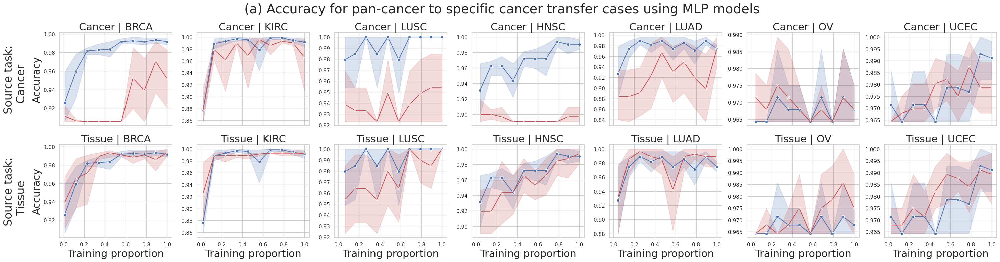

In [47]:
# Set a style
plt.figure()
sns.set(style="whitegrid")

# FacetGrid: rows = source, columns = target
g = sns.FacetGrid(
    df_long,
    col="cancer",
    row="source_task",
    sharey=False,
    sharex=True,
    margin_titles=False,
    despine=False, 
)

# Map lineplot to each facet
g.map_dataframe(
    sns.lineplot,
    x="train_samples",
    y="max_test_accuracy",
    marker="o",
)

g.map_dataframe(
    sns.lineplot,
    x="train_samples",
    y="max_test_accuracy_finetuned",
    marker="x",
    color='r'
)

# After plotting
#for ax, row_name in zip(g.axes[:, 0], g.row_names):
#    ax.set_ylabel(row_name.split('_')[0])


# Set axis labels
g.set_axis_labels("Training proportion", "Accuracy", size=22)
g.set_titles(row_template="{row_name}", col_template="{col_name}", size=22)

# Create custom legend handles
line1 = mlines.Line2D([], [], color='C0', marker='o', label='Baseline')
line2 = mlines.Line2D([], [], color='r', marker='x', label='Pre-trained')
# Get bottom-right axis
ax = g.axes[-1, -1]
# Add legend there
#ax.legend(handles=[line1, line2], fontsize=22, bbox_to_anchor=(1., -0.3))

ax = g.axes[0,0]
ax.text(-0.5, 0.5, "Source task:\n   Cancer", va='center', fontsize=24, transform=ax.transAxes, rotation=90)
ax = g.axes[1,0]
ax.text(-0.5, 0.5, "Source task:\n   Tissue", va='center', fontsize=24, transform=ax.transAxes, rotation=90)
g.fig.suptitle('(a) Accuracy for pan-cancer to specific cancer transfer cases using MLP models', fontsize=28)
g.fig.set_size_inches(30, 8)

# Adjust spacing
plt.tight_layout()
g.savefig("pancancer_grid_plot.png", dpi=300, bbox_inches="tight")
plt.show()

## GNN


In [48]:
N_VERSIONS = range(11,16)

In [49]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col(column).max().alias(f"max_{column}"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)

    return all_data


def safe_literal_eval(s):
    try:
        return ast.literal_eval(s)
    except (ValueError, SyntaxError, TypeError):
        return {}

def extract_perf_multi(source_file, tissue=False):
    df = pl.read_csv(source_file)
    #print(df.columns)
    df_temp = df.filter(pl.col('model').is_not_null())
    #print(df_temp['model'])
    if df_temp.height == 0:
        return None
    source_acc = [safe_literal_eval(s).get("test_accuracy") for s in df_temp]
    #print(source_auc)
    return pl.DataFrame({
        "train_samples": df_temp["train_samples"].to_list(),
        "source_accuracy": source_acc
    })

def extract_perf_multi(multitask_file, model):
    df = pl.read_csv(multitask_file)
    if model not in df.columns:
        return None
    df_temp = df.filter(pl.col(model).is_not_null())
    if df_temp.height == 0:
        return None
    multitask_acc = [safe_literal_eval(s).get("accuracy") for s in df_temp[model]]
    return pl.DataFrame({
        "train_samples": df_temp["train_samples"].to_list(),
        "multitask_accuracy": multitask_acc
    })

def compute_aupc_multitask(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    df_baseline = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", 'max_test_accuracy'])
    df_baseline = df_baseline.filter(pl.col("train_samples") < 1000)
    #print(df_baseline)
    df_baseline = (df_baseline.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df_baseline['train_samples'].max()).alias("train_samples")))
    mauc = auc(df_baseline['train_samples'], df_baseline['max_test_accuracy'])
    return mauc

def compute_aupc(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    df_baseline = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", 'max_test_accuracy'])
    df_baseline = df_baseline.filter(pl.col("train_samples") < 1000)
    #print(df_baseline)
    df_baseline = (df_baseline.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df_baseline['train_samples'].max()).alias("train_samples")))
    mauc = auc(df_baseline['train_samples'], df_baseline['max_test_accuracy'])
    return mauc

def compute_macc(source_task, target_task, v=0, metric="max_test_accuracy"):
    baseline_str = 'train_' + target_task + '_linspace_training'
    finetuned_str = source_task + '_to_' + target_task + '_'
    auc_baseline = compute_aupc(baseline_str, version = v, metric=metric)
    auc_finetuned = compute_aupc_multitask(finetuned_str, version = v, metric=metric)
    return auc_finetuned - auc_baseline, auc_finetuned, auc_baseline

def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", metric])
    #print(df)
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df

In [50]:
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df_prop_dict_gnn = {}
tasks = ['cancer_model', 'tissue_model']
cancers = ['BRCA','KIRC','LUSC','HNSC','LUAD', 'OV', 'UCEC']
#cancers = ['UCEC']
#tasks = ['tissue_model']

for source_task in tasks:
    for cancer in cancers:
        print(f'{source_task}-{cancer}-----')
        df_baseline = pl.DataFrame()
        df_finetuned = pl.DataFrame()
        for version in N_VERSIONS:
            #print(version)
            baseline_str = 'pancancer/gnn/train_GNN_' + 'cancer_model' + '_linspace' + cancer + '_training'
            finetuned_str = 'pancancer/gnn/GNN_' + source_task + '_to_cancer_model_without' + cancer
            df_temp_baseline = get_df(baseline_str, version=version)
            df_temp_finetuned = get_df(finetuned_str, version=version)
            df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
            df_baseline = df_baseline.sort('train_samples')
            df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
            df_finetuned = df_finetuned.sort('train_samples')
            print(f'Finetuned shape: {df_finetuned.shape}')
            print(f'Baseline shape: {df_baseline.shape}')
        # merge the two df
        print('-----')
        df = df_baseline.with_columns(df_finetuned['max_test_accuracy'].alias('max_test_accuracy_finetuned'))
        df_prop_dict_gnn[(source_task, cancer)] = df

cancer_model-BRCA-----
Finetuned shape: (10, 2)
Baseline shape: (10, 2)
Finetuned shape: (20, 2)
Baseline shape: (20, 2)
Finetuned shape: (30, 2)
Baseline shape: (30, 2)
Finetuned shape: (40, 2)
Baseline shape: (40, 2)
Finetuned shape: (50, 2)
Baseline shape: (50, 2)
-----
cancer_model-KIRC-----
Finetuned shape: (10, 2)
Baseline shape: (10, 2)
Finetuned shape: (20, 2)
Baseline shape: (20, 2)
Finetuned shape: (30, 2)
Baseline shape: (30, 2)
Finetuned shape: (40, 2)
Baseline shape: (40, 2)
Finetuned shape: (50, 2)
Baseline shape: (50, 2)
-----
cancer_model-LUSC-----
Finetuned shape: (10, 2)
Baseline shape: (10, 2)
Finetuned shape: (20, 2)
Baseline shape: (20, 2)
Finetuned shape: (30, 2)
Baseline shape: (30, 2)
Finetuned shape: (40, 2)
Baseline shape: (40, 2)
Finetuned shape: (50, 2)
Baseline shape: (50, 2)
-----
cancer_model-HNSC-----
Finetuned shape: (10, 2)
Baseline shape: (10, 2)
Finetuned shape: (20, 2)
Baseline shape: (20, 2)
Finetuned shape: (30, 2)
Baseline shape: (30, 2)
Finetune

In [51]:
rows = []
for (source, target), df in df_prop_dict_gnn.items():
    for ts, acc, acc_ft in zip(df['train_samples'], df['max_test_accuracy'], df['max_test_accuracy_finetuned']):
        rows.append({
            "source_task": source.split('_')[0].capitalize(),
            "target_task": target.split('_')[0],
            "train_samples": ts,
            "max_test_accuracy": acc,
            "max_test_accuracy_finetuned": acc_ft
        })

df_long_gnn = pd.DataFrame(rows)

<Figure size 640x480 with 0 Axes>

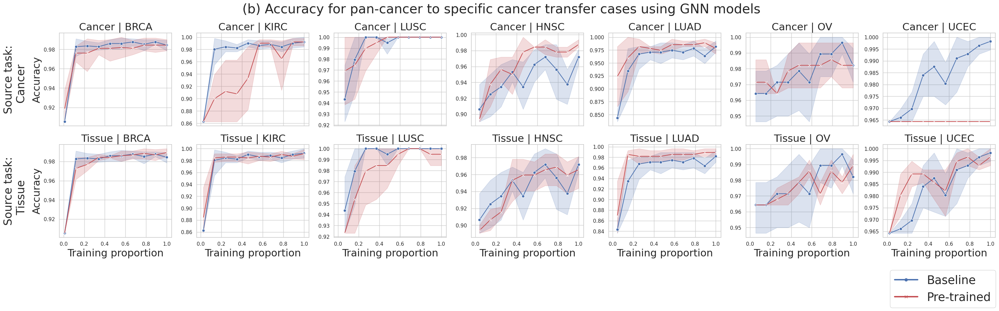

In [89]:
# Set a style
plt.figure()
sns.set(style="whitegrid")

# FacetGrid: rows = source, columns = target
g = sns.FacetGrid(
    df_long_gnn,
    col="target_task",
    row="source_task",
    sharey=False,
    sharex=True,
    margin_titles=False,
    despine=False, 
)

# Map lineplot to each facet
g.map_dataframe(
    sns.lineplot,
    x="train_samples",
    y="max_test_accuracy",
    marker="o",
)

g.map_dataframe(
    sns.lineplot,
    x="train_samples",
    y="max_test_accuracy_finetuned",
    marker="x",
    color='r'
)


# Set axis labels
g.set_axis_labels("Training proportion", "Accuracy", size=22)
g.set_titles(row_template="{row_name}", col_template="{col_name}", size=22)

# Create custom legend handles
line1 = mlines.Line2D([], [], color='C0', marker='o', label='Baseline', linewidth=3)
line2 = mlines.Line2D([], [], color='r', marker='x', label='Pre-trained', linewidth=3)
# Get bottom-right axis
ax = g.axes[-1, -1]
# Add legend there
g.fig.legend(handles=[line1, line2], fontsize=25, bbox_to_anchor=(1.0, 0.0))

ax = g.axes[0,0]
ax.text(-0.5, 0.5, "Source task:\n   Cancer", va='center', fontsize=24, transform=ax.transAxes, rotation=90)
ax = g.axes[1,0]
ax.text(-0.5, 0.5, "Source task:\n   Tissue", va='center', fontsize=24, transform=ax.transAxes, rotation=90)
g.fig.suptitle('(b) Accuracy for pan-cancer to specific cancer transfer cases using GNN models', fontsize=28)
g.fig.set_size_inches(30, 8)

# Adjust spacing
plt.tight_layout()
g.savefig("gnn_pancancer_grid_plot.png", dpi=300, bbox_inches="tight")
plt.show()

## Merge Grid Plot

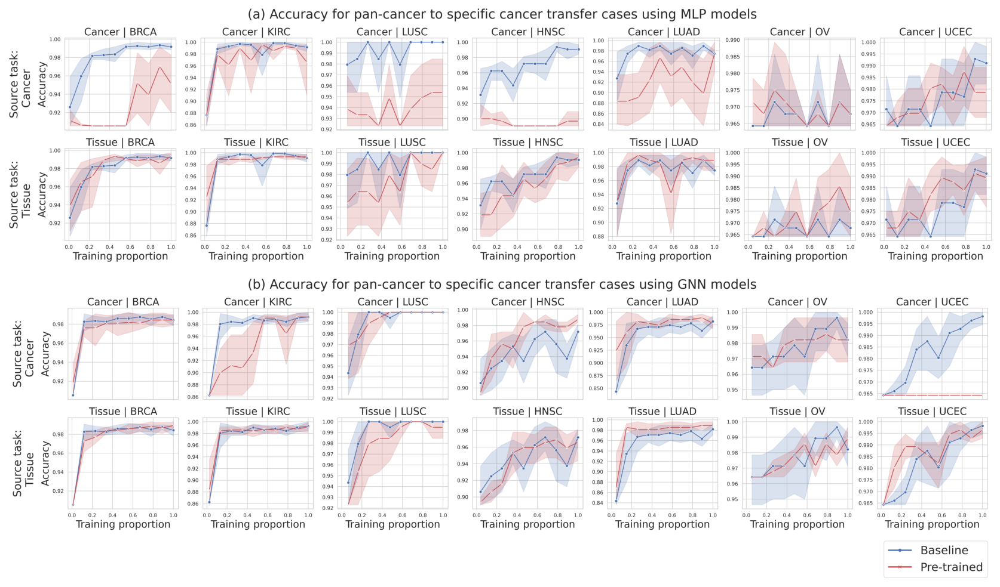

In [93]:
fig, axes = plt.subplots(2, 1, figsize=(25, 10), gridspec_kw={'height_ratios': [1, 1.178]})

img1 = plt.imread("pancancer_grid_plot.png")
img2 = plt.imread("gnn_pancancer_grid_plot.png")

axes[0].imshow(img1)
axes[0].axis("off")

axes[1].imshow(img2)
axes[1].axis("off")

plt.tight_layout()
plt.savefig('pancancer_merged.png')
plt.show()

# Recompute all metrics

In [98]:
# Configuration
N_VERSIONS = range(4)
BASE_PATH = "../../logs/"

In [20]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    print(df.columns)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col(column).max().alias(f"max_{column}"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)

    return all_data

def compute_aupc(source_file, version, metric="max_test_accuracy"):
    #baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df_baseline = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", metric])
    df_baseline = df_baseline.filter(pl.col("train_samples") < 1000)
    #print(df_baseline)
    df_baseline = (df_baseline.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df_baseline['train_samples'].max()).alias("train_samples")))
    mauc = auc(df_baseline['train_samples'], df_baseline[metric])
    return mauc

def compute_macc(source_task, target_task, v=0, metric="max_test_accuracy"):
    baseline_str = 'train_' + target_task + '_linspace_training'
    finetuned_str = source_task + '_to_' + target_task + '_'
    auc_baseline = compute_aupc(baseline_str, version = v, metric=metric)
    auc_finetuned = compute_aupc(finetuned_str, version = v, metric=metric)
    return auc_finetuned - auc_baseline, auc_finetuned, auc_baseline

In [28]:
auc_baseline = compute_aupc('cancer_model_to_tissue_model_', version=0)

In [29]:
diff = compute_macc('tissue_model', 'cancer_model')

In [140]:
log_df = pd.DataFrame(columns=['source', 'target', 'baseline aupc', 'pretrained aupc', 'p-value'])
i = 0

tasks = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model', 'radiation_model', 'pharma_model']

for source_task in tasks:
    for target_task in tasks:
        if source_task != target_task:
            pretrain_results_list = []
            baseline_results_list = []
            for version in range(2):
                macc, aupc_pretrained, aupc_baseline = compute_macc(source_task, target_task, v=version, metric='max_Roc_auc')
                pretrain_results_list.append(aupc_pretrained)
                baseline_results_list.append(aupc_baseline)
            baseline_mean = np.round(np.array(baseline_results_list).mean(), 3)
            baseline_std = np.round(np.array(baseline_results_list).std(), 3)
            pretrained_mean = np.round(np.array(pretrain_results_list).mean(),3)
            pretrained_std = np.round(np.array(pretrain_results_list).std(), 3)
            #print(f'Baseline results: {baseline_mean}±{baseline_std}')
            #print(f'Pretrained results: {pretrained_mean}±{pretrained_std}')
            t_stat, p_value = stats.ttest_rel(baseline_results_list, pretrain_results_list)
            #print(f'p-value: {p_value}')
            log_row = [source_task, target_task, f'{baseline_mean}±{baseline_std}', f'{pretrained_mean}±{pretrained_std}', p_value]
            log_df.loc[i] = log_row
            i += 1

['epoch', 'train_loss', 'val_loss', 'train_size', 'step', 'train_samples', 'test_accuracy', 'Roc_auc', 'f1_score']
['train_size', 'step', 'model', 'LogME', 'NLEEP', 'GBC', 'transrate', 'train_samples', 'frozen_layers', 'experiment', 'epoch', 'train_loss', 'val_loss', 'test_accuracy', 'Roc_auc', 'f1_score']
['epoch', 'train_loss', 'val_loss', 'train_size', 'step', 'train_samples', 'test_accuracy', 'Roc_auc', 'f1_score']
['train_size', 'step', 'model', 'LogME', 'NLEEP', 'GBC', 'transrate', 'train_samples', 'frozen_layers', 'experiment', 'epoch', 'train_loss', 'val_loss', 'test_accuracy', 'Roc_auc', 'f1_score']
['epoch', 'train_loss', 'val_loss', 'train_size', 'step', 'train_samples', 'test_accuracy', 'Roc_auc', 'f1_score']
['train_size', 'step', 'model', 'LogME', 'NLEEP', 'GBC', 'transrate', 'train_samples', 'frozen_layers', 'experiment', 'epoch', 'train_loss', 'val_loss', 'test_accuracy', 'Roc_auc', 'f1_score']
['epoch', 'train_loss', 'val_loss', 'train_size', 'step', 'train_samples', '

ColumnNotFoundError: Roc_auc

Resolved plan until failure:

	---> FAILED HERE RESOLVING 'sink' <---
DF ["epoch", "train_loss", "val_loss", "train_size", ...]; PROJECT */7 COLUMNS

In [104]:
log_df

,source,target,baseline aupc,pretrained aupc,p-value
0,tissue_model,cancer_model,0.893±0.002,0.871±0.001,0.048582
1,tissue_model,aa5_model,0.682±0.002,0.685±0.001,0.178259
2,tissue_model,stage_model,0.596±0.0,0.648±0.001,0.010973
3,tissue_model,radiation_model,0.644±0.0,0.656±0.006,0.305966
4,tissue_model,pharma_model,0.673±0.0,0.684±0.0,0.013296
5,cancer_model,tissue_model,0.808±0.007,0.813±0.001,0.562701
6,cancer_model,aa5_model,0.682±0.002,0.675±0.004,0.452183
7,cancer_model,stage_model,0.596±0.0,0.564±0.01,0.194462
8,cancer_model,radiation_model,0.644±0.0,0.616±0.009,0.208854
9,cancer_model,pharma_model,0.673±0.0,0.658±0.011,0.408386


In [102]:
log_df.to_csv('metrics_acc.csv')

# Multittask

In [64]:
from itertools import combinations, permutations
import os

In [92]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col(column).max().alias(f"max_{column}"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)

    return all_data


def safe_literal_eval(s):
    try:
        return ast.literal_eval(s)
    except (ValueError, SyntaxError, TypeError):
        return {}

def extract_perf_multi(source_file, tissue=False):
    df = pl.read_csv(source_file)
    #print(df.columns)
    df_temp = df.filter(pl.col('model').is_not_null())
    #print(df_temp['model'])
    if df_temp.height == 0:
        return None
    source_acc = [safe_literal_eval(s).get("test_accuracy") for s in df_temp]
    #print(source_auc)
    return pl.DataFrame({
        "train_samples": df_temp["train_samples"].to_list(),
        "source_accuracy": source_acc
    })

def extract_perf_multi(multitask_file, model):
    df = pl.read_csv(multitask_file)
    if model not in df.columns:
        return None
    df_temp = df.filter(pl.col(model).is_not_null())
    if df_temp.height == 0:
        return None
    multitask_acc = [safe_literal_eval(s).get("accuracy") for s in df_temp[model]]
    return pl.DataFrame({
        "train_samples": df_temp["train_samples"].to_list(),
        "multitask_accuracy": multitask_acc
    })

def compute_aupc_multitask(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    df_baseline = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", 'max_test_accuracy'])
    df_baseline = df_baseline.filter(pl.col("train_samples") < 1000)
    #print(df_baseline)
    df_baseline = (df_baseline.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df_baseline['train_samples'].max()).alias("train_samples")))
    mauc = auc(df_baseline['train_samples'], df_baseline['max_test_accuracy'])
    return mauc

def compute_aupc(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    df_baseline = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", 'max_test_accuracy'])
    df_baseline = df_baseline.filter(pl.col("train_samples") < 1000)
    #print(df_baseline)
    df_baseline = (df_baseline.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df_baseline['train_samples'].max()).alias("train_samples")))
    mauc = auc(df_baseline['train_samples'], df_baseline['max_test_accuracy'])
    return mauc

def compute_macc(source_task, target_task, v=0, metric="max_test_accuracy"):
    baseline_str = 'train_' + target_task + '_linspace_training'
    finetuned_str = source_task + '_to_' + target_task + '_'
    auc_baseline = compute_aupc(baseline_str, version = v, metric=metric)
    auc_finetuned = compute_aupc_multitask(finetuned_str, version = v, metric=metric)
    return auc_finetuned - auc_baseline, auc_finetuned, auc_baseline

In [23]:
models = ['aa5_models', 'stage_model', 'tissue_model', 'cancer_model']

In [ ]:
df = extract_perf_multi('aa5_model_cancer_model_stage_model_to_tissue_mode_', )

In [27]:
df = pd.read_csv('../../logs/aa5_model_cancer_model_stage_model_to_tissue_model_/version_0/metrics.csv')

In [31]:
df.columns

Index(['train_size', 'step', 'model', 'LogME', 'NLEEP', 'GBC', 'transrate',
       'train_samples', 'frozen_layers', 'experiment', 'epoch', 'train_loss',
       'val_loss', 'test_accuracy', 'Roc_auc', 'f1_score'],
      dtype='object')

In [29]:
df = pd.read_csv('../../logs/tissue_model_to_cancer_model_/version_0/metrics.csv')

In [36]:
df = compute_aupc_multitask('aa5_model_cancer_model_stage_model_to_tissue_model_', version=0, metric="max_test_accuracy")

In [37]:
df

np.float64(0.7890250668449198)

In [39]:
for model in list(combinations(models, 3)): print(model)

('aa5_models', 'stage_model', 'tissue_model')
('aa5_models', 'stage_model', 'cancer_model')
('aa5_models', 'tissue_model', 'cancer_model')
('stage_model', 'tissue_model', 'cancer_model')


In [97]:
log_df = pd.DataFrame(columns=['source', 'target', 'baseline aupc', 'pretrained aupc', 'p-value'])
i = 0
models = ['aa5_model', 'cancer_model', 'stage_model', 'tissue_model']
version = 0

for model in permutations(models, 3):
    #print(model)
    for target in models:
        group_task_str = '_'.join(model)
        print(f'../../logs/{group_task_str}_to_{target}')
        if os.path.isdir(f'../../logs/{group_task_str}_to_{target}_'):
            print('combination exists')
            pretrain_results_list = []
            baseline_results_list = []
            for version in range(2):
                macc, aupc_pretrained, aupc_baseline = compute_macc(group_task_str, target, v=version)
                pretrain_results_list.append(aupc_pretrained)
                baseline_results_list.append(aupc_baseline)
            baseline_mean = np.round(np.array(baseline_results_list).mean(), 3)
            baseline_std = np.round(np.array(baseline_results_list).std(), 3)
            pretrained_mean = np.round(np.array(pretrain_results_list).mean(),3)
            pretrained_std = np.round(np.array(pretrain_results_list).std(), 3)
            #print(f'Baseline results: {baseline_mean}±{baseline_std}')
            #print(f'Pretrained results: {pretrained_mean}±{pretrained_std}')
            t_stat, p_value = stats.ttest_rel(baseline_results_list, pretrain_results_list)
            #print(f'p-value: {p_value}')
            log_row = [group_task_str, target, f'{baseline_mean}±{baseline_std}', f'{pretrained_mean}±{pretrained_std}', p_value]
            log_df.loc[i] = log_row
            i += 1
        else: 
            print("combination does not exist")
            continue
log_df.to_csv('metrics_multitask_acc.csv')

../../logs/aa5_model_cancer_model_stage_model_to_aa5_model
combination does not exist
../../logs/aa5_model_cancer_model_stage_model_to_cancer_model
combination does not exist
../../logs/aa5_model_cancer_model_stage_model_to_stage_model
combination does not exist
../../logs/aa5_model_cancer_model_stage_model_to_tissue_model
combination exists
../../logs/aa5_model_cancer_model_tissue_model_to_aa5_model
combination does not exist
../../logs/aa5_model_cancer_model_tissue_model_to_cancer_model
combination does not exist
../../logs/aa5_model_cancer_model_tissue_model_to_stage_model
combination exists
../../logs/aa5_model_cancer_model_tissue_model_to_tissue_model
combination does not exist
../../logs/aa5_model_stage_model_cancer_model_to_aa5_model
combination does not exist
../../logs/aa5_model_stage_model_cancer_model_to_cancer_model
combination does not exist
../../logs/aa5_model_stage_model_cancer_model_to_stage_model
combination does not exist
../../logs/aa5_model_stage_model_cancer_model

In [96]:
log_df

,source,target,baseline aupc,pretrained aupc,p-value
0,aa5_model_cancer_model_stage_model,tissue_model,0.808±0.007,0.789±0.0,0.220114
1,aa5_model_cancer_model_tissue_model,stage_model,0.596±0.0,0.635±0.015,0.236828
2,aa5_model_stage_model_tissue_model,cancer_model,0.893±0.002,0.87±0.0,0.060675
3,cancer_model_stage_model_tissue_model,aa5_model,0.682±0.002,0.716±0.003,0.010676


# Compute with proportion

## Intertask MLP

In [10]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    #print(df.columns)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col(column).max().alias(f"max_{column}"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)

    return all_data

def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", metric])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df

def get_mauc(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", metric])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    mauc = auc(df['train_samples'], df['max_test_accuracy'])
    return mauc

def compute_macc(source_task, target_task, v=0, metric="max_test_accuracy"):
    baseline_str = 'train_' + target_task + '_linspace_training'
    finetuned_str = source_task + '_to_' + target_task + '_'
    auc_baseline = compute_aupc(baseline_str, version = v, metric=metric)
    auc_finetuned = compute_aupc_multitask(finetuned_str, version = v, metric=metric)
    return auc_finetuned - auc_baseline, auc_finetuned, auc_baseline

In [5]:
df = pl.DataFrame()
df_dict = {}
df_baseline_prop_dict = {}
tasks = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model', 'radiation_model', 'pharma_model']
#tasks = ['tissue_model']

for target_task in tasks:
    df = pl.DataFrame()
    prop_acc_list = []
    for version in range(5):
        #print(version)
        baseline_str = 'intertask/mlp/train_' + target_task + '_linspace_training'
        df_temp = get_df(baseline_str, version=version)
        df = pl.concat([df, df_temp], how='vertical')
        df = df.sort('train_samples')
    result_prop = (
        df
        .group_by("train_samples")
        .agg(
            pl.col("max_test_accuracy").alias("accuracy_list")
        )
        .sort("train_samples")  # optional
    )
    s = pl.Series("train_samples", [f"p_{i}" for i in range(len(result_prop['train_samples']))])
    result_prop.replace_column(0, s)
    result = (
        df
        .group_by("train_samples")
        .agg([
            pl.col("max_test_accuracy").mean().alias("accuracy_mean"),
            pl.col("max_test_accuracy").std().alias("accuracy_std"),
        ])
        .sort("train_samples")  # optional
    )
    df_dict[target_task] = result
    df_baseline_prop_dict[target_task] = result_prop

In [6]:
df_all = pl.concat(
    [
        df.with_columns(pl.lit(task).alias("target_task")) for task, df in df_baseline_prop_dict.items()
    ]
)
grouped = (
    df_all
    .group_by("train_samples")
    .agg([
        pl.col("target_task"),
        pl.col("accuracy_list")
    ])
)
result_dict = {
    row["train_samples"]: pl.DataFrame({
        "target_task": row["target_task"],
        "accuracy_list": row["accuracy_list"]
    })
    for row in grouped.iter_rows(named=True)
}

In [12]:
#tasks = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model', 'radiation_model', 'pharma_model']
source_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
target_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df = pl.DataFrame()
df_dict = {}
df_prop_dict = {}

for source_task in source_tasks: 
    for target_task in target_tasks:
        if source_task != target_task:
            print(f'{source_task}-{target_task}-----')
            df_baseline = pl.DataFrame()
            df_finetuned = pl.DataFrame()
            for version in range(5):
                #print(version)
                baseline_str = 'train_' + target_task + '_linspace_training'
                finetuned_str = source_task + '_to_' + target_task + '_'
                df_temp_baseline = get_df(baseline_str, version=version)
                df_temp_finetuned = get_df(finetuned_str, version=version)
                df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
                df_baseline = df_baseline.sort('train_samples')
                df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
                #print(df_finetuned)
                df_finetuned = df_finetuned.sort('train_samples')
            
            #print(df_baseline['train_samples'])
            #print(list(df_finetuned['train_samples']))
            print('-----')
            df = df_baseline.with_columns(df_finetuned['max_test_accuracy'].alias('max_test_accuracy_finetuned'))
            result_prop = (
                df
                .group_by("train_samples")
                .agg(
                    pl.col("max_test_accuracy").alias("accuracy_list")
                )
                .sort("train_samples")  # optional
            )
            result_prop_finetuned = (
                df
                .group_by("train_samples")
                .agg(
                    pl.col("max_test_accuracy_finetuned").alias("accuracy_list_finetuned")
                )
                .sort("train_samples")  # optional
            )
            result_prop = result_prop.with_columns(result_prop_finetuned["accuracy_list_finetuned"])
            s = pl.Series("train_samples", [f"p_{i}" for i in range(len(result_prop['train_samples']))])
            result_prop.replace_column(0, s)
            #print(result_prop)
            df_prop_dict[(source_task, target_task)] = result_prop

tissue_model-cancer_model-----
-----
tissue_model-stage_model-----
-----
tissue_model-aa5_model-----
-----
tissue_model-radiation_model-----
-----
tissue_model-pharma_model-----
-----
cancer_model-tissue_model-----
-----
cancer_model-stage_model-----
-----
cancer_model-aa5_model-----
-----
cancer_model-radiation_model-----
-----
cancer_model-pharma_model-----
-----
stage_model-tissue_model-----
-----
stage_model-cancer_model-----
-----
stage_model-aa5_model-----
-----
stage_model-radiation_model-----
-----
stage_model-pharma_model-----
-----
aa5_model-tissue_model-----
-----
aa5_model-cancer_model-----
-----
aa5_model-stage_model-----
-----
aa5_model-radiation_model-----
-----
aa5_model-pharma_model-----
-----
radiation_model-tissue_model-----
-----
radiation_model-cancer_model-----
-----
radiation_model-stage_model-----
-----
radiation_model-aa5_model-----
-----
radiation_model-pharma_model-----
-----
pharma_model-tissue_model-----
-----
pharma_model-cancer_model-----
-----
pharma_mod

In [31]:
df_prop_dict

{('tissue_model',
  'cancer_model'): shape: (10, 3)
 ┌───────────────┬─────────────────────────────────┬─────────────────────────────────┐
 │ train_samples ┆ accuracy_list                   ┆ accuracy_list_finetuned         │
 │ ---           ┆ ---                             ┆ ---                             │
 │ str           ┆ list[f64]                       ┆ list[f64]                       │
 ╞═══════════════╪═════════════════════════════════╪═════════════════════════════════╡
 │ p_0           ┆ [0.928342, 0.928342, … 0.93957… ┆ [0.944385, 0.946524, … 0.92726… │
 │ p_1           ┆ [0.928342, 0.928342, … 0.92834… ┆ [0.928342, 0.974332, … 0.92564… │
 │ p_2           ┆ [0.964171, 0.928342, … 0.94117… ┆ [0.979679, 0.990909, … 0.92564… │
 │ p_3           ┆ [0.928342, 0.928342, … 0.93475… ┆ [0.982888, 0.993048, … 0.92618… │
 │ p_4           ┆ [0.934225, 0.970053, … 0.95828… ┆ [0.988235, 0.995187, … 0.92618… │
 │ p_5           ┆ [0.978075, 0.969519, … 0.92834… ┆ [0.993583, 0.995187, … 0.

In [32]:
df_all = pl.concat(
    [
        df.with_columns([
            pl.lit(source).alias("source_task"),
            pl.lit(target).alias("target_task"),
        ])
        for (source, target), df in df_prop_dict.items()
    ]
)

grouped = (
    df_all
    .group_by("train_samples")
    .agg([
        pl.col("source_task"),
        pl.col("target_task"),
        pl.col("accuracy_list"),
        pl.col("accuracy_list_finetuned")
    ])
)

result_dict = {
    row["train_samples"]: pl.DataFrame({
        "source_task": row["source_task"],
        "target_task": row["target_task"],
        "accuracy_list": row["accuracy_list"],
        "accuracy_list_finetuned": row["accuracy_list_finetuned"]
    })
    for row in grouped.iter_rows(named=True)
}


In [33]:
result_dict

{'p_8': shape: (30, 4)
 ┌──────────────┬─────────────────┬────────────────────────┬─────────────────────────────────┐
 │ source_task  ┆ target_task     ┆ accuracy_list          ┆ accuracy_list_finetuned         │
 │ ---          ┆ ---             ┆ ---                    ┆ ---                             │
 │ str          ┆ str             ┆ list[f64]              ┆ list[f64]                       │
 ╞══════════════╪═════════════════╪════════════════════════╪═════════════════════════════════╡
 │ tissue_model ┆ cancer_model    ┆ [0.958824, 0.973797, … ┆ [0.993048, 0.994652, … 0.92672… │
 │              ┆                 ┆ 0.96844…               ┆                                 │
 │ tissue_model ┆ stage_model     ┆ [0.681658, 0.69993, …  ┆ [0.714489, 0.713778, … 0.72522… │
 │              ┆                 ┆ 0.703443…              ┆                                 │
 │ tissue_model ┆ aa5_model       ┆ [0.737003, 0.74159, …  ┆ [0.735474, 0.737003, … 0.73394… │
 │              ┆          

In [34]:
from scipy.stats import ttest_ind  # or ttest_rel if paired


def compute_stats(df: pl.DataFrame) -> pl.DataFrame:

    def stats_and_pvalue(row):
        acc = np.array(row["accuracy_list"])
        acc_ft = np.array(row["accuracy_list_finetuned"])

        mean1, std1 = acc.mean(), acc.std(ddof=1)
        mean2, std2 = acc_ft.mean(), acc_ft.std(ddof=1)
        
        delta = mean2 - mean1

        # choose test type
        stat, pval = ttest_ind(acc, acc_ft, equal_var=False)

        return (
            f"{mean1:.4f} ± {std1:.4f}",
            f"{mean2:.4f} ± {std2:.4f}",
            f"{np.round(pval, 5)}",
            f"{np.round(delta, 5)}"
        )
    
    return df.with_columns(
                pl.struct(["accuracy_list", "accuracy_list_finetuned"])
                .map_elements(stats_and_pvalue)
                .alias("stats")
            ).with_columns([
                pl.col("stats").list.get(0).alias("accuracy_stats"),
                pl.col("stats").list.get(1).alias("accuracy_finetuned_stats"),
                pl.col("stats").list.get(2).alias("p_value"),
                pl.col("stats").list.get(3).alias("delta"),
            ]).drop("stats")

In [35]:
result_dict = {
    train_sample: compute_stats(df)
    for train_sample, df in result_dict.items()
}

/shared/home/kevindradjat/.local/lib/python3.9/site-packages/numpy/core/_methods.py:265: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/shared/home/kevindradjat/.local/lib/python3.9/site-packages/numpy/core/_methods.py:257: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/shared/home/kevindradjat/.local/lib/python3.9/site-packages/scipy/stats/_stats_py.py:1081: RuntimeWarning: divide by zero encountered in divide
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero
/shared/home/kevindradjat/.local/lib/python3.9/site-packages/scipy/stats/_stats_py.py:1081: RuntimeWarning: invalid value encountered in double_scalars
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero
/shared/home/kevindradjat/.local/lib/python3.9/site-packages/scipy/stats/_axis_nan_policy.py:531: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic ca

In [36]:
result_dict['p_0']

source_task,target_task,accuracy_list,accuracy_list_finetuned,accuracy_stats,accuracy_finetuned_stats,p_value,delta
str,str,list[f64],list[f64],str,str,str,str
"""tissue_model""","""cancer_model""","[0.928342, 0.928342, … 0.939572]","[0.944385, 0.946524, … 0.927263]","""0.9343 ± 0.0073""","""0.9388 ± 0.0101""","""0.4463""","""0.00449"""
"""tissue_model""","""stage_model""","[0.573436, 0.607871, … 0.615601]","[0.605824, 0.604403, … 0.519325]","""0.5848 ± 0.0470""","""0.5933 ± 0.0427""","""0.77323""","""0.00847"""
"""tissue_model""","""aa5_model""","[0.649847, 0.668196, … 0.576453]","[0.648318, 0.608563, … 0.675841]","""0.6370 ± 0.0354""","""0.6566 ± 0.0310""","""0.38026""","""0.01957"""
"""tissue_model""","""radiation_model""","[0.550394, 0.606486, … 0.659071]","[0.687117, 0.737073, … 0.63979]","""0.6072 ± 0.0413""","""0.6691 ± 0.0450""","""0.05349""","""0.06188"""
"""tissue_model""","""pharma_model""","[0.662577, 0.675723, … 0.63716]","[0.694128, 0.736196, … 0.62489]","""0.6554 ± 0.0146""","""0.6906 ± 0.0406""","""0.12691""","""0.03523"""
…,…,…,…,…,…,…,…
"""pharma_model""","""tissue_model""","[0.51016, 0.579144, … 0.471123]","[0.382353, 0.43369, … 0.394118]","""0.5211 ± 0.0392""","""0.4096 ± 0.0299""","""0.00121""","""-0.11144"""
"""pharma_model""","""cancer_model""","[0.928342, 0.928342, … 0.939572]","[0.928342, 0.952406, … 0.928342]","""0.9343 ± 0.0073""","""0.9332 ± 0.0108""","""0.84521""","""-0.00118"""
"""pharma_model""","""stage_model""","[0.573436, 0.607871, … 0.615601]","[0.634575, 0.659171, … 0.574842]","""0.5848 ± 0.0470""","""0.6139 ± 0.0332""","""0.29454""","""0.02909"""


In [37]:
df_plot = pl.DataFrame().with_columns(result_dict['p_0']['source_task'], result_dict['p_0']['target_task'])
for i in range(2):
    df_plot = df_plot.with_columns(result_dict[f'p_{i}']['accuracy_stats'].alias(f"acc_stats_p_{i}"), 
                                   result_dict[f'p_{i}']['accuracy_finetuned_stats'].alias(f"acc_stats_finetuned_p_{i}"), 
                                   result_dict[f'p_{i}']['p_value'].alias(f"p_value_p_{i}"))
df_plot.write_csv('metrics_multitask_acc_prop_1.csv')

df_plot = pl.DataFrame().with_columns(result_dict['p_0']['source_task'], result_dict['p_0']['target_task'])
for i in range(2, 4):
    df_plot = df_plot.with_columns(result_dict[f'p_{i}']['accuracy_stats'].alias(f"acc_stats_p_{i}"), 
                                   result_dict[f'p_{i}']['accuracy_finetuned_stats'].alias(f"acc_stats_finetuned_p_{i}"), 
                                   result_dict[f'p_{i}']['p_value'].alias(f"p_value_p_{i}"))
df_plot.write_csv('metrics_multitask_acc_prop_2.csv')

df_plot = pl.DataFrame().with_columns(result_dict['p_0']['source_task'], result_dict['p_0']['target_task'])
for i in range(4, 6):
    df_plot = df_plot.with_columns(result_dict[f'p_{i}']['accuracy_stats'].alias(f"acc_stats_p_{i}"), 
                                   result_dict[f'p_{i}']['accuracy_finetuned_stats'].alias(f"acc_stats_finetuned_p_{i}"), 
                                   result_dict[f'p_{i}']['p_value'].alias(f"p_value_p_{i}"))
df_plot.write_csv('metrics_multitask_acc_prop_3.csv')

df_plot = pl.DataFrame().with_columns(result_dict['p_0']['source_task'], result_dict['p_0']['target_task'])
for i in range(6, 8):
    df_plot = df_plot.with_columns(result_dict[f'p_{i}']['accuracy_stats'].alias(f"acc_stats_p_{i}"), 
                                   result_dict[f'p_{i}']['accuracy_finetuned_stats'].alias(f"acc_stats_finetuned_p_{i}"), 
                                   result_dict[f'p_{i}']['p_value'].alias(f"p_value_p_{i}"))
df_plot.write_csv('metrics_multitask_acc_prop_4.csv')

df_plot = pl.DataFrame().with_columns(result_dict['p_0']['source_task'], result_dict['p_0']['target_task'])
for i in range(8, 10):
    df_plot = df_plot.with_columns(result_dict[f'p_{i}']['accuracy_stats'].alias(f"acc_stats_p_{i}"), 
                                   result_dict[f'p_{i}']['accuracy_finetuned_stats'].alias(f"acc_stats_finetuned_p_{i}"), 
                                   result_dict[f'p_{i}']['p_value'].alias(f"p_value_p_{i}"))
df_plot.write_csv('metrics_multitask_acc_prop_5.csv')

In [38]:
df_plot

source_task,target_task
str,str
"""tissue_model""","""cancer_model"""
"""tissue_model""","""aa5_model"""
"""tissue_model""","""stage_model"""
"""tissue_model""","""radiation_model"""
"""tissue_model""","""pharma_model"""
…,…
"""pharma_model""","""tissue_model"""
"""pharma_model""","""cancer_model"""
"""pharma_model""","""aa5_model"""


In [37]:
df_plot = pl.DataFrame().with_columns(result_dict['p_0']['source_task'], result_dict['p_0']['target_task'])
for i in range(10):
    #p_value_col = result_dict[f'p_{i}']['p_value']
    df_plot = df_plot.with_columns(result_dict[f'p_{i}']['delta'].alias(f"delta p_{i}"), result_dict[f'p_{i}']['p_value'].alias(f"p-value p_{i}"))
    #df_plot = df_plot.with_columns(result_dict[f'p_{i}']['delta'].alias(f"delta p_{i}"))

In [38]:
print(list(df_plot["target_task"]))
print(list(df_plot[f"p-value p_{0}"]))

['cancer_model', 'stage_model', 'aa5_model', 'radiation_model', 'pharma_model', 'tissue_model', 'stage_model', 'aa5_model', 'radiation_model', 'pharma_model', 'tissue_model', 'cancer_model', 'aa5_model', 'radiation_model', 'pharma_model', 'tissue_model', 'cancer_model', 'stage_model', 'radiation_model', 'pharma_model', 'tissue_model', 'cancer_model', 'stage_model', 'aa5_model', 'pharma_model', 'tissue_model', 'cancer_model', 'stage_model', 'aa5_model', 'radiation_model']
['0.4463', '0.77323', '0.38026', '0.05349', '0.12691', '0.00038', '0.81156', '0.1209', '0.46905', '0.2018', '9e-05', '0.12403', '0.09974', '0.45435', '0.69901', '0.0', '0.15027', '0.79515', '0.83306', '0.18781', '0.00104', '0.27303', '0.50227', '0.39683', '0.39376', '0.00121', '0.84521', '0.29454', '0.1859', '0.4776']


In [20]:
#df_plot.write_csv('metrics_intertask_delta_pvalue.csv')
df_plot.write_csv('metrics_intertask_delta.csv')

In [41]:
dfs = []
df_plot = pl.DataFrame().with_columns(result_dict['p_0']['source_task'], result_dict['p_0']['target_task'])
for i in range(10):
    df_i = (
        result_dict[f'p_{i}']
        .with_columns(
            pl.when(
                (pl.col("p_value").cast(pl.Float64) < 0.05) & (pl.col("delta").cast(pl.Float64) > 0)
            )
            .then(pl.col("delta"))
            .otherwise(pl.col("delta"))
            .alias("delta")
        )
    )

    dfs.append(df_i)

df_plot = pl.concat(dfs)

In [42]:
df_plot

source_task,target_task,accuracy_list,accuracy_list_finetuned,accuracy_stats,accuracy_finetuned_stats,p_value,delta
str,str,list[f64],list[f64],str,str,str,str
"""tissue_model""","""cancer_model""","[0.928342, 0.928342, … 0.939572]","[0.944385, 0.946524, … 0.927263]","""0.9343 ± 0.0073""","""0.9388 ± 0.0101""","""0.4463""","""0.00449"""
"""tissue_model""","""stage_model""","[0.573436, 0.607871, … 0.615601]","[0.605824, 0.604403, … 0.519325]","""0.5848 ± 0.0470""","""0.5933 ± 0.0427""","""0.77323""","""0.00847"""
"""tissue_model""","""aa5_model""","[0.649847, 0.668196, … 0.576453]","[0.648318, 0.608563, … 0.675841]","""0.6370 ± 0.0354""","""0.6566 ± 0.0310""","""0.38026""","""0.01957"""
"""tissue_model""","""radiation_model""","[0.550394, 0.606486, … 0.659071]","[0.687117, 0.737073, … 0.63979]","""0.6072 ± 0.0413""","""0.6691 ± 0.0450""","""0.05349""","""0.06188"""
"""tissue_model""","""pharma_model""","[0.662577, 0.675723, … 0.63716]","[0.694128, 0.736196, … 0.62489]","""0.6554 ± 0.0146""","""0.6906 ± 0.0406""","""0.12691""","""0.03523"""
…,…,…,…,…,…,…,…
"""pharma_model""","""tissue_model""","[0.937968, 0.932086, … 0.935829]","[0.926203, 0.929947, … 0.92246]","""0.9336 ± 0.0046""","""0.9261 ± 0.0078""","""0.11185""","""-0.00749"""
"""pharma_model""","""cancer_model""","[0.97861, 0.97861, … 0.962567]","[0.928342, 0.973797, … 0.928342]","""0.9649 ± 0.0215""","""0.9477 ± 0.0266""","""0.29429""","""-0.01722"""
"""pharma_model""","""stage_model""","[0.675334, 0.692902, … 0.697822]","[0.693605, 0.681658, … 0.676739]","""0.6840 ± 0.0172""","""0.6718 ± 0.0191""","""0.31897""","""-0.01223"""


In [23]:
for i in range(10):
    k = 0
    prop = f'p_{i}'
    print(f"------{prop}--------")
    for line in result_dict[prop].iter_rows():
        source = line[0]
        target = line[1]
        p_value = float(line[6])
        delta = float(line[7])
        if p_value <= 0.05 and delta > 0:
            print(f"{source} to {target}")
            k += 1
    print(f'Number of link: {k}')
    print('---------------------')

------p_0--------
Number of link: 0
---------------------
------p_1--------
Number of link: 0
---------------------
------p_2--------
tissue_model to cancer_model
tissue_model to aa5_model
stage_model to aa5_model
Number of link: 3
---------------------
------p_3--------
tissue_model to cancer_model
tissue_model to aa5_model
stage_model to aa5_model
Number of link: 3
---------------------
------p_4--------
tissue_model to stage_model
cancer_model to tissue_model
stage_model to aa5_model
Number of link: 3
---------------------
------p_5--------
tissue_model to aa5_model
cancer_model to tissue_model
cancer_model to aa5_model
stage_model to aa5_model
Number of link: 4
---------------------
------p_6--------
tissue_model to aa5_model
cancer_model to tissue_model
stage_model to aa5_model
Number of link: 3
---------------------
------p_7--------
tissue_model to stage_model
cancer_model to tissue_model
stage_model to aa5_model
pharma_model to radiation_model
Number of link: 4
----------------

In [88]:
plt.figure()
sns.lineplot(data=result_dict['p_0'].to_pandas(), x='accuracy_list', y='accuracy_list_finetuned')
plt.show()

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

<Figure size 640x480 with 0 Axes>

## For Grid Plot

In [34]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    #print(df.columns)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col(column).max().alias(f"max_{column}"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)

    return all_data

def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", metric])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df

def compute_macc(source_task, target_task, v=0, metric="max_test_accuracy"):
    baseline_str = 'train_' + target_task + '_linspace_training'
    finetuned_str = source_task + '_to_' + target_task + '_'
    auc_baseline = compute_aupc(baseline_str, version = v, metric=metric)
    auc_finetuned = compute_aupc_multitask(finetuned_str, version = v, metric=metric)
    return auc_finetuned - auc_baseline, auc_finetuned, auc_baseline

In [35]:
#tasks = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model', 'radiation_model', 'pharma_model']
source_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
target_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df = pl.DataFrame()
df_dict = {}
df_prop_dict = {}
df_prop_dict_intertask_mlp = {}

for source_task in source_tasks: 
    for target_task in target_tasks:
        if source_task != target_task:
            print(f'{source_task}-{target_task}-----')
            df_baseline = pl.DataFrame()
            df_finetuned = pl.DataFrame()
            for version in range(5):
                #print(version)
                baseline_str = 'intertask/mlp/train_' + target_task + '_linspace_training'
                finetuned_str = 'intertask/mlp/' + source_task + '_to_' + target_task + '_'
                df_temp_baseline = get_df(baseline_str, version=version)
                df_temp_finetuned = get_df(finetuned_str, version=version)
                df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
                df_baseline = df_baseline.sort('train_samples')
                df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
                #print(df_finetuned)
                df_finetuned = df_finetuned.sort('train_samples')
            
            #print(df_baseline['train_samples'])
            #print(list(df_finetuned['train_samples']))
            #print(df_baseline)
            print('-----')
            df = df_baseline.with_columns(df_finetuned['max_test_accuracy'].alias('max_test_accuracy_finetuned'))
            #df_prop_dict[(source_task, target_task)] = df
            #print(source_task, target_task)
            if source_task=='aa5_model': 
                df_prop_dict[('AA5_model',target_task)] = df
                df_prop_dict_intertask_mlp[('AA5_model',target_task)] = df
            elif target_task=='aa5_model': 
                df_prop_dict[(source_task,'AA5_model')] = df
                df_prop_dict_intertask_mlp[(source_task,'AA5_model')] = df
            else: 
                df_prop_dict[(source_task,target_task)] = df
                df_prop_dict_intertask_mlp[(source_task,target_task)] = df

tissue_model-cancer_model-----
-----
tissue_model-stage_model-----
-----
tissue_model-aa5_model-----
-----
tissue_model-radiation_model-----
-----
tissue_model-pharma_model-----
-----
cancer_model-tissue_model-----
-----
cancer_model-stage_model-----
-----
cancer_model-aa5_model-----
-----
cancer_model-radiation_model-----
-----
cancer_model-pharma_model-----
-----
stage_model-tissue_model-----
-----
stage_model-cancer_model-----
-----
stage_model-aa5_model-----
-----
stage_model-radiation_model-----
-----
stage_model-pharma_model-----
-----
aa5_model-tissue_model-----
-----
aa5_model-cancer_model-----
-----
aa5_model-stage_model-----
-----
aa5_model-radiation_model-----
-----
aa5_model-pharma_model-----
-----
radiation_model-tissue_model-----
-----
radiation_model-cancer_model-----
-----
radiation_model-stage_model-----
-----
radiation_model-aa5_model-----
-----
radiation_model-pharma_model-----
-----
pharma_model-tissue_model-----
-----
pharma_model-cancer_model-----
-----
pharma_mod

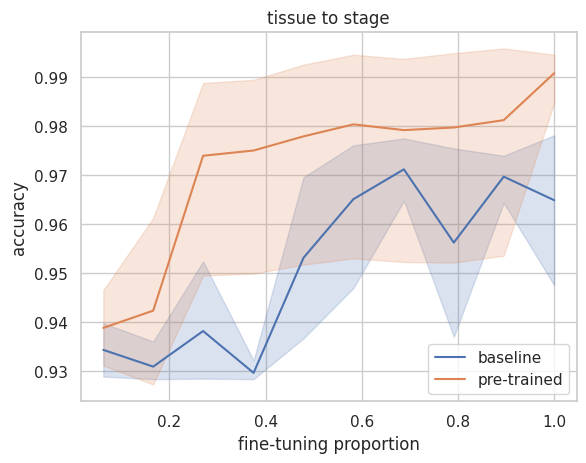

In [31]:
plt.figure()
sns.lineplot(data=df_prop_dict[('tissue_model', 'cancer_model')], y='max_test_accuracy', x='train_samples', label='baseline')
sns.lineplot(data=df_prop_dict[('tissue_model', 'cancer_model')], y='max_test_accuracy_finetuned', x='train_samples', label='pre-trained')
plt.title(f'tissue to stage')
plt.xlabel('fine-tuning proportion')
plt.ylabel('accuracy')
plt.show()

In [36]:
rows = []
for (source,target), df in df_prop_dict.items():
    print(source,target)
    for ts, acc, acc_ft in zip(df['train_samples'], df['max_test_accuracy'], df['max_test_accuracy_finetuned']):
        #print(source, target)
        if target=='AA5_model':
            rows.append({
                "source_task": source.split('_')[0].capitalize(),
                "target_task": target.split('_')[0],
                "train_samples": ts,
                "max_test_accuracy": acc,
                "max_test_accuracy_finetuned": acc_ft
            })
        if source=='AA5_model':
            rows.append({
                "source_task": source.split('_')[0],
                "target_task": target.split('_')[0].capitalize(),
                "train_samples": ts,
                "max_test_accuracy": acc,
                "max_test_accuracy_finetuned": acc_ft
            })
        else:
            rows.append({
                "source_task": source.split('_')[0].capitalize(),
                "target_task": target.split('_')[0].capitalize(),
                "train_samples": ts,
                "max_test_accuracy": acc,
                "max_test_accuracy_finetuned": acc_ft
            })

df_long = pd.DataFrame(rows)

tissue_model cancer_model
tissue_model stage_model
tissue_model AA5_model
tissue_model radiation_model
tissue_model pharma_model
cancer_model tissue_model
cancer_model stage_model
cancer_model AA5_model
cancer_model radiation_model
cancer_model pharma_model
stage_model tissue_model
stage_model cancer_model
stage_model AA5_model
stage_model radiation_model
stage_model pharma_model
AA5_model tissue_model
AA5_model cancer_model
AA5_model stage_model
AA5_model radiation_model
AA5_model pharma_model
radiation_model tissue_model
radiation_model cancer_model
radiation_model stage_model
radiation_model AA5_model
radiation_model pharma_model
pharma_model tissue_model
pharma_model cancer_model
pharma_model stage_model
pharma_model AA5_model
pharma_model radiation_model


<Figure size 640x480 with 0 Axes>

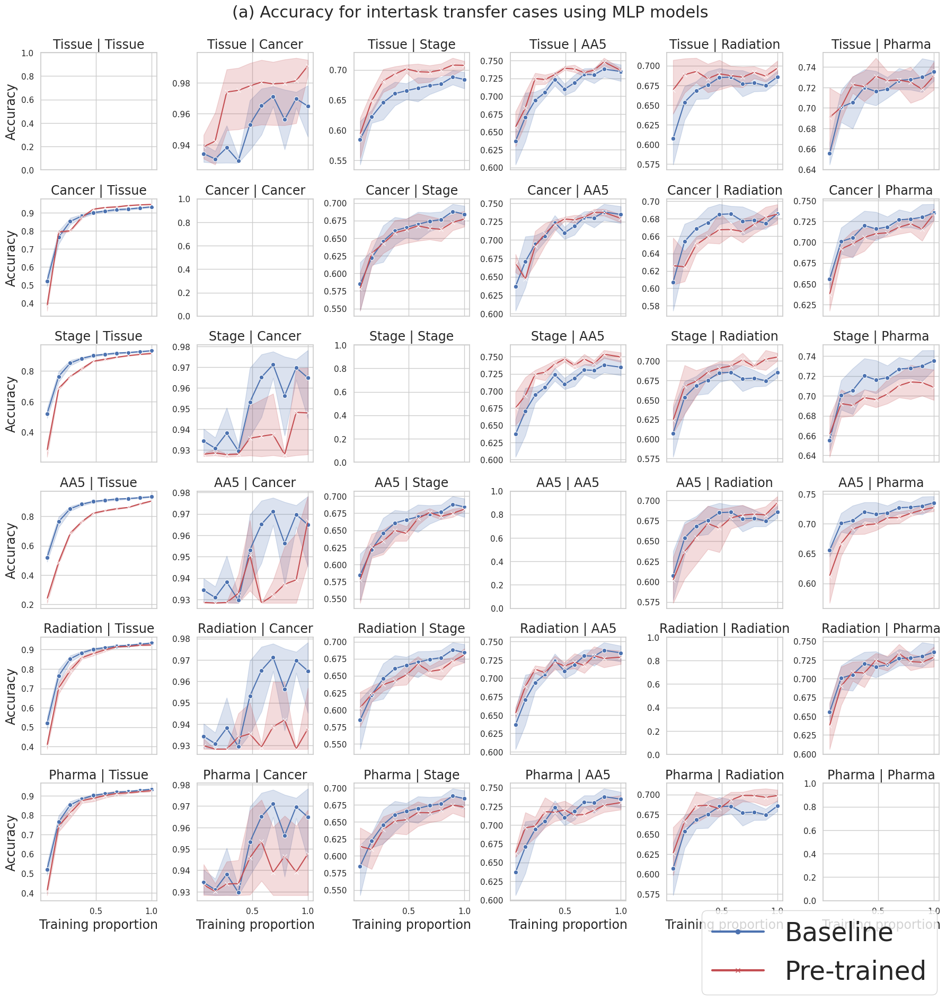

In [37]:
# Set a style
plt.figure()
sns.set(style="whitegrid")
tasks = ['Tissue', 'Cancer', 'Stage', 'AA5', 'Radiation', 'Pharma']

# FacetGrid: rows = source, columns = target
g = sns.FacetGrid(
    df_long,
    col="target_task",
    row="source_task",
    sharey=False,
    sharex=True,
    margin_titles=False,
    despine=False,
    row_order=tasks,
    col_order=tasks
)

# Map lineplot to each facet
g.map_dataframe(
    sns.lineplot,
    x="train_samples",
    y="max_test_accuracy",
    marker="o",
)

g.map_dataframe(
    sns.lineplot,
    x="train_samples",
    y="max_test_accuracy_finetuned",
    marker="x",
    color='r'
)


# Set axis labels
g.set_axis_labels("Training proportion", "Accuracy")
g.set_titles(row_template="{row_name}", col_template="{col_name}")


# Set axis labels
g.set_axis_labels("Training proportion", "Accuracy", size=17)
g.set_titles(row_template="{row_name}", col_template="{col_name}", size=17)

# Create custom legend handles
line1 = mlines.Line2D([], [], color='C0', marker='o', label='Baseline', linewidth=3)
line2 = mlines.Line2D([], [], color='r', marker='x', label='Pre-trained', linewidth=3)
# Get bottom-right axis
ax = g.axes[-1, -1]
# Add legend there
g.fig.legend(handles=[line1, line2], loc='lower right', fontsize=35, bbox_to_anchor=(1.0, -0.07))

for i, source in zip(range(len(tasks)), tasks):
    ax = g.axes[i,-1]
    #ax.text(1.1, 0.5, f"Source task: {source}", va='center', fontsize=17, transform=ax.transAxes)
g.fig.suptitle('(a) Accuracy for intertask transfer cases using MLP models \n', fontsize=22)
#g.fig.set_size_inches(30, 6)


# Adjust spacing
plt.tight_layout()
g.savefig("intertask_grid_plot.png", dpi=300, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

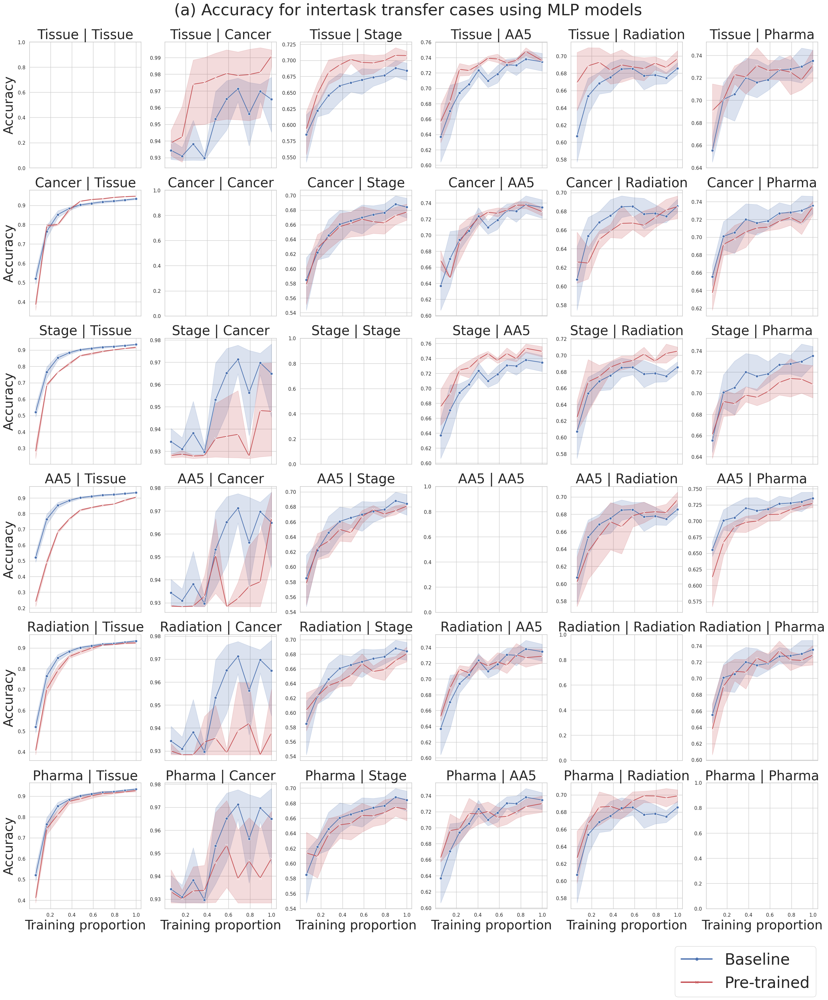

In [38]:
# Set a style
plt.figure()
sns.set(style="whitegrid")
tasks = ['Tissue', 'Cancer', 'Stage', 'AA5', 'Radiation', 'Pharma']

# FacetGrid: rows = source, columns = target
g = sns.FacetGrid(
    df_long,
    col="target_task",
    row="source_task",
    sharey=False,
    sharex=True,
    margin_titles=False,
    despine=False,
    row_order=tasks,
    col_order=tasks
)

# Map lineplot to each facet
g.map_dataframe(
    sns.lineplot,
    x="train_samples",
    y="max_test_accuracy",
    marker="o",
)

g.map_dataframe(
    sns.lineplot,
    x="train_samples",
    y="max_test_accuracy_finetuned",
    marker="x",
    color='r'
)


# Set axis labels
g.set_axis_labels("Training proportion", "Accuracy")
g.set_titles(row_template="{row_name}", col_template="{col_name}")


# Set axis labels
g.set_axis_labels("Training proportion", "Accuracy", size=29)
g.set_titles(row_template="{row_name}", col_template="{col_name}", size=30)


# Create custom legend handles
line1 = mlines.Line2D([], [], color='C0', marker='o', label='Baseline', linewidth=3)
line2 = mlines.Line2D([], [], color='r', marker='x', label='Pre-trained', linewidth=3)
# Get bottom-right axis
ax = g.axes[-1, -1]
# Add legend there
g.fig.legend(handles=[line1, line2], loc='lower right', fontsize=35, bbox_to_anchor=(1.0, -0.07))


g.fig.suptitle('(a) Accuracy for intertask transfer cases using MLP models \n', fontsize=36)
g.fig.set_size_inches(26, 30)


# Adjust spacing
plt.tight_layout()
g.savefig("intertask_grid_plot.png", dpi=300, bbox_inches="tight")
plt.show()

In [124]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

## MLP AUPC

In [7]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    #print(df.columns)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col(column).max().alias(f"max_{column}"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)

    return all_data

def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", metric])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df

def get_mauc(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", metric])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    mauc = auc(df['train_samples'], df['max_test_accuracy'])
    return mauc

def compute_macc(source_task, target_task, v=0, metric="max_test_accuracy"):
    baseline_str = 'train_' + target_task + '_linspace_training'
    finetuned_str = source_task + '_to_' + target_task + '_'
    auc_baseline = compute_aupc(baseline_str, version = v, metric=metric)
    auc_finetuned = compute_aupc_multitask(finetuned_str, version = v, metric=metric)
    return auc_finetuned - auc_baseline, auc_finetuned, auc_baseline

In [8]:
#tasks = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model', 'radiation_model', 'pharma_model']
source_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
target_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df = pl.DataFrame()
df_dict = {}
df_prop_dict = {}

for source_task in source_tasks: 
    for target_task in target_tasks:
        if source_task != target_task:
            print(f'{source_task}-{target_task}-----')
            df_baseline = pl.DataFrame()
            df_finetuned = pl.DataFrame()
            for version in range(5):
                #print(version)
                baseline_str = 'intertask/mlp/train_' + target_task + '_linspace_training'
                finetuned_str = 'intertask/mlp/' + source_task + '_to_' + target_task + '_'
                df_temp_baseline = get_df(baseline_str, version=version)
                df_temp_finetuned = get_df(finetuned_str, version=version)
                df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
                df_baseline = df_baseline.sort('train_samples')
                df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
                #print(df_finetuned)
                df_finetuned = df_finetuned.sort('train_samples')
            
            #print(df_baseline['train_samples'])
            #print(list(df_finetuned['train_samples']))
            print('-----')
            df = df_baseline.with_columns(df_finetuned['max_test_accuracy'].alias('max_test_accuracy_finetuned'))
            result_prop = (
                df
                .group_by("train_samples")
                .agg(
                    pl.col("max_test_accuracy").alias("accuracy_list")
                )
                .sort("train_samples")  # optional
            )
            result_prop_finetuned = (
                df
                .group_by("train_samples")
                .agg(
                    pl.col("max_test_accuracy_finetuned").alias("accuracy_list_finetuned")
                )
                .sort("train_samples")  # optional
            )
            result_prop = result_prop.with_columns(result_prop_finetuned["accuracy_list_finetuned"])
            #s = pl.Series("train_samples", [f"p_{i}" for i in range(len(result_prop['train_samples']))])
            #result_prop.replace_column(0, s)
            #print(result_prop)
            df_prop_dict[(source_task, target_task)] = result_prop

tissue_model-cancer_model-----
-----
tissue_model-stage_model-----
-----
tissue_model-aa5_model-----
-----
tissue_model-radiation_model-----
-----
tissue_model-pharma_model-----
-----
cancer_model-tissue_model-----
-----
cancer_model-stage_model-----
-----
cancer_model-aa5_model-----
-----
cancer_model-radiation_model-----
-----
cancer_model-pharma_model-----
-----
stage_model-tissue_model-----
-----
stage_model-cancer_model-----
-----
stage_model-aa5_model-----
-----
stage_model-radiation_model-----
-----
stage_model-pharma_model-----
-----
aa5_model-tissue_model-----
-----
aa5_model-cancer_model-----
-----
aa5_model-stage_model-----
-----
aa5_model-radiation_model-----
-----
aa5_model-pharma_model-----
-----
radiation_model-tissue_model-----
-----
radiation_model-cancer_model-----
-----
radiation_model-stage_model-----
-----
radiation_model-aa5_model-----
-----
radiation_model-pharma_model-----
-----
pharma_model-tissue_model-----
-----
pharma_model-cancer_model-----
-----
pharma_mod

In [10]:
print(np.array([row for row in df_prop_dict[('tissue_model','cancer_model')]['accuracy_list']]))

[[0.92834225 0.92834225 0.93101604 0.94438503 0.93957219]
 [0.92834225 0.92834225 0.94117647 0.92834225 0.92834225]
 [0.96417112 0.92834225 0.92887701 0.92834225 0.94117647]
 [0.92834225 0.92834225 0.92834225 0.92834225 0.93475936]
 [0.9342246  0.97005348 0.92834225 0.97486631 0.95828877]
 [0.97807487 0.96951872 0.97486631 0.97486631 0.92834225]
 [0.97860963 0.9657754  0.97272727 0.97914439 0.95989305]
 [0.92834225 0.97700535 0.92834225 0.97593583 0.97165775]
 [0.95882353 0.97379679 0.97272727 0.97486631 0.9684492 ]
 [0.97860963 0.97860963 0.97647059 0.92834225 0.96256684]]


In [11]:
df_prop_dict[('tissue_model','cancer_model')]

train_samples,accuracy_list,accuracy_list_finetuned
f64,list[f64],list[f64]
0.0625,"[0.928342, 0.928342, … 0.939572]","[0.944385, 0.946524, … 0.927263]"
0.16625,"[0.928342, 0.928342, … 0.928342]","[0.928342, 0.974332, … 0.925647]"
0.27,"[0.964171, 0.928342, … 0.941176]","[0.979679, 0.990909, … 0.925647]"
0.375,"[0.928342, 0.928342, … 0.934759]","[0.982888, 0.993048, … 0.926185]"
0.47875,"[0.934225, 0.970053, … 0.958289]","[0.988235, 0.995187, … 0.926185]"
0.5825,"[0.978075, 0.969519, … 0.928342]","[0.993583, 0.995187, … 0.925647]"
0.6875,"[0.97861, 0.965775, … 0.959893]","[0.990374, 0.994652, … 0.926185]"
0.79125,"[0.928342, 0.977005, … 0.971658]","[0.989305, 0.996257, … 0.925647]"
0.895,"[0.958824, 0.973797, … 0.968449]","[0.993048, 0.994652, … 0.926724]"


In [12]:
df_mauc = pd.DataFrame(columns=['source', 'target', 'mauc_mean', 'mauc_std', 'mauc_mean_finetuned', 'mauc_std_finetuned', 'p-value'])
df_mauc_save = pd.DataFrame(columns=['source', 'target', 'mauc', 'mauc_finetuned', 'p-value'])
source_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
target_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
source_list, target_list, mean_list, std_list = [], [], [], []
mean_finetuned_list, std_finetuned_list = [], []
p_value_list = []

mean_list_prop, mean_list_prop_finetuned = [], []
std_list_prop, std_list_prop_finetuned = [], []
p_value_prop = []
for source_task in source_tasks:
    for target_task in target_tasks:
        if source_task != target_task:
            source_list.append(source_task)
            target_list.append(target_task)
            perf_matrix = np.array([row for row in df_prop_dict[(source_task,target_task)]['accuracy_list']])
            prop_matrix = np.array([row for row in df_prop_dict[(source_task,target_task)]['train_samples']])
            mauc = [auc(prop_matrix, perf_matrix[:,i]) for i in range(perf_matrix.shape[1])]
            mean_list.append(np.mean(mauc))
            std_list.append(np.std(mauc))
            perf_matrix_finetuned = np.array([row for row in df_prop_dict[(source_task,target_task)]['accuracy_list_finetuned']])
            prop_matrix_finetuned = np.array([row for row in df_prop_dict[(source_task,target_task)]['train_samples']])
            mauc_finetuned = [auc(prop_matrix_finetuned, perf_matrix_finetuned[:,i]) for i in range(perf_matrix_finetuned.shape[1])]
            mean_finetuned_list.append(np.mean(mauc_finetuned))
            std_finetuned_list.append(np.std(mauc_finetuned))
            t_stat, p_value = stats.ttest_rel(mauc, mauc_finetuned)
            p_value_list.append(p_value)
            
            mean_list_prop.append(np.mean(perf_matrix, axis=1))
            mean_list_prop_finetuned.append(np.mean(perf_matrix_finetuned, axis=1))
            std_list_prop.append(np.std(perf_matrix, axis=1))
            std_list_prop_finetuned.append(np.std(perf_matrix_finetuned, axis=1))
            p_value_prop.append([stats.ttest_rel(perf_matrix[i], perf_matrix_finetuned[i])[1] for i in range(perf_matrix.shape[0])])

df_mauc['source'] = source_list
df_mauc['target'] = target_list
df_mauc['mauc_mean'] = mean_list
df_mauc['mauc_std'] = std_list
df_mauc['mauc_mean_finetuned'] = mean_finetuned_list
df_mauc['mauc_std_finetuned'] = std_finetuned_list
df_mauc['p-value'] = p_value_list
df_mauc['mean_by_prop'] = mean_list_prop
df_mauc['std_by_prop'] = std_list_prop
df_mauc['mean_by_prop_finetuned'] = mean_list_prop_finetuned
df_mauc['std_by_prop_finetuned'] = std_list_prop_finetuned
df_mauc['p-value_by_prop'] = p_value_prop

df_mauc_save['source'] = source_list
df_mauc_save['target'] = target_list
df_mauc_save['mauc'] = [f'{np.round(mean, 4)} ± {np.round(std, 4)}' for mean, std in zip(mean_list, std_list)]
df_mauc_save['mauc_finetuned'] = [f'{np.round(mean, 4)} ± {np.round(std, 4)}' for mean, std in zip(mean_finetuned_list, std_finetuned_list)]
df_mauc_save['p-value'] = p_value_list

In [14]:
df_mauc_save.to_csv('table_intertask_mlp.csv')

### Link by M_auc

In [149]:
for i in range(len(df_mauc.index)):
    row = df_mauc.iloc[i]
    source, target = row['source'], row['target']
    p_value = row['p-value']
    mauc_baseline, mauc_finetuned = row['mauc_mean'], row['mauc_mean_finetuned']
    if mauc_baseline < mauc_finetuned and p_value < 0.06:
        print(f'{source} to {target} beneficial')

tissue_model to stage_model beneficial
stage_model to aa5_model beneficial
stage_model to radiation_model beneficial
pharma_model to radiation_model beneficial


### Link by prop 

In [150]:
for i in range(len(df_mauc.index)):
    row = df_mauc.iloc[i]
    source, target = row['source'], row['target']
    p_value_list = row['p-value_by_prop']
    mean_baseline_list, mean_finetuned_list = row['mean_by_prop'], row['mean_by_prop_finetuned']
    count = 0
    for mean_baseline, mean_finetuned, p_value, prop in zip(mean_baseline_list, mean_finetuned_list, p_value_list, range(10)):
        if mean_baseline < mean_finetuned and p_value < 0.06:
            count += 1
            if count >= 3: 
                print(f'{source} to {target} beneficial')
                break

tissue_model to cancer_model beneficial
tissue_model to stage_model beneficial
tissue_model to aa5_model beneficial
cancer_model to tissue_model beneficial
stage_model to aa5_model beneficial


## Intertask GNN

In [16]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    #print(df.columns)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col(column).max().alias(f"max_{column}"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)

    return all_data

def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", metric])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df

def compute_macc(source_task, target_task, v=0, metric="max_test_accuracy"):
    baseline_str = 'train_' + target_task + '_linspace_training'
    finetuned_str = source_task + '_to_' + target_task + '_'
    auc_baseline = compute_aupc(baseline_str, version = v, metric=metric)
    auc_finetuned = compute_aupc_multitask(finetuned_str, version = v, metric=metric)
    return auc_finetuned - auc_baseline, auc_finetuned, auc_baseline

In [52]:
#tasks = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model', 'radiation_model', 'pharma_model']
source_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
target_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
#source_tasks = ['tissue_model', 'cancer_model','aa5_model']
#target_tasks = ['tissue_model', 'cancer_model','aa5_model']
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df = pl.DataFrame()
df_dict = {}
df_prop_dict = {}

for source_task in source_tasks: 
    for target_task in target_tasks:
        if source_task != target_task:
            print(f'{source_task}-{target_task}-----')
            df_baseline = pl.DataFrame()
            df_finetuned = pl.DataFrame()
            #for version, v2 in zip(range(5), [0,1,2,6,7]):
            for version in range(5):
                #print(version)
                baseline_str = 'intertask/gnn/train_GNN_' + target_task + '_linspace_training'
                finetuned_str = 'intertask/gnn/GNN_' + source_task + '_to_' + target_task + '_'
                df_temp_baseline = get_df(baseline_str, version=version)
                df_temp_finetuned = get_df(finetuned_str, version=version)
                df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
                df_baseline = df_baseline.sort('train_samples')
                df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
                print(df_temp_baseline.shape)
                #print('baseline', df_baseline.shape)
                df_finetuned = df_finetuned.sort('train_samples')
            
            #print(df_baseline['train_samples'])
            #print(list(df_finetuned['train_samples']))
            print('-----')
            df = df_baseline.with_columns(df_finetuned['max_test_accuracy'].alias('max_test_accuracy_finetuned'))
            result_prop = (
                df
                .group_by("train_samples")
                .agg(
                    pl.col("max_test_accuracy").alias("accuracy_list")
                )
                .sort("train_samples")  # optional
            )
            result_prop_finetuned = (
                df
                .group_by("train_samples")
                .agg(
                    pl.col("max_test_accuracy_finetuned").alias("accuracy_list_finetuned")
                )
                .sort("train_samples")  # optional
            )
            result_prop = result_prop.with_columns(result_prop_finetuned["accuracy_list_finetuned"])
            s = pl.Series("train_samples", [f"p_{i}" for i in range(len(result_prop['train_samples']))])
            result_prop.replace_column(0, s)
            #print(result_prop)
            df_prop_dict[(source_task, target_task)] = result_prop

tissue_model-cancer_model-----
(10, 2)
(10, 2)
(10, 2)
(10, 2)
(10, 2)
-----
tissue_model-stage_model-----
(10, 2)
(10, 2)
(10, 2)
(10, 2)
(10, 2)
-----
tissue_model-aa5_model-----
(11, 2)
(11, 2)
(11, 2)
(11, 2)
(11, 2)
-----
tissue_model-radiation_model-----
(10, 2)
(10, 2)
(10, 2)
(10, 2)
(10, 2)
-----
tissue_model-pharma_model-----
(10, 2)
(10, 2)
(10, 2)
(10, 2)
(10, 2)
-----
cancer_model-tissue_model-----
(10, 2)
(10, 2)
(10, 2)
(10, 2)
(10, 2)
-----
cancer_model-stage_model-----
(10, 2)
(10, 2)
(10, 2)
(10, 2)
(10, 2)
-----
cancer_model-aa5_model-----
(11, 2)
(11, 2)
(11, 2)
(11, 2)
(11, 2)
-----
cancer_model-radiation_model-----
(10, 2)
(10, 2)
(10, 2)
(10, 2)
(10, 2)
-----
cancer_model-pharma_model-----
(10, 2)
(10, 2)
(10, 2)
(10, 2)
(10, 2)
-----
stage_model-tissue_model-----
(10, 2)
(10, 2)
(10, 2)
(10, 2)
(10, 2)
-----
stage_model-cancer_model-----
(10, 2)
(10, 2)
(10, 2)
(10, 2)
(10, 2)
-----
stage_model-aa5_model-----
(11, 2)
(11, 2)
(11, 2)
(11, 2)
(11, 2)
-----
stage_m

## Grid plot

In [17]:
#tasks = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model', 'radiation_model', 'pharma_model']
source_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
target_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df = pl.DataFrame()
df_dict = {}
df_prop_dict = {}
df_prop_dict_intertask = {}

for source_task in source_tasks: 
    for target_task in target_tasks:
        if source_task != target_task:
            print(f'{source_task}-{target_task}-----')
            df_baseline = pl.DataFrame()
            df_finetuned = pl.DataFrame()
            for version in range(5):
                #print(version)
                baseline_str = 'intertask/gnn/train_GNN_' + target_task + '_linspace_training'
                finetuned_str = 'intertask/gnn/GNN_' + source_task + '_to_' + target_task + '_'
                df_temp_baseline = get_df(baseline_str, version=version)
                df_temp_finetuned = get_df(finetuned_str, version=version)
                df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
                df_baseline = df_baseline.sort('train_samples')
                df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
                #print(df_finetuned)
                df_finetuned = df_finetuned.sort('train_samples')
            
            #print(df_baseline['train_samples'])
            #print(list(df_finetuned['train_samples']))
            #print(df_baseline)
            print('-----')
            df = df_baseline.with_columns(df_finetuned['max_test_accuracy'].alias('max_test_accuracy_finetuned'))
            if source_task=='aa5_model': 
                df_prop_dict[('AA5_model',target_task)] = df
                df_prop_dict_intertask[('AA5_model',target_task)] = df
            elif target_task=='aa5_model': 
                df_prop_dict[(source_task,'AA5_model')] = df
                df_prop_dict_intertask[(source_task,'AA5_model')] = df
            else: 
                df_prop_dict[(source_task,target_task)] = df
                df_prop_dict_intertask[(source_task,target_task)] = df

tissue_model-cancer_model-----
-----
tissue_model-stage_model-----
-----
tissue_model-aa5_model-----
-----
tissue_model-radiation_model-----
-----
tissue_model-pharma_model-----
-----
cancer_model-tissue_model-----
-----
cancer_model-stage_model-----
-----
cancer_model-aa5_model-----
-----
cancer_model-radiation_model-----
-----
cancer_model-pharma_model-----
-----
stage_model-tissue_model-----
-----
stage_model-cancer_model-----
-----
stage_model-aa5_model-----
-----
stage_model-radiation_model-----
-----
stage_model-pharma_model-----
-----
aa5_model-tissue_model-----
-----
aa5_model-cancer_model-----
-----
aa5_model-stage_model-----
-----
aa5_model-radiation_model-----
-----
aa5_model-pharma_model-----
-----
radiation_model-tissue_model-----
-----
radiation_model-cancer_model-----
-----
radiation_model-stage_model-----
-----
radiation_model-aa5_model-----
-----
radiation_model-pharma_model-----
-----
pharma_model-tissue_model-----
-----
pharma_model-cancer_model-----
-----
pharma_mod

In [18]:
rows = []
for (source, target), df in df_prop_dict.items():
    print(source,target)
    for ts, acc, acc_ft in zip(df['train_samples'], df['max_test_accuracy'], df['max_test_accuracy_finetuned']):
        if target=='AA5_model':
            rows.append({
                "source_task": source.split('_')[0].capitalize(),
                "target_task": target.split('_')[0],
                "train_samples": ts,
                "max_test_accuracy": acc,
                "max_test_accuracy_finetuned": acc_ft
            })
        if source=='AA5_model':
            rows.append({
                "source_task": source.split('_')[0],
                "target_task": target.split('_')[0].capitalize(),
                "train_samples": ts,
                "max_test_accuracy": acc,
                "max_test_accuracy_finetuned": acc_ft
            })
        else:
            rows.append({
                "source_task": source.split('_')[0].capitalize(),
                "target_task": target.split('_')[0].capitalize(),
                "train_samples": ts,
                "max_test_accuracy": acc,
                "max_test_accuracy_finetuned": acc_ft
            })

df_long = pd.DataFrame(rows)

tissue_model cancer_model
tissue_model stage_model
tissue_model AA5_model
tissue_model radiation_model
tissue_model pharma_model
cancer_model tissue_model
cancer_model stage_model
cancer_model AA5_model
cancer_model radiation_model
cancer_model pharma_model
stage_model tissue_model
stage_model cancer_model
stage_model AA5_model
stage_model radiation_model
stage_model pharma_model
AA5_model tissue_model
AA5_model cancer_model
AA5_model stage_model
AA5_model radiation_model
AA5_model pharma_model
radiation_model tissue_model
radiation_model cancer_model
radiation_model stage_model
radiation_model AA5_model
radiation_model pharma_model
pharma_model tissue_model
pharma_model cancer_model
pharma_model stage_model
pharma_model AA5_model
pharma_model radiation_model


<Figure size 640x480 with 0 Axes>

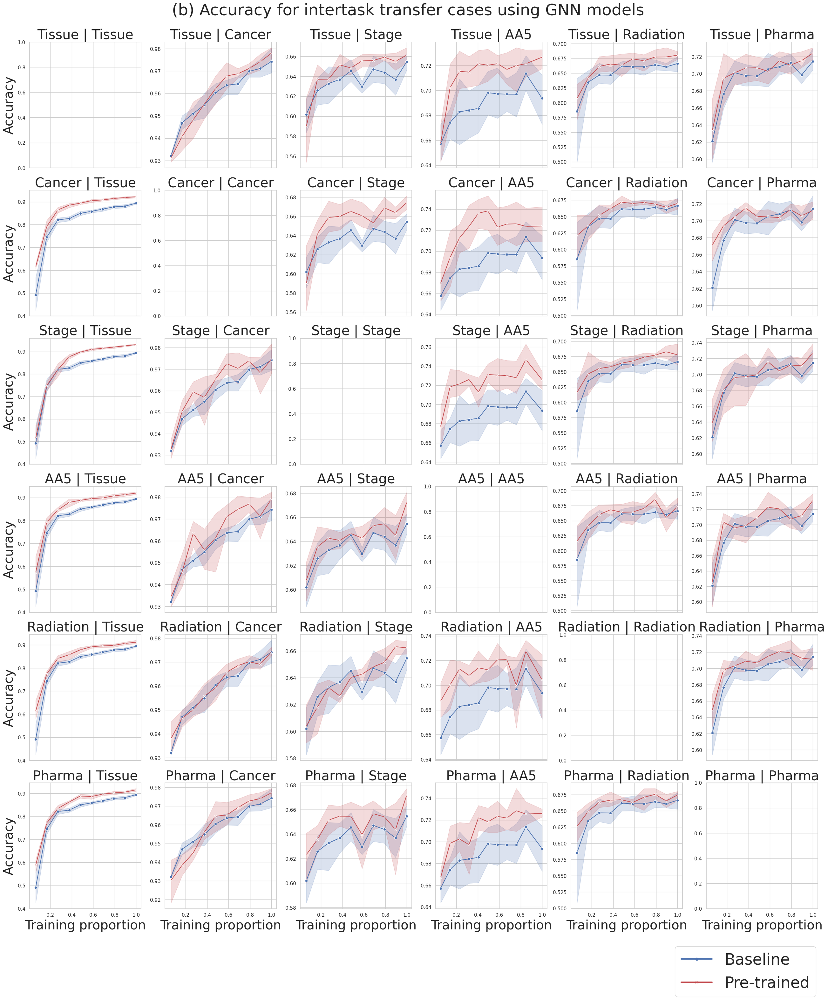

In [32]:
# Set a style
plt.figure()
sns.set(style="whitegrid")
tasks = ['Tissue', 'Cancer', 'Stage', 'AA5', 'Radiation', 'Pharma']

# FacetGrid: rows = source, columns = target
g = sns.FacetGrid(
    df_long,
    col="target_task",
    row="source_task",
    sharey=False,
    sharex=True,
    margin_titles=False,
    despine=False, 
    row_order=tasks,
    col_order=tasks
)

# Map lineplot to each facet
g.map_dataframe(
    sns.lineplot,
    x="train_samples",
    y="max_test_accuracy",
    marker="o",
)

g.map_dataframe(
    sns.lineplot,
    x="train_samples",
    y="max_test_accuracy_finetuned",
    marker="x",
    color='r'
)


# Set axis labels
g.set_axis_labels("Training proportion", "Accuracy", size=29)
g.set_titles(row_template="{row_name}", col_template="{col_name}", size=30)

# Create custom legend handles
line1 = mlines.Line2D([], [], color='C0', marker='o', label='Baseline', linewidth=3)
line2 = mlines.Line2D([], [], color='r', marker='x', label='Pre-trained', linewidth=3)
# Get bottom-right axis
ax = g.axes[-1, -1]
# Add legend there
g.fig.legend(handles=[line1, line2], loc='lower right', fontsize=35, bbox_to_anchor=(1.0, -0.07))

for i, source in zip(range(len(tasks)), tasks):
    ax = g.axes[i,-1]
    #ax.text(1.1, 0.5, f"Source task: {source}", va='center', fontsize=32, transform=ax.transAxes)
g.fig.suptitle('(b) Accuracy for intertask transfer cases using GNN models \n', fontsize=36)
g.fig.set_size_inches(26, 30)

# Adjust spacing
plt.tight_layout()
g.savefig("gnn_intertask_grid_plot.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
df_long

,source_task,target_task,train_samples,max_test_accuracy,max_test_accuracy_finetuned
0,tissue,cancer,0.0625,0.932620,0.929947
1,tissue,cancer,0.0625,0.932086,0.929947
2,tissue,cancer,0.0625,0.931551,0.928342
3,tissue,cancer,0.0625,0.933690,0.932620
4,tissue,cancer,0.0625,0.930481,0.934759
...,...,...,...,...,...
1520,pharma,radiation,1.0000,0.641543,0.658195
1521,pharma,radiation,1.0000,0.673970,0.680105
1522,pharma,radiation,1.0000,0.664330,0.673970
1523,pharma,radiation,1.0000,0.664330,0.679229


## GNN AUPC

In [15]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    #print(df.columns)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col(column).max().alias(f"max_{column}"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)

    return all_data

def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", metric])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df

def get_mauc(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", metric])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    mauc = auc(df['train_samples'], df['max_test_accuracy'])
    return mauc

def compute_macc(source_task, target_task, v=0, metric="max_test_accuracy"):
    baseline_str = 'train_' + target_task + '_linspace_training'
    finetuned_str = source_task + '_to_' + target_task + '_'
    auc_baseline = compute_aupc(baseline_str, version = v, metric=metric)
    auc_finetuned = compute_aupc_multitask(finetuned_str, version = v, metric=metric)
    return auc_finetuned - auc_baseline, auc_finetuned, auc_baseline

In [16]:
#tasks = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model', 'radiation_model', 'pharma_model']
source_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
target_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
#source_tasks = ['tissue_model', 'cancer_model','aa5_model']
#target_tasks = ['tissue_model', 'cancer_model','aa5_model']
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df = pl.DataFrame()
df_dict = {}
df_prop_dict = {}

for source_task in source_tasks: 
    for target_task in target_tasks:
        if source_task != target_task:
            print(f'{source_task}-{target_task}-----')
            df_baseline = pl.DataFrame()
            df_finetuned = pl.DataFrame()
            #for version, v2 in zip(range(5), [0,1,2,6,7]):
            for version in range(5):
                #print(version)
                baseline_str = 'intertask/gnn/train_GNN_' + target_task + '_linspace_training'
                finetuned_str = 'intertask/gnn/GNN_' + source_task + '_to_' + target_task + '_'
                df_temp_baseline = get_df(baseline_str, version=version)
                df_temp_finetuned = get_df(finetuned_str, version=version)
                df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
                df_baseline = df_baseline.sort('train_samples')
                df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
                print(df_temp_baseline.shape)
                #print('baseline', df_baseline.shape)
                df_finetuned = df_finetuned.sort('train_samples')
            
            #print(df_baseline['train_samples'])
            #print(list(df_finetuned['train_samples']))
            print('-----')
            df = df_baseline.with_columns(df_finetuned['max_test_accuracy'].alias('max_test_accuracy_finetuned'))
            result_prop = (
                df
                .group_by("train_samples")
                .agg(
                    pl.col("max_test_accuracy").alias("accuracy_list")
                )
                .sort("train_samples")  # optional
            )
            result_prop_finetuned = (
                df
                .group_by("train_samples")
                .agg(
                    pl.col("max_test_accuracy_finetuned").alias("accuracy_list_finetuned")
                )
                .sort("train_samples")  # optional
            )
            result_prop = result_prop.with_columns(result_prop_finetuned["accuracy_list_finetuned"])
            #s = pl.Series("train_samples", [f"p_{i}" for i in range(len(result_prop['train_samples']))])
            #result_prop.replace_column(0, s)
            #print(result_prop)
            df_prop_dict[(source_task, target_task)] = result_prop

tissue_model-cancer_model-----
(10, 2)
(10, 2)
(10, 2)
(10, 2)
(10, 2)
-----
tissue_model-stage_model-----
(10, 2)
(10, 2)
(10, 2)
(10, 2)
(10, 2)
-----
tissue_model-aa5_model-----
(11, 2)
(11, 2)
(11, 2)
(11, 2)
(11, 2)
-----
tissue_model-radiation_model-----
(10, 2)
(10, 2)
(10, 2)
(10, 2)
(10, 2)
-----
tissue_model-pharma_model-----
(10, 2)
(10, 2)
(10, 2)
(10, 2)
(10, 2)
-----
cancer_model-tissue_model-----
(10, 2)
(10, 2)
(10, 2)
(10, 2)
(10, 2)
-----
cancer_model-stage_model-----
(10, 2)
(10, 2)
(10, 2)
(10, 2)
(10, 2)
-----
cancer_model-aa5_model-----
(11, 2)
(11, 2)
(11, 2)
(11, 2)
(11, 2)
-----
cancer_model-radiation_model-----
(10, 2)
(10, 2)
(10, 2)
(10, 2)
(10, 2)
-----
cancer_model-pharma_model-----
(10, 2)
(10, 2)
(10, 2)
(10, 2)
(10, 2)
-----
stage_model-tissue_model-----
(10, 2)
(10, 2)
(10, 2)
(10, 2)
(10, 2)
-----
stage_model-cancer_model-----
(10, 2)
(10, 2)
(10, 2)
(10, 2)
(10, 2)
-----
stage_model-aa5_model-----
(11, 2)
(11, 2)
(11, 2)
(11, 2)
(11, 2)
-----
stage_m

In [17]:
df_mauc = pd.DataFrame(columns=['source', 'target', 'mauc_mean', 'mauc_std', 'mauc_mean_finetuned', 'mauc_std_finetuned', 'p-value'])
source_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
target_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
source_list, target_list, mean_list, std_list = [], [], [], []
mean_finetuned_list, std_finetuned_list = [], []
p_value_list = []

mean_list_prop, mean_list_prop_finetuned = [], []
std_list_prop, std_list_prop_finetuned = [], []
p_value_prop = []
for source_task in source_tasks:
    for target_task in target_tasks:
        if source_task != target_task:
            source_list.append(source_task)
            target_list.append(target_task)
            perf_matrix = np.array([row for row in df_prop_dict[(source_task,target_task)]['accuracy_list']])
            prop_matrix = np.array([row for row in df_prop_dict[(source_task,target_task)]['train_samples']])
            mauc = [auc(prop_matrix, perf_matrix[:,i]) for i in range(perf_matrix.shape[1])]
            mean_list.append(np.mean(mauc))
            std_list.append(np.std(mauc))
            perf_matrix_finetuned = np.array([row for row in df_prop_dict[(source_task,target_task)]['accuracy_list_finetuned']])
            prop_matrix_finetuned = np.array([row for row in df_prop_dict[(source_task,target_task)]['train_samples']])
            mauc_finetuned = [auc(prop_matrix_finetuned, perf_matrix_finetuned[:,i]) for i in range(perf_matrix_finetuned.shape[1])]
            mean_finetuned_list.append(np.mean(mauc_finetuned))
            std_finetuned_list.append(np.std(mauc_finetuned))
            t_stat, p_value = stats.ttest_rel(mauc, mauc_finetuned)
            p_value_list.append(p_value)
            
            mean_list_prop.append(np.mean(perf_matrix, axis=1))
            mean_list_prop_finetuned.append(np.mean(perf_matrix_finetuned, axis=1))
            std_list_prop.append(np.std(perf_matrix, axis=1))
            std_list_prop_finetuned.append(np.std(perf_matrix_finetuned, axis=1))
            p_value_prop.append([stats.ttest_rel(perf_matrix[i], perf_matrix_finetuned[i])[1] for i in range(perf_matrix.shape[0])])

df_mauc['source'] = source_list
df_mauc['target'] = target_list
df_mauc['mauc_mean'] = mean_list
df_mauc['mauc_std'] = std_list
df_mauc['mauc_mean_finetuned'] = mean_finetuned_list
df_mauc['mauc_std_finetuned'] = std_finetuned_list
df_mauc['p-value'] = p_value_list
df_mauc['mean_by_prop'] = mean_list_prop
df_mauc['std_by_prop'] = std_list_prop
df_mauc['mean_by_prop_finetuned'] = mean_list_prop_finetuned
df_mauc['std_by_prop_finetuned'] = std_list_prop_finetuned
df_mauc['p-value_by_prop'] = p_value_prop

df_mauc_save['source'] = source_list
df_mauc_save['target'] = target_list
df_mauc_save['mauc'] = [f'{np.round(mean, 4)} ± {np.round(std, 4)}' for mean, std in zip(mean_list, std_list)]
df_mauc_save['mauc_finetuned'] = [f'{np.round(mean, 4)} ± {np.round(std, 4)}' for mean, std in zip(mean_finetuned_list, std_finetuned_list)]
df_mauc_save['p-value'] = [np.round(i, 4) for i in p_value_list]

In [18]:
df_mauc_save.to_csv('table_intertask_gnn.csv')

In [154]:
for i in range(len(df_mauc.index)):
    row = df_mauc.iloc[i]
    source, target = row['source'], row['target']
    p_value = row['p-value']
    mauc_baseline, mauc_finetuned = row['mauc_mean'], row['mauc_mean_finetuned']
    if mauc_baseline < mauc_finetuned and p_value < 0.05:
        print(f'{source} to {target} beneficial')

cancer_model to tissue_model beneficial
stage_model to tissue_model beneficial
stage_model to cancer_model beneficial
stage_model to aa5_model beneficial
aa5_model to tissue_model beneficial
radiation_model to tissue_model beneficial
pharma_model to tissue_model beneficial
pharma_model to aa5_model beneficial


In [155]:
for i in range(len(df_mauc.index)):
    row = df_mauc.iloc[i]
    source, target = row['source'], row['target']
    p_value_list = row['p-value_by_prop']
    mean_baseline_list, mean_finetuned_list = row['mean_by_prop'], row['mean_by_prop_finetuned']
    count = 0
    for mean_baseline, mean_finetuned, p_value, prop in zip(mean_baseline_list, mean_finetuned_list, p_value_list, range(10)):
        if mean_baseline < mean_finetuned and p_value < 0.06:
            count += 1
            if count >= 3: 
                print(f'{source} to {target} beneficial')
                break

cancer_model to tissue_model beneficial
cancer_model to stage_model beneficial
stage_model to tissue_model beneficial
stage_model to cancer_model beneficial
stage_model to aa5_model beneficial
aa5_model to tissue_model beneficial
radiation_model to tissue_model beneficial
radiation_model to aa5_model beneficial
pharma_model to tissue_model beneficial
pharma_model to aa5_model beneficial


## Merge grid plot

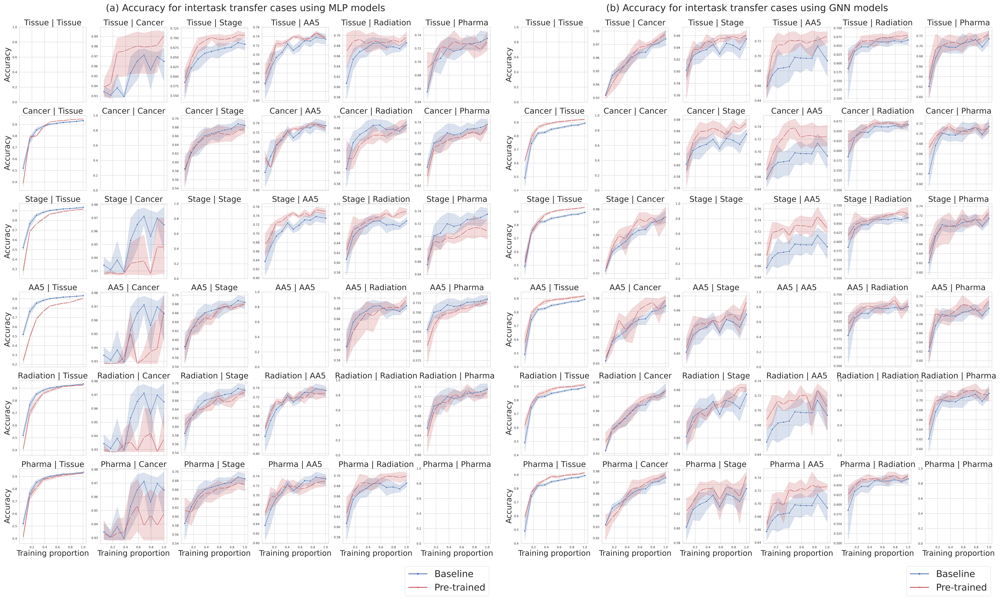

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(50, 30))

img1 = plt.imread("intertask_grid_plot.png")
img2 = plt.imread("gnn_intertask_grid_plot.png")

axes[0].imshow(img1)
axes[0].axis("off")

axes[1].imshow(img2)
axes[1].axis("off")

plt.tight_layout()
plt.savefig('intertask_grid_plot_merged.png')
plt.show()

## AUAC Table for both archi

In [61]:
table_mlp = pd.read_csv('table_intertask_mlp.csv')
table_gnn = pd.read_csv('table_intertask_gnn.csv')

In [62]:
table_merge = pd.merge(table_mlp, table_gnn, on=['source', 'target'])

In [63]:
table_merge

,Unnamed: 0_x,source,target,mauc_x,mauc_finetuned_x,p-value_x,Unnamed: 0_y,mauc_y,mauc_finetuned_y,p-value_y
0,0,tissue_model,cancer_model,0.8921 ± 0.003,0.912 ± 0.0208,0.113226,0,0.8995 ± 0.0024,0.9003 ± 0.0042,0.7992
1,1,tissue_model,stage_model,0.6184 ± 0.0165,0.6433 ± 0.007,0.055126,1,0.5965 ± 0.0103,0.6067 ± 0.0056,0.1114
2,2,tissue_model,aa5_model,0.6746 ± 0.0087,0.6879 ± 0.0037,0.071170,2,0.6547 ± 0.0137,0.6773 ± 0.0132,0.1021
3,3,tissue_model,radiation_model,0.6296 ± 0.0078,0.6446 ± 0.012,0.082298,3,0.6106 ± 0.0082,0.6224 ± 0.0095,0.2015
4,4,tissue_model,pharma_model,0.6709 ± 0.0128,0.6754 ± 0.0096,0.672987,4,0.6526 ± 0.0099,0.6594 ± 0.0146,0.4652
5,5,cancer_model,tissue_model,0.8132 ± 0.0065,0.8132 ± 0.0012,0.987434,5,0.773 ± 0.0057,0.818 ± 0.0068,0.0015
6,6,cancer_model,stage_model,0.6184 ± 0.0165,0.613 ± 0.0121,0.695351,6,0.5965 ± 0.0103,0.6151 ± 0.0098,0.0668
7,7,cancer_model,aa5_model,0.6746 ± 0.0087,0.6764 ± 0.0033,0.765984,7,0.6547 ± 0.0137,0.682 ± 0.0156,0.0940
8,8,cancer_model,radiation_model,0.6296 ± 0.0078,0.6192 ± 0.0096,0.154620,8,0.6106 ± 0.0082,0.6189 ± 0.0082,0.2444
9,9,cancer_model,pharma_model,0.6709 ± 0.0128,0.6624 ± 0.0081,0.227669,9,0.6526 ± 0.0099,0.6602 ± 0.0057,0.2610


In [64]:
table_merge = table_merge.drop(columns=['Unnamed: 0_x', 'Unnamed: 0_y'])
table_merge.columns = ['Source', 'Target', 'AUAC baseline', 'AUAC pre-trained', 'p_value', 'AUAC baseline gnn', 'AUAC pre-trained gnn', 'p_value_gnn']

In [67]:
table_merge_save = pd.DataFrame(columns=['Source', 'Target', 'AUAC baseline', 'AUAC pre-trained', 'AUAC baseline gnn', 'AUAC pre-trained gnn'])

for i in range(len(table_merge.index)):
    row = table_merge.iloc[i]
    source = row['Source'].split('_')[0].capitalize() if row['Source']!='aa5_model' else 'AA5' 
    target = row['Target'].split('_')[0].capitalize() if row['Target']!='aa5_model' else 'AA5'
    p_value, p_value_gnn = row['p_value'], row['p_value_gnn']
    auac_baseline, auac_pretrained = row['AUAC baseline'], row['AUAC pre-trained']
    auac_baseline_gnn, auac_pretrained_gnn = row['AUAC baseline gnn'], row['AUAC pre-trained gnn']
    if p_value < 0.06 and float(auac_baseline.split(' ')[0]) <= float(auac_pretrained.split(' ')[0]): 
        auac_pretrained = auac_pretrained + "*"
    if p_value_gnn < 0.05 and float(auac_baseline_gnn.split(' ')[0]) <= float(auac_pretrained_gnn.split(' ')[0]): 
        auac_pretrained_gnn = auac_pretrained_gnn + "*"
    row_saved = [source, target, auac_baseline, auac_pretrained, auac_baseline_gnn, auac_pretrained_gnn]
    table_merge_save.loc[i] = row_saved

In [66]:
table_merge_save

,Source,Target,AUAC baseline,AUAC pre-trained,AUAC baseline gnn,AUAC pre-trained gnn
0,Tissue,Cancer,0.8921 ± 0.003,0.912 ± 0.0208,0.8995 ± 0.0024,0.9003 ± 0.0042
1,Tissue,Stage,0.6184 ± 0.0165,0.6433 ± 0.007*,0.5965 ± 0.0103,0.6067 ± 0.0056
2,Tissue,AA5,0.6746 ± 0.0087,0.6879 ± 0.0037,0.6547 ± 0.0137,0.6773 ± 0.0132
3,Tissue,Radiation,0.6296 ± 0.0078,0.6446 ± 0.012,0.6106 ± 0.0082,0.6224 ± 0.0095
4,Tissue,Pharma,0.6709 ± 0.0128,0.6754 ± 0.0096,0.6526 ± 0.0099,0.6594 ± 0.0146
5,Cancer,Tissue,0.8132 ± 0.0065,0.8132 ± 0.0012,0.773 ± 0.0057,0.818 ± 0.0068*
6,Cancer,Stage,0.6184 ± 0.0165,0.613 ± 0.0121,0.5965 ± 0.0103,0.6151 ± 0.0098
7,Cancer,AA5,0.6746 ± 0.0087,0.6764 ± 0.0033,0.6547 ± 0.0137,0.682 ± 0.0156
8,Cancer,Radiation,0.6296 ± 0.0078,0.6192 ± 0.0096,0.6106 ± 0.0082,0.6189 ± 0.0082
9,Cancer,Pharma,0.6709 ± 0.0128,0.6624 ± 0.0081,0.6526 ± 0.0099,0.6602 ± 0.0057


In [69]:
table_merge_save.to_csv('intertask_table_auac_merged.csv')

# Multi-task with proportion

## Table

In [5]:
sns.set(style="whitegrid")

In [6]:
from itertools import combinations, permutations
import os

In [7]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col(column).max().alias(f"max_{column}"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)

    return all_data


def safe_literal_eval(s):
    try:
        return ast.literal_eval(s)
    except (ValueError, SyntaxError, TypeError):
        return {}

def extract_perf_multi(source_file, tissue=False):
    df = pl.read_csv(source_file)
    #print(df.columns)
    df_temp = df.filter(pl.col('model').is_not_null())
    #print(df_temp['model'])
    if df_temp.height == 0:
        return None
    source_acc = [safe_literal_eval(s).get("test_accuracy") for s in df_temp]
    #print(source_auc)
    return pl.DataFrame({
        "train_samples": df_temp["train_samples"].to_list(),
        "source_accuracy": source_acc
    })

def extract_perf_multi(multitask_file, model):
    df = pl.read_csv(multitask_file)
    if model not in df.columns:
        return None
    df_temp = df.filter(pl.col(model).is_not_null())
    if df_temp.height == 0:
        return None
    multitask_acc = [safe_literal_eval(s).get("accuracy") for s in df_temp[model]]
    return pl.DataFrame({
        "train_samples": df_temp["train_samples"].to_list(),
        "multitask_accuracy": multitask_acc
    })

def compute_aupc_multitask(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    df_baseline = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", 'max_test_accuracy'])
    df_baseline = df_baseline.filter(pl.col("train_samples") < 1000)
    #print(df_baseline)
    df_baseline = (df_baseline.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df_baseline['train_samples'].max()).alias("train_samples")))
    mauc = auc(df_baseline['train_samples'], df_baseline['max_test_accuracy'])
    return mauc

def compute_aupc(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    df_baseline = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", 'max_test_accuracy'])
    df_baseline = df_baseline.filter(pl.col("train_samples") < 1000)
    #print(df_baseline)
    df_baseline = (df_baseline.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df_baseline['train_samples'].max()).alias("train_samples")))
    mauc = auc(df_baseline['train_samples'], df_baseline['max_test_accuracy'])
    return mauc

def compute_macc(source_task, target_task, v=0, metric="max_test_accuracy"):
    baseline_str = 'train_' + target_task + '_linspace_training'
    finetuned_str = source_task + '_to_' + target_task + '_'
    auc_baseline = compute_aupc(baseline_str, version = v, metric=metric)
    auc_finetuned = compute_aupc_multitask(finetuned_str, version = v, metric=metric)
    return auc_finetuned - auc_baseline, auc_finetuned, auc_baseline

def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", metric])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df

In [43]:
log_df = pd.DataFrame(columns=['source', 'target', 'baseline aupc', 'pretrained aupc', 'p-value'])
i = 0
models = ['aa5_model', 'cancer_model', 'stage_model', 'tissue_model']
version = 0
df_prop_dict = {}

for model in permutations(models, 3):
    #print(model)
    for target in models:
        group_task_str = '_'.join(model)
        #print(f'../../logs/{group_task_str}_to_{target}')
        if os.path.isdir(f'../../logs/{group_task_str}_to_{target}_'):
            print('combination exists')
            df_baseline = pl.DataFrame()
            df_finetuned = pl.DataFrame()
            for version in range(4):
                baseline_str = 'train_' + target + '_linspace_training'
                group_task_finetuned_str = group_task_str + '_to_' + target + '_'
                df_temp_baseline = get_df(baseline_str, version=version)
                df_temp_finetuned = get_df(group_task_finetuned_str, version=version)
                df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
                df_baseline = df_baseline.sort('train_samples')
                df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
                print(df_baseline.shape)
                print(df_finetuned.shape)
                df_finetuned = df_finetuned.sort('train_samples')
            df = df_baseline.with_columns(df_finetuned['max_test_accuracy'].alias('max_test_accuracy_finetuned'))
            result_prop = (
                df
                .group_by("train_samples")
                .agg(
                    pl.col("max_test_accuracy").alias("accuracy_list")
                )
                .sort("train_samples")  # optional
            )
            result_prop_finetuned = (
                df
                .group_by("train_samples")
                .agg(
                    pl.col("max_test_accuracy_finetuned").alias("accuracy_list_finetuned")
                )
                .sort("train_samples")  # optional
            )
            result_prop = result_prop.with_columns(result_prop_finetuned["accuracy_list_finetuned"])
            s = pl.Series("train_samples", [f"p_{i}" for i in range(len(result_prop['train_samples']))])
            result_prop.replace_column(0, s)
            print(group_task_str)
            df_prop_dict[(group_task_str, target)] = result_prop
        else: 
            #print("combination does not exist")
            continue

combination exists
(10, 2)
(10, 2)
(20, 2)
(20, 2)
(30, 2)
(30, 2)
(40, 2)
(40, 2)
aa5_model_cancer_model_stage_model
combination exists
(10, 2)
(10, 2)
(20, 2)
(20, 2)
(30, 2)
(30, 2)
(40, 2)
(40, 2)
aa5_model_cancer_model_tissue_model
combination exists
(10, 2)
(10, 2)
(20, 2)
(20, 2)
(30, 2)
(30, 2)
(40, 2)
(40, 2)
aa5_model_stage_model_tissue_model
combination exists
(11, 2)
(11, 2)
(22, 2)
(22, 2)
(33, 2)
(33, 2)
(44, 2)
(44, 2)
cancer_model_stage_model_tissue_model


In [29]:
df_prop_dict

{('aa5_model_cancer_model_stage_model',
  'tissue_model'): shape: (10, 3)
 ┌───────────────┬─────────────────────────────────┬─────────────────────────────────┐
 │ train_samples ┆ accuracy_list                   ┆ accuracy_list_finetuned         │
 │ ---           ┆ ---                             ┆ ---                             │
 │ str           ┆ list[f64]                       ┆ list[f64]                       │
 ╞═══════════════╪═════════════════════════════════╪═════════════════════════════════╡
 │ p_0           ┆ [0.51016, 0.579144, … 0.513369… ┆ [0.364706, 0.405882, … 0.40695… │
 │ p_1           ┆ [0.771658, 0.755615, … 0.78823… ┆ [0.73262, 0.79893, … 0.750267]  │
 │ p_2           ┆ [0.829412, 0.836898, … 0.84598… ┆ [0.840107, 0.8, … 0.857219]     │
 │ p_3           ┆ [0.888235, 0.881818, … 0.86417… ┆ [0.84492, 0.843316, … 0.87861]  │
 │ p_4           ┆ [0.908021, 0.898396, … 0.88930… ┆ [0.885027, 0.871658, … 0.87754… │
 │ p_5           ┆ [0.918717, 0.903743, … 0.90107… ┆ [0.

In [73]:
df_all = pl.concat(
    [
        df.with_columns([
            pl.lit(source).alias("source_task"),
            pl.lit(target).alias("target_task"),
        ])
        for (source, target), df in df_prop_dict.items()
    ]
)

grouped = (
    df_all
    .group_by("train_samples")
    .agg([
        pl.col("source_task"),
        pl.col("target_task"),
        pl.col("accuracy_list"),
        pl.col("accuracy_list_finetuned")
    ])
)

result_dict = {
    row["train_samples"]: pl.DataFrame({
        "source_task": row["source_task"],
        "target_task": row["target_task"],
        "accuracy_list": row["accuracy_list"],
        "accuracy_list_finetuned": row["accuracy_list_finetuned"]
    })
    for row in grouped.iter_rows(named=True)
}


In [74]:
from scipy.stats import ttest_ind  # or ttest_rel if paired


def compute_stats(df: pl.DataFrame) -> pl.DataFrame:

    def stats_and_pvalue(row):
        acc = np.array(row["accuracy_list"])
        acc_ft = np.array(row["accuracy_list_finetuned"])

        mean1, std1 = acc.mean(), acc.std(ddof=1)
        mean2, std2 = acc_ft.mean(), acc_ft.std(ddof=1)
        
        delta = mean2 - mean1

        # choose test type
        stat, pval = ttest_ind(acc, acc_ft, equal_var=False)

        return (
            f"{mean1:.4f} ± {std1:.4f}",
            f"{mean2:.4f} ± {std2:.4f}",
            f"{np.round(pval, 5)}",
            f"{np.round(delta, 5)}"
        )
    
    return df.with_columns(
                pl.struct(["accuracy_list", "accuracy_list_finetuned"])
                .map_elements(stats_and_pvalue)
                .alias("stats")
            ).with_columns([
                pl.col("stats").list.get(0).alias("accuracy_stats"),
                pl.col("stats").list.get(1).alias("accuracy_finetuned_stats"),
                pl.col("stats").list.get(2).alias("p_value"),
                pl.col("stats").list.get(3).alias("delta"),
            ]).drop("stats")

In [75]:
result_dict = {
    train_sample: compute_stats(df)
    for train_sample, df in result_dict.items()
}

/tmp/slurm_kevindradjat_64687671.tmp/ipykernel_3228472/1982948872.py:25: MapWithoutReturnDtypeWarning: Calling `map_elements` without specifying `return_dtype` can lead to unpredictable results. Specify `return_dtype` to silence this warning.
  return df.with_columns(
/tmp/slurm_kevindradjat_64687671.tmp/ipykernel_3228472/1982948872.py:25: MapWithoutReturnDtypeWarning: Calling `map_elements` without specifying `return_dtype` can lead to unpredictable results. Specify `return_dtype` to silence this warning.
  return df.with_columns(
/shared/home/kevindradjat/.local/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/tmp/slurm_kevindradjat_64687671.tmp/ipykernel_3228472/1982948872.py:25: MapWithoutReturnDtypeWarning: Calling `map_elements` without specifying `ret

In [76]:
df_plot = pl.DataFrame().with_columns(result_dict['p_0']['source_task'], result_dict['p_0']['target_task'])
for i in range(10):
    #p_value_col = result_dict[f'p_{i}']['p_value']
    df_plot = df_plot.with_columns(result_dict[f'p_{i}']['delta'].alias(f"delta p_{i}"), result_dict[f'p_{i}']['p_value'].alias(f"p-value p_{i}"))
    #df_plot = df_plot.with_columns(result_dict[f'p_{i}']['delta'].alias(f"delta p_{i}"))

In [78]:
df_plot.write_csv('metrics_multitasktask_delta.csv')

## Grid Plot

In [8]:
#tasks = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model', 'radiation_model', 'pharma_model']
tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model']
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df = pl.DataFrame()
df_dict = {}
df_prop_dict = {}

for model in permutations(tasks, 3):
    group_task_str = '_'.join(model)
    #print(group_task_str)
    for target in tasks:
        if os.path.isdir(f'../../logs/{group_task_str}_to_{target}_'):
            print('combination exists')
            print(f'{group_task_str} to {target}-----')
            df_baseline = pl.DataFrame()
            df_finetuned = pl.DataFrame()
            for version in range(4):
                #print(version)
                baseline_str = 'intertask/mlp/' + 'train_' + target + '_linspace_training'
                group_task_finetuned_str = group_task_str + '_to_' + target + '_'
                df_temp_baseline = get_df(baseline_str, version=version)
                df_temp_finetuned = get_df(group_task_finetuned_str, version=version)
                df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
                df_baseline = df_baseline.sort('train_samples')
                df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
                #print(df_finetuned)
                df_finetuned = df_finetuned.sort('train_samples')
            
            #print(df_baseline['train_samples'])
            #print(list(df_finetuned['train_samples']))
            #print(df_baseline)
            print('-----')
            df = df_baseline.with_columns(df_finetuned['max_test_accuracy'].alias('max_test_accuracy_finetuned'))
            df_prop_dict[((model[0], model[1], model[2]), target)] = df

combination exists
cancer_model_stage_model_tissue_model to aa5_model-----
-----
combination exists
aa5_model_cancer_model_tissue_model to stage_model-----
-----
combination exists
aa5_model_cancer_model_stage_model to tissue_model-----
-----
combination exists
aa5_model_stage_model_tissue_model to cancer_model-----
-----


In [9]:
rows = []
for (source, target), df in df_prop_dict.items():
    for ts, acc, acc_ft in zip(df['train_samples'], df['max_test_accuracy'], df['max_test_accuracy_finetuned']):
        rows.append({
            "source_task": source,
            "target_task": target,
            "train_samples": ts,
            "max_test_accuracy": acc,
            "max_test_accuracy_finetuned": acc_ft
        })

df_long = pd.DataFrame(rows)
df_long_mlp = pd.DataFrame(rows)

In [10]:
df1 = df_long[df_long['target_task'] == 'tissue_model']
df2 = df_long[df_long['target_task'] == 'cancer_model']
df3 = df_long[df_long['target_task'] == 'aa5_model']
df4 = df_long[df_long['target_task'] == 'stage_model']

In [13]:
df1.columns

Index(['source_task', 'target_task', 'train_samples', 'max_test_accuracy',
       'max_test_accuracy_finetuned'],
      dtype='object')

In [34]:
sns.set(style="whitegrid")

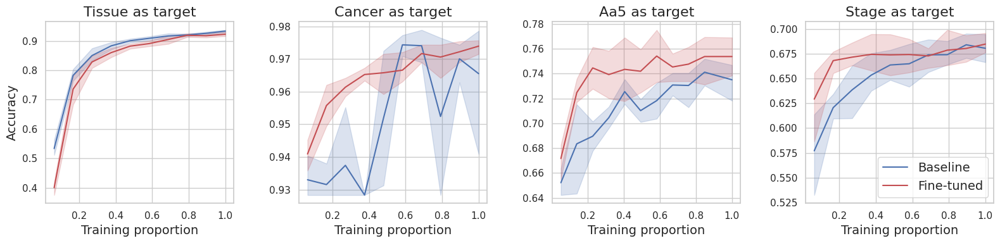

In [35]:
targets = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model']
dfs = [df1, df2, df3, df4]

fig, axes = plt.subplots(1, 4, figsize=(16,4))

for ax, df, target in zip(axes, dfs, targets):
    if target == 'stage_model':
        sns.lineplot(data=df, x="train_samples", y="max_test_accuracy", ax=ax, label='Baseline')
        sns.lineplot(data=df, x="train_samples", y="max_test_accuracy_finetuned", ax=ax, label='Fine-tuned', color='r')
        ax.legend(loc='lower right', fontsize=14)
    else: 
        sns.lineplot(data=df, x="train_samples", y="max_test_accuracy", ax=ax)
        sns.lineplot(data=df, x="train_samples", y="max_test_accuracy_finetuned", ax=ax, color='r')
    ax.set_xlabel('Training proportion', size=14)
    if target == 'tissue_model': ax.set_ylabel('Accuracy', size=14)
    else: ax.set_ylabel(' ')
    ax.set_title(f'{target.split("_")[0].capitalize()} as target', size=16)

plt.tight_layout()
plt.savefig('multitask_grid_plot.png')
plt.show()

### Compare with single task

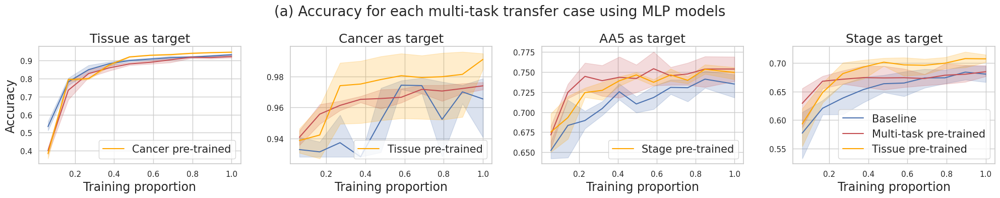

In [19]:
targets = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model']
dfs = [df1, df2, df3, df4]

fig, axes = plt.subplots(1, 4, figsize=(20,4))

for ax, df, target in zip(axes, dfs, targets):
    if target == 'stage_model':
        sns.lineplot(data=df, x="train_samples", y="max_test_accuracy", ax=ax, label='Baseline')
        sns.lineplot(data=df, x="train_samples", y="max_test_accuracy_finetuned", ax=ax, label='Multi-task pre-trained', color='r')
        sns.lineplot(data=df_prop_dict_intertask_mlp[('tissue_model','stage_model')], x="train_samples", y="max_test_accuracy_finetuned", ax=ax, label='Tissue pre-trained', color='orange')
        #ax.legend(loc='lower right', fontsize=14, bbox_to_anchor=(2.2, 0.0))
        ax.legend(loc='lower right', fontsize=15)
    else: 
        sns.lineplot(data=df, x="train_samples", y="max_test_accuracy", ax=ax)
        sns.lineplot(data=df, x="train_samples", y="max_test_accuracy_finetuned", ax=ax, color='r')
    if target == 'tissue_model':
        sns.lineplot(data=df_prop_dict_intertask_mlp[('cancer_model','tissue_model')], x="train_samples", y="max_test_accuracy_finetuned", ax=ax, color='orange', label='Cancer pre-trained')
        ax.legend(loc='lower right', fontsize=15)
    if target == 'cancer_model':
        sns.lineplot(data=df_prop_dict_intertask_mlp[('tissue_model','cancer_model')], x="train_samples", y="max_test_accuracy_finetuned", ax=ax, color='orange', label='Tissue pre-trained')
        ax.legend(loc='lower right', fontsize=15)
    if target == 'aa5_model':
        sns.lineplot(data=df_prop_dict_intertask_mlp[('stage_model','AA5_model')], x="train_samples", y="max_test_accuracy_finetuned", ax=ax, color='orange', label='Stage pre-trained')
        ax.legend(loc='lower right', fontsize=15)
    ax.set_xlabel('Training proportion', size=17)
    if target == 'tissue_model': ax.set_ylabel('Accuracy', size=17)
    else: ax.set_ylabel(' ')

    if target == 'aa5_model': ax.set_title(f'{target.split("_")[0].upper()} as target', size=18)
    else: ax.set_title(f'{target.split("_")[0].capitalize()} as target', size=18)

fig.suptitle('(a) Accuracy for each multi-task transfer case using MLP models', fontsize=20)
plt.tight_layout()
plt.savefig('multitask_grid_plot_comp_mlp.png', bbox_inches="tight")
plt.show()

## GNN

In [20]:
#tasks = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model', 'radiation_model', 'pharma_model']
tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model']
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df = pl.DataFrame()
df_dict = {}
df_prop_dict = {}

for model in permutations(tasks, 3):
    group_task_str = '_'.join(model)
    #print(group_task_str)
    for target in tasks:
        if os.path.isdir(f'../../logs/{group_task_str}_to_{target}_'):
            print('combination exists')
            print(f'{group_task_str} to {target}-----')
            df_baseline = pl.DataFrame()
            df_finetuned = pl.DataFrame()
            for version in range(4):
                #print(version)
                baseline_str = 'intertask/gnn/train_GNN_' + target + '_linspace_training'
                group_task_finetuned_str = 'GNN_' + group_task_str + '_to_' + target + '_'
                df_temp_baseline = get_df(baseline_str, version=version)
                df_temp_finetuned = get_df(group_task_finetuned_str, version=version)
                df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
                df_baseline = df_baseline.sort('train_samples')
                df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
                #print(df_finetuned)
                df_finetuned = df_finetuned.sort('train_samples')
            
            #print(df_baseline['train_samples'])
            #print(list(df_finetuned['train_samples']))
            #print(df_baseline)
            print('-----')
            df = df_baseline.with_columns(df_finetuned['max_test_accuracy'].alias('max_test_accuracy_finetuned'))
            df_prop_dict[((model[0], model[1], model[2]), target)] = df

combination exists
cancer_model_stage_model_tissue_model to aa5_model-----
-----
combination exists
aa5_model_cancer_model_tissue_model to stage_model-----
-----
combination exists
aa5_model_cancer_model_stage_model to tissue_model-----
-----
combination exists
aa5_model_stage_model_tissue_model to cancer_model-----
-----


In [21]:
rows = []
for (source, target), df in df_prop_dict.items():
    for ts, acc, acc_ft in zip(df['train_samples'], df['max_test_accuracy'], df['max_test_accuracy_finetuned']):
        rows.append({
            "source_task": source,
            "target_task": target,
            "train_samples": ts,
            "max_test_accuracy": acc,
            "max_test_accuracy_finetuned": acc_ft
        })

df_long = pd.DataFrame(rows)
df_long_gnn = pd.DataFrame(rows)

In [22]:
df1 = df_long[df_long['target_task'] == 'tissue_model']
df2 = df_long[df_long['target_task'] == 'cancer_model']
df3 = df_long[df_long['target_task'] == 'aa5_model']
df4 = df_long[df_long['target_task'] == 'stage_model']

In [23]:
sns.set(style="whitegrid")

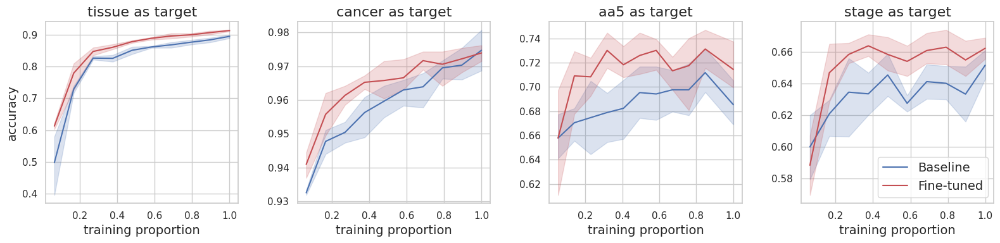

In [59]:
targets = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model']
dfs = [df1, df2, df3, df4]

fig, axes = plt.subplots(1, 4, figsize=(16,4))

for ax, df, target in zip(axes, dfs, targets):
    if target == 'stage_model':
        sns.lineplot(data=df, x="train_samples", y="max_test_accuracy", ax=ax, label='Baseline')
        sns.lineplot(data=df, x="train_samples", y="max_test_accuracy_finetuned", ax=ax, label='Fine-tuned', color='r')
        ax.legend(loc='lower right', fontsize=14)
    else: 
        sns.lineplot(data=df, x="train_samples", y="max_test_accuracy", ax=ax)
        sns.lineplot(data=df, x="train_samples", y="max_test_accuracy_finetuned", ax=ax, color='r')
    ax.set_xlabel('training proportion', size=14)
    if target == 'tissue_model': ax.set_ylabel('accuracy', size=14)
    else: ax.set_ylabel(' ')
    ax.set_title(f'{target.split("_")[0]} as target', size=16)

plt.tight_layout()
plt.savefig('gnn_multitask_grid_plot.png')
plt.show()

### Compare with single task

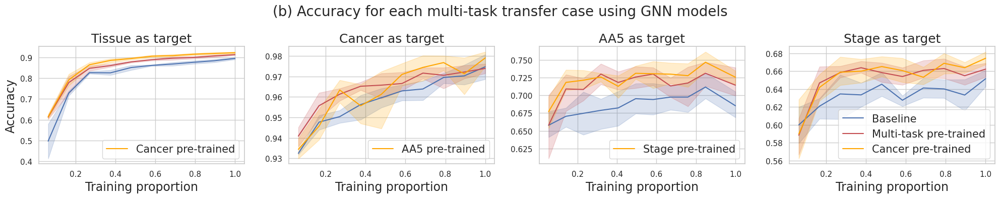

In [25]:
targets = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model']
dfs = [df1, df2, df3, df4]

fig, axes = plt.subplots(1, 4, figsize=(20,4))

for ax, df, target in zip(axes, dfs, targets):
    if target == 'stage_model':
        sns.lineplot(data=df, x="train_samples", y="max_test_accuracy", ax=ax, label='Baseline')
        sns.lineplot(data=df, x="train_samples", y="max_test_accuracy_finetuned", ax=ax, label='Multi-task pre-trained', color='r')
        sns.lineplot(data=df_prop_dict_intertask[('cancer_model','stage_model')], x="train_samples", y="max_test_accuracy_finetuned", ax=ax, label='Cancer pre-trained', color='orange')
        #ax.legend(loc='lower right', fontsize=14, bbox_to_anchor=(2.2, 0.0))
        ax.legend(loc='lower right', fontsize=15)
    else: 
        sns.lineplot(data=df, x="train_samples", y="max_test_accuracy", ax=ax)
        sns.lineplot(data=df, x="train_samples", y="max_test_accuracy_finetuned", ax=ax, color='r')
    if target == 'tissue_model':
        sns.lineplot(data=df_prop_dict_intertask[('cancer_model','tissue_model')], x="train_samples", y="max_test_accuracy_finetuned", ax=ax, color='orange', label='Cancer pre-trained')
        ax.legend(loc='lower right', fontsize=15)
    if target == 'cancer_model':
        sns.lineplot(data=df_prop_dict_intertask[('aa5_model','cancer_model')], x="train_samples", y="max_test_accuracy_finetuned", ax=ax, color='orange', label='AA5 pre-trained')
        ax.legend(loc='lower right', fontsize=15)
    if target == 'aa5_model':
        sns.lineplot(data=df_prop_dict_intertask[('stage_model','aa5_model')], x="train_samples", y="max_test_accuracy_finetuned", ax=ax, color='orange', label='Stage pre-trained')
        ax.legend(loc='lower right', fontsize=15)
    ax.set_xlabel('Training proportion', size=17)
    if target == 'tissue_model': ax.set_ylabel('Accuracy', size=17)
    else: ax.set_ylabel(' ')

    if target == 'aa5_model': ax.set_title(f'{target.split("_")[0].upper()} as target', size=18)
    else: ax.set_title(f'{target.split("_")[0].capitalize()} as target', size=18)

fig.suptitle('(b) Accuracy for each multi-task transfer case using GNN models', fontsize=20)
plt.tight_layout()
plt.savefig('gnn_multitask_grid_plot_comp_gnn.png', bbox_inches="tight")
plt.show()

## Merge figures

In [52]:
df1_mlp = df_long_mlp[df_long_mlp['target_task'] == 'tissue_model']
df2_mlp = df_long_mlp[df_long_mlp['target_task'] == 'cancer_model']
df3_mlp = df_long_mlp[df_long_mlp['target_task'] == 'aa5_model']
df4_mlp = df_long_mlp[df_long_mlp['target_task'] == 'stage_model']

In [53]:
df1_gnn = df_long_gnn[df_long_gnn['target_task'] == 'tissue_model']
df2_gnn = df_long_gnn[df_long_gnn['target_task'] == 'cancer_model']
df3_gnn = df_long_gnn[df_long_gnn['target_task'] == 'aa5_model']
df4_gnn = df_long_gnn[df_long_gnn['target_task'] == 'stage_model']

In [54]:
sns.set(style="whitegrid")

ok


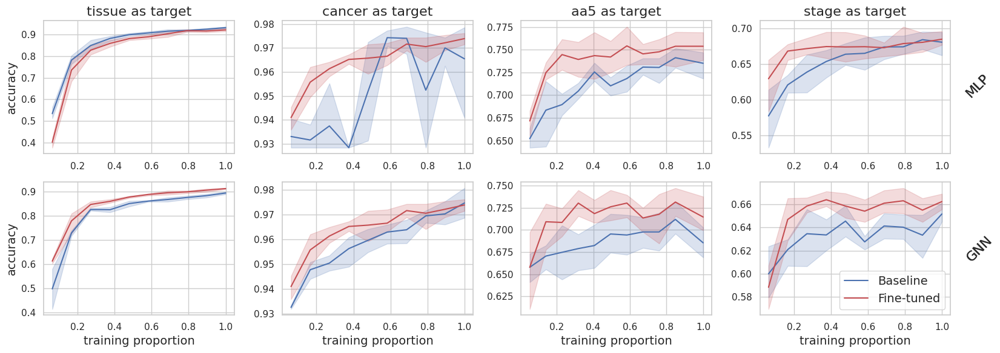

In [94]:
targets = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model']
dfs = [df1_mlp, df2_mlp, df3_mlp, df4_mlp, df1_gnn, df2_gnn, df3_gnn, df4_gnn]
i_dfs = 0

fig, axes = plt.subplots(2, 4, figsize=(16, 6))

for i in range(2):
    for j, target in zip(range(4), targets):
        if i==1 and j==3:
            print('ok')
            sns.lineplot(data=dfs[i_dfs], x="train_samples", y="max_test_accuracy", ax=axes[i,j], label='Baseline')
            sns.lineplot(data=dfs[i_dfs], x="train_samples", y="max_test_accuracy_finetuned", ax=axes[i,j], label='Fine-tuned', color='r')
            axes[i,j].legend(loc='lower right', fontsize=14)
        else:
            sns.lineplot(data=dfs[i_dfs], x="train_samples", y="max_test_accuracy", ax=axes[i,j])
            sns.lineplot(data=dfs[i_dfs], x="train_samples", y="max_test_accuracy_finetuned", ax=axes[i,j], color='r')
        
        # axis labels
        if target == 'tissue_model': axes[i,j].set_ylabel('accuracy', size=14)
        else: axes[i,j].set_ylabel('')
        if i==0: 
            axes[i,j].set_title(f'{target.split("_")[0]} as target', size=16)
            axes[i,j].set_xlabel('')
        if i==1: axes[i,j].set_xlabel('training proportion', size=14)
        
        i_dfs += 1
    
fig.text(1.0, 0.75, "MLP", rotation=45, va='center', fontsize=16)
fig.text(1.0, 0.30, "GNN", rotation=45, va='center', fontsize=16)
        
        
        
plt.tight_layout()
fig.text(1.0, 0.75, "MLP", rotation=45, va='center', fontsize=16)
fig.text(1.0, 0.30, "GNN", rotation=45, va='center', fontsize=16)
plt.savefig('grid_plot_multitask_merged.png', bbox_inches='tight')
plt.show()

ok


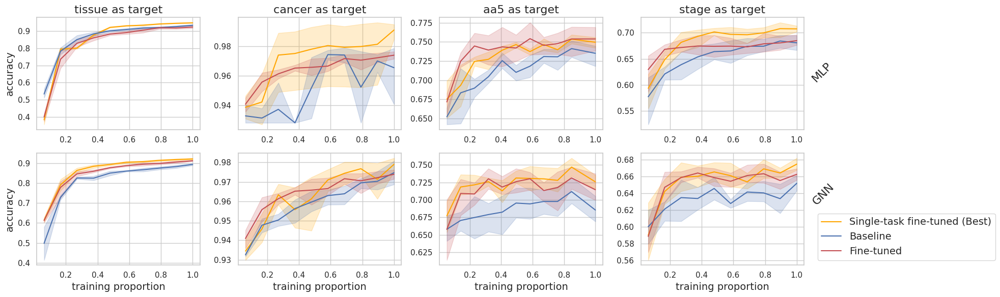

In [88]:
targets = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model']
dfs = [df1_mlp, df2_mlp, df3_mlp, df4_mlp, df1_gnn, df2_gnn, df3_gnn, df4_gnn]
i_dfs = 0

fig, axes = plt.subplots(2, 4, figsize=(20, 6))

for i in range(2):
    for j, target in zip(range(4), targets):
        if i==1:
            if target == 'stage_model':
                sns.lineplot(data=df_prop_dict_intertask[('cancer_model','stage_model')], x="train_samples", y="max_test_accuracy_finetuned", ax=axes[i,j], label='Single-task fine-tuned (Best)', color='orange')
            if target == 'tissue_model':
                sns.lineplot(data=df_prop_dict_intertask[('cancer_model','tissue_model')], x="train_samples", y="max_test_accuracy_finetuned", ax=axes[i,j], color='orange')
            if target == 'cancer_model':
                sns.lineplot(data=df_prop_dict_intertask[('aa5_model','cancer_model')], x="train_samples", y="max_test_accuracy_finetuned", ax=axes[i,j], color='orange')
            if target == 'aa5_model':
                sns.lineplot(data=df_prop_dict_intertask[('stage_model','aa5_model')], x="train_samples", y="max_test_accuracy_finetuned", ax=axes[i,j], color='orange')
                #axes[i,j].legend(loc='lower right', fontsize=14, bbox_to_anchor=(2.2, 0.0))
        if i==0:
            if target == 'stage_model':
                sns.lineplot(data=df_prop_dict_intertask_mlp[('tissue_model','stage_model')], x="train_samples", y="max_test_accuracy_finetuned", ax=axes[i,j], color='orange')
            if target == 'tissue_model':
                sns.lineplot(data=df_prop_dict_intertask_mlp[('cancer_model','tissue_model')], x="train_samples", y="max_test_accuracy_finetuned", ax=axes[i,j], color='orange')
            if target == 'cancer_model':
                sns.lineplot(data=df_prop_dict_intertask_mlp[('tissue_model','cancer_model')], x="train_samples", y="max_test_accuracy_finetuned", ax=axes[i,j], color='orange')
            if target == 'aa5_model':
                sns.lineplot(data=df_prop_dict_intertask_mlp[('stage_model','aa5_model')], x="train_samples", y="max_test_accuracy_finetuned", ax=axes[i,j], color='orange')
        if i==1 and j==3:
            print('ok')
            sns.lineplot(data=dfs[i_dfs], x="train_samples", y="max_test_accuracy", ax=axes[i,j], label='Baseline')
            sns.lineplot(data=dfs[i_dfs], x="train_samples", y="max_test_accuracy_finetuned", ax=axes[i,j], label='Fine-tuned', color='r')
            axes[i,j].legend(loc='lower right', fontsize=14, bbox_to_anchor=(2.2, 0.0))
        else:
            sns.lineplot(data=dfs[i_dfs], x="train_samples", y="max_test_accuracy", ax=axes[i,j])
            sns.lineplot(data=dfs[i_dfs], x="train_samples", y="max_test_accuracy_finetuned", ax=axes[i,j], color='r')
        
        # axis labels
        if target == 'tissue_model': axes[i,j].set_ylabel('accuracy', size=14)
        else: axes[i,j].set_ylabel('')
        if i==0:
            axes[i,j].set_title(f'{target.split("_")[0]} as target', size=16)
            axes[i,j].set_xlabel('')
        if i==1: axes[i,j].set_xlabel('training proportion', size=14)
        
        i_dfs += 1
    
        
        
plt.tight_layout()
fig.text(0.8, 0.75, "MLP", rotation=45, va='center', fontsize=16)
fig.text(0.8, 0.35, "GNN", rotation=45, va='center', fontsize=16)
plt.savefig('grid_plot_multitask_merged_comparison.png', bbox_inches='tight')
plt.show()

### PNG

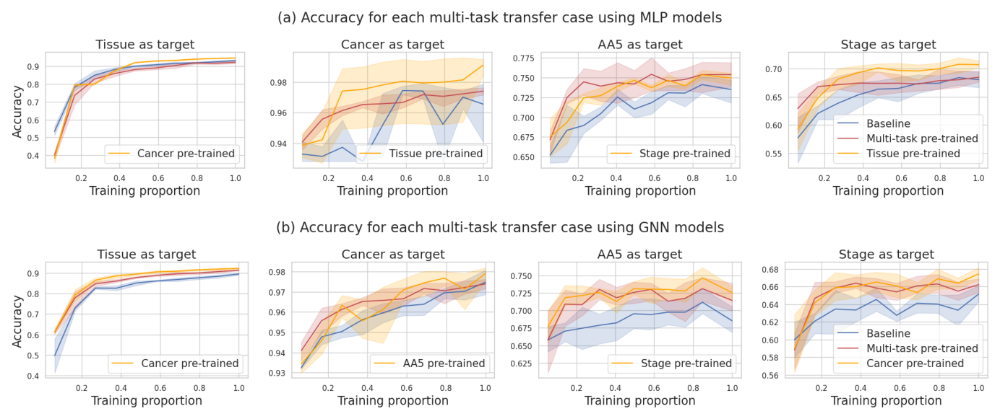

In [27]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6))

img1 = plt.imread("multitask_grid_plot_comp_mlp.png")
img2 = plt.imread("gnn_multitask_grid_plot_comp_gnn.png")

axes[0].imshow(img1)
axes[0].axis("off")

axes[1].imshow(img2)
axes[1].axis("off")

plt.tight_layout()
plt.savefig('multitask_grid_plot_comp_merged.png')
plt.show()

# Transfer metrics

## Inter task

### MLP

In [156]:
sns.set(style="whitegrid")

In [157]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    #print(df.columns)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col(column).max().alias(f"max_{column}"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)

    return all_data

def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", metric])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df

def get_df_metrics(file_str):
    csv_path = Path(f"{BASE_PATH}/{file_str}/version_10/metrics.csv")
    df = pl.read_csv(csv_path)
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    # Dropping the row at index -1
    indexes_to_drop = [10]  # This is the index list to drop
    df = df.filter(~pl.Series(range(len(df))).is_in(indexes_to_drop))
    return df

def add_metrics_col(df, df_metrics):
    df_combined = df.with_columns(df_metrics['GBC'])
    df_combined = df_combined.with_columns(df_metrics['LEEP'])
    df_combined = df_combined.with_columns(df_metrics['LogME'])
    df_combined = df_combined.with_columns(df_metrics['transrate'])
    return df_combined

def compute_macc(source_task, target_task, v=0, metric="max_test_accuracy"):
    baseline_str = 'train_' + target_task + '_linspace_training'
    finetuned_str = source_task + '_to_' + target_task + '_'
    auc_baseline = compute_aupc(baseline_str, version = v, metric=metric)
    auc_finetuned = compute_aupc_multitask(finetuned_str, version = v, metric=metric)
    return auc_finetuned - auc_baseline, auc_finetuned, auc_baseline

In [158]:
#tasks = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model', 'radiation_model', 'pharma_model']
source_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
target_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df = pl.DataFrame()
df_dict = {}
df_prop_dict = {}
df_prop_list = []

for source_task in source_tasks: 
    for target_task in target_tasks:
        if source_task != target_task:
            metrics_str = f'transfer_metrics_{source_task}_to_{target_task}_'
            csv_path = Path(f"{BASE_PATH}/{metrics_str}/version_10/metrics.csv")
            if not csv_path.exists():
                print(f"Fichier manquant : {csv_path}")
            else:
                print(f'{source_task}-{target_task}-----')
                df_baseline = pl.DataFrame()
                df_finetuned = pl.DataFrame()
                for version in range(5):
                    #print(version)
                    baseline_str = 'train_' + target_task + '_linspace_training'
                    finetuned_str = source_task + '_to_' + target_task + '_'
                    df_temp_baseline = get_df(baseline_str, version=version)
                    df_temp_finetuned = get_df(finetuned_str, version=version)
                    df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
                    df_baseline = df_baseline.sort('train_samples')
                    df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
                    #print(df_finetuned)
                    df_finetuned = df_finetuned.sort('train_samples')

                #print(df_baseline['train_samples'])
                #print(list(df_finetuned['train_samples']))
                #print(df_baseline)
                print('-----')
                #print(df_finetuned.group_by('train_samples').mean())
                df = df_baseline.with_columns(df_finetuned['max_test_accuracy'].alias('max_test_accuracy_finetuned'))
                df = df.group_by('train_samples').mean()
                df = df.with_columns((df['max_test_accuracy_finetuned']-df['max_test_accuracy']).alias('real_gain'))
                #print(df)
                # METRICS PART
                metrics_str = f'transfer_metrics_{source_task}_to_{target_task}_'
                df_metrics = get_df_metrics(metrics_str)
                df = add_metrics_col(df, df_metrics)
                #print(df)
                df_prop_dict[(source_task, target_task)] = df
                df_prop_list.append(df)
                

tissue_model-cancer_model-----
-----
tissue_model-stage_model-----
-----
tissue_model-aa5_model-----
-----
tissue_model-radiation_model-----
-----
tissue_model-pharma_model-----
-----
Fichier manquant : ../../logs/transfer_metrics_cancer_model_to_tissue_model_/version_10/metrics.csv
Fichier manquant : ../../logs/transfer_metrics_cancer_model_to_stage_model_/version_10/metrics.csv
Fichier manquant : ../../logs/transfer_metrics_cancer_model_to_aa5_model_/version_10/metrics.csv
Fichier manquant : ../../logs/transfer_metrics_cancer_model_to_radiation_model_/version_10/metrics.csv
Fichier manquant : ../../logs/transfer_metrics_cancer_model_to_pharma_model_/version_10/metrics.csv
Fichier manquant : ../../logs/transfer_metrics_stage_model_to_tissue_model_/version_10/metrics.csv
stage_model-cancer_model-----
-----
stage_model-aa5_model-----
-----
stage_model-radiation_model-----
-----
stage_model-pharma_model-----
-----
Fichier manquant : ../../logs/transfer_metrics_aa5_model_to_tissue_model_/

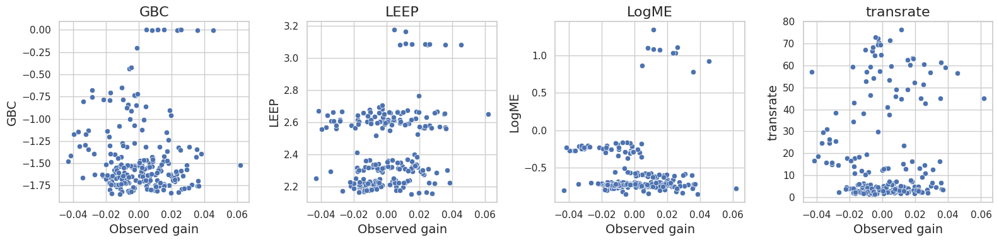

In [95]:
# PLOT
metrics = ['GBC', 'LEEP', 'LogME', 'transrate']
df_merged = pl.concat(df_prop_list)

fig, axes = plt.subplots(1, 4, figsize=(16,4))

for ax, metric in zip(axes, metrics):
    sns.scatterplot(data=df_merged, x='real_gain', y=metric, ax=ax)
    ax.set_xlabel('Observed gain', size=14)
    ax.set_ylabel(f'{metric}', size=14)
    ax.set_title(f'{metric}', size=16)

plt.tight_layout()
plt.savefig('transfer_metrics_corr.png')
plt.show()

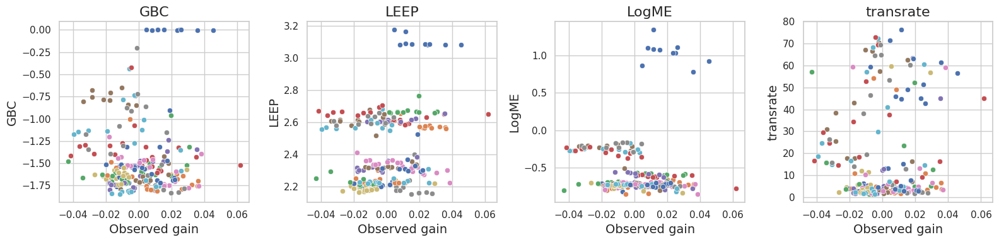

In [96]:
# PLOT
metrics = ['GBC', 'LEEP', 'LogME', 'transrate']
df_merged = pl.concat(df_prop_list)

fig, axes = plt.subplots(1, 4, figsize=(16,4))
i = 0

for ax, metric in zip(axes, metrics):
    for df in df_prop_list:
        sns.scatterplot(data=df, x='real_gain', y=metric, ax=ax, label=f'Task {i}')
    ax.set_xlabel('Observed gain', size=14)
    ax.set_ylabel(f'{metric}', size=14)
    ax.set_title(f'{metric}', size=16)

plt.tight_layout()
plt.savefig('transfer_metrics_corr_tasks.png')
plt.show()

### GNN

In [ ]:
#tasks = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model', 'radiation_model', 'pharma_model']
source_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
target_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df = pl.DataFrame()
df_dict = {}
df_prop_dict = {}
df_prop_dict_intertask = {}

for source_task in source_tasks: 
    for target_task in target_tasks:
        if source_task != target_task:
            print(f'{source_task}-{target_task}-----')
            df_baseline = pl.DataFrame()
            df_finetuned = pl.DataFrame()
            for version in range(5):
                #print(version)
                baseline_str = 'train_GNN_' + target_task + '_linspace_training'
                finetuned_str = 'GNN_' + source_task + '_to_' + target_task + '_'
                df_temp_baseline = get_df(baseline_str, version=version)
                df_temp_finetuned = get_df(finetuned_str, version=version)
                df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
                df_baseline = df_baseline.sort('train_samples')
                df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
                #print(df_finetuned)
                df_finetuned = df_finetuned.sort('train_samples')
            
            #print(df_baseline['train_samples'])
            #print(list(df_finetuned['train_samples']))
            #print(df_baseline)
            print('-----')
            df = df_baseline.with_columns(df_finetuned['max_test_accuracy'].alias('max_test_accuracy_finetuned'))
            df_prop_dict[(source_task, target_task)] = df
            df_prop_dict_intertask[(source_task, target_task)] = df

# Random PPI GNN

In [7]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []


    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    #print(df.columns)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col(column).max().alias(f"max_{column}"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)

    return all_data

def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", metric])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df

def compute_macc(source_task, target_task, v=0, metric="max_test_accuracy"):
    baseline_str = 'train_' + target_task + '_linspace_training'
    finetuned_str = source_task + '_to_' + target_task + '_'
    auc_baseline = compute_aupc(baseline_str, version = v, metric=metric)
    auc_finetuned = compute_aupc_multitask(finetuned_str, version = v, metric=metric)
    return auc_finetuned - auc_baseline, auc_finetuned, auc_baseline

In [8]:
#tasks = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model', 'radiation_model', 'pharma_model']
source_tasks = ['stage_model']
target_tasks = ['aa5_model']
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df = pl.DataFrame()
df_dict = {}
df_prop_dict_random = {}

for source_task in source_tasks: 
    for target_task in target_tasks:
        if source_task != target_task:
            print(f'{source_task}-{target_task}-----')
            df_baseline = pl.DataFrame()
            df_finetuned = pl.DataFrame()
            for version in range(3):
                #print(version)
                baseline_str = 'train_random_GNN_' + target_task + '_linspace_training'
                finetuned_str = 'random_GNN_' + source_task + '_to_' + target_task + '_'
                #baseline_str = 'train_random_distrib_GNN_' + target_task + '_linspace_training'
                #finetuned_str = 'random_distrib_GNN_' + source_task + '_to_' + target_task + '_'
                df_temp_baseline = get_df(baseline_str, version=1)
                df_temp_finetuned = get_df(finetuned_str, version=version)
                df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
                df_baseline = df_baseline.sort('train_samples')
                df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
                print(df_baseline)
                print(df_finetuned)
                df_finetuned = df_finetuned.sort('train_samples')
            
            #print(df_baseline['train_samples'])
            #print(list(df_finetuned['train_samples']))
            #print(df_baseline)
            print('-----')
            df = df_baseline.with_columns(df_finetuned['max_test_accuracy'].alias('max_test_accuracy_finetuned'))
            df_prop_dict_random[(source_task, target_task)] = df

stage_model-aa5_model-----
shape: (10, 2)
┌───────────────┬───────────────────┐
│ train_samples ┆ max_test_accuracy │
│ ---           ┆ ---               │
│ f64           ┆ f64               │
╞═══════════════╪═══════════════════╡
│ 0.04          ┆ 0.576453          │
│ 0.14625       ┆ 0.620795          │
│ 0.2525        ┆ 0.675841          │
│ 0.36          ┆ 0.672783          │
│ 0.46625       ┆ 0.695719          │
│ 0.5725        ┆ 0.718654          │
│ 0.68          ┆ 0.721713          │
│ 0.78625       ┆ 0.689602          │
│ 0.8925        ┆ 0.715596          │
│ 1.0           ┆ 0.704893          │
└───────────────┴───────────────────┘
shape: (10, 2)
┌───────────────┬───────────────────┐
│ train_samples ┆ max_test_accuracy │
│ ---           ┆ ---               │
│ f64           ┆ f64               │
╞═══════════════╪═══════════════════╡
│ 0.0625        ┆ 0.692661          │
│ 0.16625       ┆ 0.689602          │
│ 0.27          ┆ 0.685015          │
│ 0.375         ┆ 0.715596     

In [9]:
df_prop_dict[('stage_model','aa5_model')]

train_samples,max_test_accuracy,max_test_accuracy_finetuned
f64,f64,f64
0.053022,0.655963,0.634557
0.053022,0.654434,0.675841
0.053022,0.636086,0.674312
0.053022,0.685015,0.688073
0.053022,0.654434,0.712538
…,…,…
1.0,0.663609,0.727829
1.0,0.674312,0.735474
1.0,0.715596,0.738532


In [10]:
df_prop_dict_random[('stage_model','aa5_model')]

train_samples,max_test_accuracy,max_test_accuracy_finetuned
f64,f64,f64
0.04,0.576453,0.692661
0.04,0.576453,0.678899
0.04,0.576453,0.672783
0.14625,0.620795,0.689602
0.14625,0.620795,0.729358
…,…,…
0.8925,0.715596,0.639144
0.8925,0.715596,0.714067
1.0,0.704893,0.686544


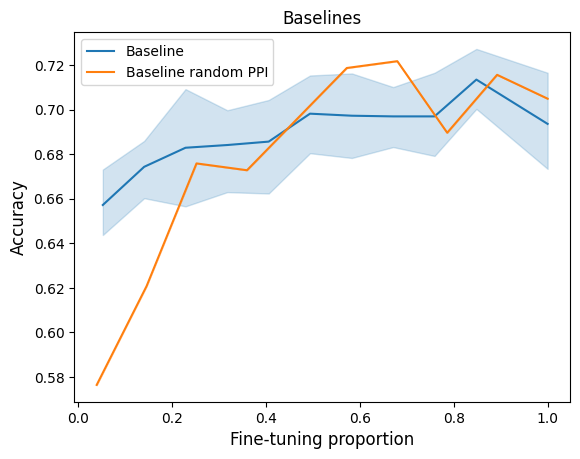

In [11]:
plt.figure()
sns.lineplot(data=df_prop_dict[('stage_model','aa5_model')], y='max_test_accuracy', x='train_samples', label='Baseline')
sns.lineplot(data=df_prop_dict_random[('stage_model','aa5_model')], y='max_test_accuracy', x='train_samples', label='Baseline random PPI')
plt.xlabel('Fine-tuning proportion', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.title('Baselines')
plt.savefig('random_GNN_baselines.png')
plt.show()

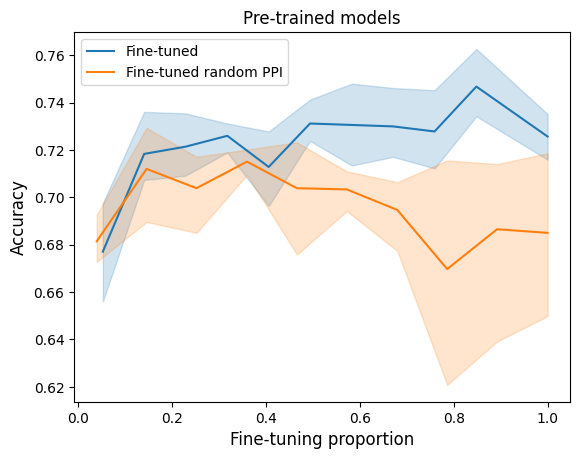

In [12]:
plt.figure()
sns.lineplot(data=df_prop_dict[('stage_model','aa5_model')], y='max_test_accuracy_finetuned', x='train_samples', label='Fine-tuned')
sns.lineplot(data=df_prop_dict_random[('stage_model','aa5_model')], y='max_test_accuracy_finetuned', x='train_samples', label='Fine-tuned random PPI')
plt.xlabel('Fine-tuning proportion', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.title('Pre-trained models')
plt.savefig('random_GNN_finetuned.png')
plt.show()

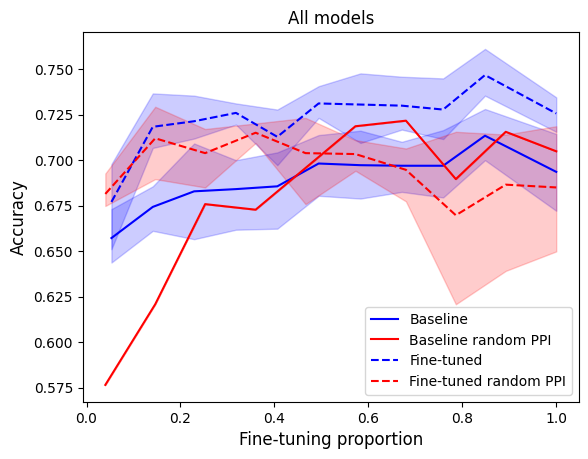

In [15]:
plt.figure()
sns.lineplot(data=df_prop_dict[('stage_model','aa5_model')], y='max_test_accuracy', x='train_samples', label='Baseline', c='b')
sns.lineplot(data=df_prop_dict_random[('stage_model','aa5_model')], y='max_test_accuracy', x='train_samples', label='Baseline random PPI', c='r')
sns.lineplot(data=df_prop_dict[('stage_model','aa5_model')], y='max_test_accuracy_finetuned', x='train_samples', label='Fine-tuned', c='b', linestyle='--')
sns.lineplot(data=df_prop_dict_random[('stage_model','aa5_model')], y='max_test_accuracy_finetuned', x='train_samples', label='Fine-tuned random PPI', c='r', linestyle='--')
plt.xlabel('Fine-tuning proportion', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.title('All models')
#plt.savefig('random_GNN_finetuned.png')
plt.show()

# Convergence Speed

## Pan-cancer

In [122]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col("epoch").max().alias(f"epoch"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)
    return all_data
    return auc_finetuned - auc_baseline, auc_finetuned, auc_baseline

def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='epoch')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", "epoch"])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df

### Grid Plot

In [123]:
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df_prop_dict = {}
tasks = ['cancer_model', 'tissue_model']
cancers = ['BRCA','KIRC','LUSC','HNSC','LUAD','OV','UCEC']
#tasks = ['tissue_model']

for source_task in tasks:
    for cancer in cancers:
        print(f'{source_task}-{cancer}-----')
        df_baseline = pl.DataFrame()
        df_finetuned = pl.DataFrame()
        for version in N_VERSIONS:
            #print(version)
            baseline_str = 'train_' + 'cancer_model' + '_linspace' + cancer + '_training'
            finetuned_str = source_task + '_to_cancer_model_without' + cancer
            df_temp_baseline = get_df(baseline_str, version=version)
            df_temp_finetuned = get_df(finetuned_str, version=version)
            df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
            df_baseline = df_baseline.sort('train_samples')
            df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
            df_finetuned = df_finetuned.sort('train_samples')
        # merge the two df
        print('-----')
        df = df_baseline.with_columns(df_finetuned['epoch'].alias('epoch_finetuned'))
        df_prop_dict[(source_task, cancer)] = df

cancer_model-BRCA-----
-----
cancer_model-KIRC-----
-----
cancer_model-LUSC-----
-----
cancer_model-HNSC-----
-----
cancer_model-LUAD-----
-----
cancer_model-OV-----
-----
cancer_model-UCEC-----
-----
tissue_model-BRCA-----
-----
tissue_model-KIRC-----
-----
tissue_model-LUSC-----
-----
tissue_model-HNSC-----
-----
tissue_model-LUAD-----
-----
tissue_model-OV-----
-----
tissue_model-UCEC-----
-----


In [124]:
rows = []
for (source, target), df in df_prop_dict.items():
    for ts, epoch, epoch_ft in zip(df['train_samples'], df['epoch'], df['epoch_finetuned']):
        rows.append({
            "source_task": source,
            "cancer": target,
            "train_samples": ts,
            "epoch": epoch,
            "epoch_finetuned": epoch_ft
        })

df_long = pd.DataFrame(rows)

<Figure size 640x480 with 0 Axes>

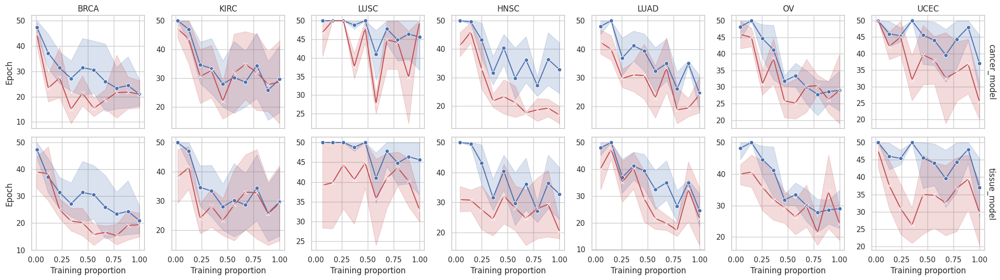

In [125]:
# Set a style
plt.figure()
sns.set(style="whitegrid")

# FacetGrid: rows = source, columns = target
g = sns.FacetGrid(
    df_long,
    col="cancer",
    row="source_task",
    sharey=False,
    sharex=True,
    margin_titles=True,
    despine=False
)

# Map lineplot to each facet
g.map_dataframe(
    sns.lineplot,
    x="train_samples",
    y="epoch",
    marker="o",
)

g.map_dataframe(
    sns.lineplot,
    x="train_samples",
    y="epoch_finetuned",
    marker="x",
    color='r'
)


# Set axis labels
g.set_axis_labels("Training proportion", "Epoch")
g.set_titles(row_template="{row_name}", col_template="{col_name}")


# Adjust spacing
plt.tight_layout()
#g.savefig("convergence_speed_pancancer_grid_plot.png", dpi=300, bbox_inches="tight")
plt.show()

### Grid Plot GNN

In [182]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col("epoch").max().alias(f"epoch"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)
    return all_data

def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='epoch')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", "epoch"])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df

In [184]:
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df_prop_dict = {}
tasks = ['cancer_model', 'tissue_model']
cancers = ['BRCA','KIRC','LUSC','HNSC','LUAD','OV','UCEC']
#tasks = ['tissue_model']

for source_task in tasks:
    for cancer in cancers:
        print(f'{source_task}-{cancer}-----')
        df_baseline = pl.DataFrame()
        df_finetuned = pl.DataFrame()
        for version in N_VERSIONS:
            #print(version)
            baseline_str = 'pancancer/gnn/train_GNN_' + 'cancer_model' + '_linspace' + cancer + '_training'
            finetuned_str = 'pancancer/gnn/GNN_' + source_task + '_to_cancer_model_without' + cancer
            df_temp_baseline = get_df(baseline_str, version=version)
            df_temp_finetuned = get_df(finetuned_str, version=version)
            df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
            df_baseline = df_baseline.sort('train_samples')
            df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
            df_finetuned = df_finetuned.sort('train_samples')
        # merge the two df
        print('-----')
        df = df_baseline.with_columns(df_finetuned['epoch'].alias('epoch_finetuned'))
        df_prop_dict[(source_task, cancer)] = df

cancer_model-BRCA-----
-----
cancer_model-KIRC-----
-----
cancer_model-LUSC-----
-----
cancer_model-HNSC-----
-----
cancer_model-LUAD-----
-----
cancer_model-OV-----
-----
cancer_model-UCEC-----
-----
tissue_model-BRCA-----
-----
tissue_model-KIRC-----
-----
tissue_model-LUSC-----
-----
tissue_model-HNSC-----
-----
tissue_model-LUAD-----
-----
tissue_model-OV-----
-----
tissue_model-UCEC-----
-----


In [185]:
rows = []
for (source, target), df in df_prop_dict.items():
    for ts, epoch, epoch_ft in zip(df['train_samples'], df['epoch'], df['epoch_finetuned']):
        rows.append({
            "source_task": source,
            "cancer": target,
            "train_samples": ts,
            "epoch": epoch,
            "epoch_finetuned": epoch_ft
        })

df_long = pd.DataFrame(rows)

<Figure size 640x480 with 0 Axes>

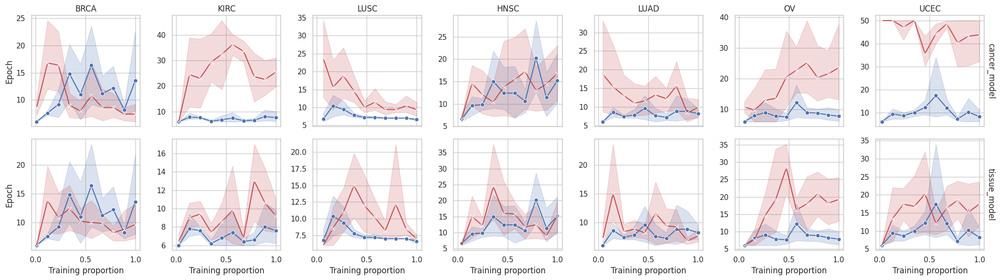

In [187]:
# Set a style
plt.figure()
sns.set(style="whitegrid")

# FacetGrid: rows = source, columns = target
g = sns.FacetGrid(
    df_long,
    col="cancer",
    row="source_task",
    sharey=False,
    sharex=True,
    margin_titles=True,
    despine=False
)

# Map lineplot to each facet
g.map_dataframe(
    sns.lineplot,
    x="train_samples",
    y="epoch",
    marker="o",
)

g.map_dataframe(
    sns.lineplot,
    x="train_samples",
    y="epoch_finetuned",
    marker="x",
    color='r'
)


# Set axis labels
g.set_axis_labels("Training proportion", "Epoch")
g.set_titles(row_template="{row_name}", col_template="{col_name}")


# Adjust spacing
plt.tight_layout()
g.savefig("convergence_speed_pancancer_grid_plot_gnn.png", dpi=300, bbox_inches="tight")
plt.show()

## Intertask

In [ ]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col("epoch").max().alias(f"epoch"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)
    return all_data

def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='epoch')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", "epoch"])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df

### Grid Plot

In [ ]:
#tasks = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model', 'radiation_model', 'pharma_model']
source_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
target_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df = pl.DataFrame()
df_dict = {}
df_prop_dict = {}

for source_task in source_tasks: 
    for target_task in target_tasks:
        if source_task != target_task:
            print(f'{source_task}-{target_task}-----')
            df_baseline = pl.DataFrame()
            df_finetuned = pl.DataFrame()
            for version in range(5):
                #print(version)
                baseline_str = 'train_' + target_task + '_linspace_training'
                finetuned_str = source_task + '_to_' + target_task + '_'
                df_temp_baseline = get_df(baseline_str, version=version)
                df_temp_finetuned = get_df(finetuned_str, version=version)
                df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
                df_baseline = df_baseline.sort('train_samples')
                df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
                #print(df_finetuned)
                df_finetuned = df_finetuned.sort('train_samples')
            
            #print(df_baseline['train_samples'])
            #print(list(df_finetuned['train_samples']))
            #print(df_baseline)
            print('-----')
            df = df_baseline.with_columns(df_finetuned['epoch'].alias('epoch_finetuned'))
            df_prop_dict[(source_task, target_task)] = df

In [ ]:
rows = []
for (source, target), df in df_prop_dict.items():
    for ts, epoch, epoch_ft in zip(df['train_samples'], df['epoch'], df['epoch_finetuned']):
        rows.append({
            "source_task": source,
            "target_task": target,
            "train_samples": ts,
            "epoch": epoch,
            "epoch_finetuned": epoch_ft
        })

df_long = pd.DataFrame(rows)

In [ ]:
# Set a style
plt.figure()
sns.set(style="whitegrid")

# FacetGrid: rows = source, columns = target
g = sns.FacetGrid(
    df_long,
    col="target_task",
    row="source_task",
    sharey=False,
    sharex=True,
    margin_titles=True,
    despine=False,
    row_order=source_tasks,
    col_order=source_tasks
)

# Map lineplot to each facet
g.map_dataframe(
    sns.lineplot,
    x="train_samples",
    y="epoch",
    marker="o",
)

g.map_dataframe(
    sns.lineplot,
    x="train_samples",
    y="epoch_finetuned",
    marker="x",
    color='r'
)


# Set axis labels
g.set_axis_labels("Training proportion", "Epoch")
g.set_titles(row_template="{row_name}", col_template="{col_name}")


# Adjust spacing
plt.tight_layout()
#g.savefig("intertask_grid_plot.png", dpi=300, bbox_inches="tight")
plt.show()

### Grid Plot GNN

In [ ]:
#tasks = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model', 'radiation_model', 'pharma_model']
source_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
target_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df = pl.DataFrame()
df_dict = {}
df_prop_dict = {}

for source_task in source_tasks: 
    for target_task in target_tasks:
        if source_task != target_task:
            print(f'{source_task}-{target_task}-----')
            df_baseline = pl.DataFrame()
            df_finetuned = pl.DataFrame()
            for version in range(5):
                #print(version)
                baseline_str = 'train_GNN_' + target_task + '_linspace_training'
                finetuned_str = 'GNN_' + source_task + '_to_' + target_task + '_'
                df_temp_baseline = get_df(baseline_str, version=version)
                df_temp_finetuned = get_df(finetuned_str, version=version)
                df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
                df_baseline = df_baseline.sort('train_samples')
                df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
                #print(df_finetuned)
                df_finetuned = df_finetuned.sort('train_samples')
            
            #print(df_baseline['train_samples'])
            #print(list(df_finetuned['train_samples']))
            #print(df_baseline)
            print('-----')
            df = df_baseline.with_columns(df_finetuned['epoch'].alias('epoch_finetuned'))
            df_prop_dict[(source_task, target_task)] = df

In [ ]:
rows = []
for (source, target), df in df_prop_dict.items():
    for ts, epoch, epoch_ft in zip(df['train_samples'], df['epoch'], df['epoch_finetuned']):
        rows.append({
            "source_task": source,
            "target_task": target,
            "train_samples": ts,
            "epoch": epoch,
            "epoch_finetuned": epoch_ft
        })

df_long = pd.DataFrame(rows)

In [ ]:
# Set a style
plt.figure()
sns.set(style="whitegrid")

# FacetGrid: rows = source, columns = target
g = sns.FacetGrid(
    df_long,
    col="target_task",
    row="source_task",
    sharey=False,
    sharex=True,
    margin_titles=True,
    despine=False,
    row_order=source_tasks,
    col_order=source_tasks
)

# Map lineplot to each facet
g.map_dataframe(
    sns.lineplot,
    x="train_samples",
    y="epoch",
    marker="o",
)

g.map_dataframe(
    sns.lineplot,
    x="train_samples",
    y="epoch_finetuned",
    marker="x",
    color='r'
)


# Set axis labels
g.set_axis_labels("Training proportion", "Epoch")
g.set_titles(row_template="{row_name}", col_template="{col_name}")


# Adjust spacing
plt.tight_layout()
#g.savefig("intertask_grid_plot.png", dpi=300, bbox_inches="tight")
plt.show()

## Multitask

In [4]:
from itertools import combinations, permutations
import os

### MLP

In [ ]:
#tasks = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model', 'radiation_model', 'pharma_model']
tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model']
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df = pl.DataFrame()
df_dict = {}
df_prop_dict = {}

for model in permutations(tasks, 3):
    group_task_str = '_'.join(model)
    #print(group_task_str)
    for target in tasks:
        if os.path.isdir(f'../../logs/{group_task_str}_to_{target}_'):
            print('combination exists')
            print(f'{group_task_str} to {target}-----')
            df_baseline = pl.DataFrame()
            df_finetuned = pl.DataFrame()
            for version in range(4):
                #print(version)
                baseline_str = 'train_' + target + '_linspace_training'
                group_task_finetuned_str = group_task_str + '_to_' + target + '_'
                df_temp_baseline = get_df(baseline_str, version=version)
                df_temp_finetuned = get_df(group_task_finetuned_str, version=version)
                df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
                df_baseline = df_baseline.sort('train_samples')
                df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
                #print(df_finetuned)
                df_finetuned = df_finetuned.sort('train_samples')
            
            #print(df_baseline['train_samples'])
            #print(list(df_finetuned['train_samples']))
            #print(df_baseline)
            print('-----')
            df = df_baseline.with_columns(df_finetuned['epoch'].alias('epoch_finetuned'))
            df_prop_dict[((model[0], model[1], model[2]), target)] = df

In [ ]:
rows = []
for (source, target), df in df_prop_dict.items():
    for ts, epoch, epoch_ft in zip(df['train_samples'], df['epoch'], df['epoch_finetuned']):
        rows.append({
            "source_task": source,
            "target_task": target,
            "train_samples": ts,
            "epoch": epoch,
            "epoch_finetuned": epoch_ft
        })

df_long = pd.DataFrame(rows)

In [ ]:
df1 = df_long[df_long['target_task'] == 'tissue_model']
df2 = df_long[df_long['target_task'] == 'cancer_model']
df3 = df_long[df_long['target_task'] == 'aa5_model']
df4 = df_long[df_long['target_task'] == 'stage_model']

In [ ]:
sns.set(style="whitegrid")
targets = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model']
dfs = [df1, df2, df3, df4]

fig, axes = plt.subplots(1, 4, figsize=(16,4))

for ax, df, target in zip(axes, dfs, targets):
    if target == 'stage_model':
        sns.lineplot(data=df, x="train_samples", y="epoch", ax=ax, label='Baseline')
        sns.lineplot(data=df, x="train_samples", y="epoch_finetuned", ax=ax, label='Fine-tuned', color='r')
        ax.legend(loc='lower right', fontsize=14)
    else: 
        sns.lineplot(data=df, x="train_samples", y="epoch", ax=ax)
        sns.lineplot(data=df, x="train_samples", y="epoch_finetuned", ax=ax, color='r')
    ax.set_xlabel('training proportion', size=14)
    if target == 'tissue_model': ax.set_ylabel('epoch', size=14)
    else: ax.set_ylabel(' ')
    ax.set_title(f'{target.split("_")[0]} as target', size=16)

plt.tight_layout()
#plt.savefig('multitask_grid_plot.png')
plt.show()

### GNN

In [ ]:
#tasks = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model', 'radiation_model', 'pharma_model']
tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model']
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df = pl.DataFrame()
df_dict = {}
df_prop_dict = {}

for model in permutations(tasks, 3):
    group_task_str = '_'.join(model)
    #print(group_task_str)
    for target in tasks:
        if os.path.isdir(f'../../logs/{group_task_str}_to_{target}_'):
            print('combination exists')
            print(f'{group_task_str} to {target}-----')
            df_baseline = pl.DataFrame()
            df_finetuned = pl.DataFrame()
            for version in range(4):
                #print(version)
                baseline_str = 'train_GNN_' + target + '_linspace_training'
                group_task_finetuned_str = 'GNN_' + group_task_str + '_to_' + target + '_'
                df_temp_baseline = get_df(baseline_str, version=version)
                df_temp_finetuned = get_df(group_task_finetuned_str, version=version)
                df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
                df_baseline = df_baseline.sort('train_samples')
                df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
                #print(df_finetuned)
                df_finetuned = df_finetuned.sort('train_samples')
            
            #print(df_baseline['train_samples'])
            #print(list(df_finetuned['train_samples']))
            #print(df_baseline)
            print('-----')
            df = df_baseline.with_columns(df_finetuned['epoch'].alias('epoch_finetuned'))
            df_prop_dict[((model[0], model[1], model[2]), target)] = df

In [ ]:
rows = []
for (source, target), df in df_prop_dict.items():
    for ts, epoch, epoch_ft in zip(df['train_samples'], df['epoch'], df['epoch_finetuned']):
        rows.append({
            "source_task": source,
            "target_task": target,
            "train_samples": ts,
            "epoch": epoch,
            "epoch_finetuned": epoch_ft
        })

df_long = pd.DataFrame(rows)

In [ ]:
df1 = df_long[df_long['target_task'] == 'tissue_model']
df2 = df_long[df_long['target_task'] == 'cancer_model']
df3 = df_long[df_long['target_task'] == 'aa5_model']
df4 = df_long[df_long['target_task'] == 'stage_model']

In [ ]:
sns.set(style="whitegrid")
targets = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model']
dfs = [df1, df2, df3, df4]

fig, axes = plt.subplots(1, 4, figsize=(16,4))

for ax, df, target in zip(axes, dfs, targets):
    if target == 'stage_model':
        sns.lineplot(data=df, x="train_samples", y="epoch", ax=ax, label='Baseline')
        sns.lineplot(data=df, x="train_samples", y="epoch_finetuned", ax=ax, label='Fine-tuned', color='r')
        ax.legend(loc='lower right', fontsize=14)
    else: 
        sns.lineplot(data=df, x="train_samples", y="epoch", ax=ax)
        sns.lineplot(data=df, x="train_samples", y="epoch_finetuned", ax=ax, color='r')
    ax.set_xlabel('training proportion', size=14)
    if target == 'tissue_model': ax.set_ylabel('epoch', size=14)
    else: ax.set_ylabel(' ')
    ax.set_title(f'{target.split("_")[0]} as target', size=16)

plt.tight_layout()
#plt.savefig('multitask_grid_plot.png')
plt.show()

# Convergence Speed Across Proportion

## Pan-cancer

### MLP

In [118]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col(column).max().alias(f"max_{column}"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)

    return all_data
    
def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", metric])
    #print(df)
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df

In [119]:
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df_prop_dict = {}
tasks = ['cancer_model', 'tissue_model']
cancers = ['BRCA','KIRC','LUSC','HNSC','LUAD','OV','UCEC']
#tasks = ['tissue_model']

for source_task in tasks:
    for cancer in cancers:
        print(f'{source_task}-{cancer}-----')
        df_baseline = pl.DataFrame()
        df_finetuned = pl.DataFrame()
        for version in N_VERSIONS:
            #print(version)
            baseline_str = 'train_' + 'cancer_model' + '_linspace' + cancer + '_training'
            finetuned_str = source_task + '_to_cancer_model_without' + cancer
            df_temp_baseline = get_df(baseline_str, version=version)
            df_temp_finetuned = get_df(finetuned_str, version=version)
            df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
            df_baseline = df_baseline.sort('train_samples')
            df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
            df_finetuned = df_finetuned.sort('train_samples')
            print(df_finetuned.shape)
        # merge the two df
        print('-----')
        df = df_baseline.with_columns(df_finetuned['max_test_accuracy'].alias('max_test_accuracy_finetuned'))
        result_prop = (
            df
            .group_by("train_samples")
            .agg(
                pl.col("max_test_accuracy").alias("accuracy_list")
            )
            .sort("train_samples")  # optional
        )
        result_prop_finetuned = (
            df
            .group_by("train_samples")
            .agg(
                pl.col("max_test_accuracy_finetuned").alias("accuracy_list_finetuned")
            )
            .sort("train_samples")  # optional
        )
        result_prop = result_prop.with_columns(result_prop_finetuned["accuracy_list_finetuned"])
        df_prop_dict[(source_task, cancer)] = result_prop

cancer_model-BRCA-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-KIRC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-LUSC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-HNSC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-LUAD-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-OV-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-UCEC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-BRCA-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-KIRC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-LUSC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-HNSC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-LUAD-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-OV-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-UCEC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----


In [120]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col("epoch").max().alias(f"epoch"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)
    return all_data

def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='epoch')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", "epoch"])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df

df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df_prop_dict_epoch = {}
tasks = ['cancer_model', 'tissue_model']
cancers = ['BRCA','KIRC','LUSC','HNSC','LUAD','OV','UCEC']
#tasks = ['tissue_model']

for source_task in tasks:
    for cancer in cancers:
        print(f'{source_task}-{cancer}-----')
        df_baseline = pl.DataFrame()
        df_finetuned = pl.DataFrame()
        for version in N_VERSIONS:
            #print(version)
            baseline_str = 'train_' + 'cancer_model' + '_linspace' + cancer + '_training'
            finetuned_str = source_task + '_to_cancer_model_without' + cancer
            df_temp_baseline = get_df(baseline_str, version=version)
            df_temp_finetuned = get_df(finetuned_str, version=version)
            df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
            df_baseline = df_baseline.sort('train_samples')
            df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
            df_finetuned = df_finetuned.sort('train_samples')
            print(df_finetuned.shape)
        # merge the two df
        print('-----')
        df = df_baseline.with_columns(df_finetuned['epoch'].alias('epoch_finetuned'))
        df_prop_dict_epoch[(source_task, cancer)] = df

cancer_model-BRCA-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-KIRC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-LUSC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-HNSC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-LUAD-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-OV-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-UCEC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-BRCA-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-KIRC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-LUSC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-HNSC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-LUAD-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-OV-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-UCEC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----


In [121]:
df_prop_dict

{('cancer_model',
  'BRCA'): shape: (10, 3)
 ┌───────────────┬─────────────────────────────────┬─────────────────────────────────┐
 │ train_samples ┆ accuracy_list                   ┆ accuracy_list_finetuned         │
 │ ---           ┆ ---                             ┆ ---                             │
 │ f64           ┆ list[f64]                       ┆ list[f64]                       │
 ╞═══════════════╪═════════════════════════════════╪═════════════════════════════════╡
 │ 0.010309      ┆ [0.90535, 0.90535, … 0.925926]  ┆ [0.90535, 0.934156, … 0.90535]  │
 │ 0.119845      ┆ [0.979424, 0.90535, … 0.958848… ┆ [0.90535, 0.909465, … 0.90535]  │
 │ 0.229381      ┆ [0.975309, 0.987654, … 0.97942… ┆ [0.90535, 0.90535, … 0.90535]   │
 │ 0.340206      ┆ [0.979424, 0.995885, … 0.98353… ┆ [0.90535, 0.90535, … 0.90535]   │
 │ 0.449742      ┆ [0.971193, 0.99177, … 0.983539… ┆ [0.90535, 0.90535, … 0.90535]   │
 │ 0.559278      ┆ [0.987654, 0.995885, … 0.98765… ┆ [0.90535, 0.90535, … 0.90535]   │

In [122]:
df_mauc = pd.DataFrame(columns=['source', 'target', 'mauc_mean', 'mauc_std', 'mauc_mean_finetuned', 'mauc_std_finetuned', 'p-value'])
df_mauc_save = pd.DataFrame(columns=['source', 'target', 'mauc', 'mauc_finetuned', 'p-value'])
source_tasks = ['cancer_model', 'tissue_model']
cancers = ['BRCA','KIRC','LUSC','HNSC','LUAD','OV','UCEC']
source_list, target_list, mean_list, std_list = [], [], [], []
mean_finetuned_list, std_finetuned_list = [], []
p_value_list = []
mean_epoch_list = []
mean_epoch_finetuned_list = []

mean_list_prop, mean_list_prop_finetuned = [], []
std_list_prop, std_list_prop_finetuned = [], []
p_value_prop = []
for source_task in source_tasks:
    for target_task in cancers:
        if source_task != target_task:
            source_list.append(source_task)
            target_list.append(target_task)
            perf_matrix = np.array([row for row in df_prop_dict[(source_task,target_task)]['accuracy_list']])
            prop_matrix = np.array([row for row in df_prop_dict[(source_task,target_task)]['train_samples']])
            mauc = [auc(prop_matrix, perf_matrix[:,i]) for i in range(perf_matrix.shape[1])]
            mean_list.append(np.mean(mauc))
            std_list.append(np.std(mauc))
            perf_matrix_finetuned = np.array([row for row in df_prop_dict[(source_task,target_task)]['accuracy_list_finetuned']])
            prop_matrix_finetuned = np.array([row for row in df_prop_dict[(source_task,target_task)]['train_samples']])
            mauc_finetuned = [auc(prop_matrix_finetuned, perf_matrix_finetuned[:,i]) for i in range(perf_matrix_finetuned.shape[1])]
            mean_finetuned_list.append(np.mean(mauc_finetuned))
            std_finetuned_list.append(np.std(mauc_finetuned))
            t_stat, p_value = stats.ttest_rel(mauc, mauc_finetuned)
            p_value_list.append(p_value)

            epoch_matrix = np.array([row for row in df_prop_dict_epoch[(source_task,target_task)].group_by('train_samples').mean()['epoch']])
            #print(df_prop_dict_epoch[(source_task,target_task)].group_by('train_samples').mean())
            epoch_finetuned_matrix = np.array([row for row in df_prop_dict_epoch[(source_task,target_task)].group_by('train_samples').mean()['epoch_finetuned']])
            mean_epoch_list.append(epoch_matrix)
            mean_epoch_finetuned_list.append(epoch_finetuned_matrix)
            
            mean_list_prop.append(np.mean(perf_matrix, axis=1))
            mean_list_prop_finetuned.append(np.mean(perf_matrix_finetuned, axis=1))
            std_list_prop.append(np.std(perf_matrix, axis=1))
            std_list_prop_finetuned.append(np.std(perf_matrix_finetuned, axis=1))
            p_value_prop.append([stats.ttest_rel(perf_matrix[i], perf_matrix_finetuned[i])[1] for i in range(perf_matrix.shape[0])])

df_mauc['source'] = source_list
df_mauc['target'] = target_list
df_mauc['mauc_mean'] = mean_list
df_mauc['mauc_std'] = std_list
df_mauc['mauc_mean_finetuned'] = mean_finetuned_list
df_mauc['mauc_std_finetuned'] = std_finetuned_list
df_mauc['p-value'] = p_value_list
df_mauc['mean_by_prop'] = mean_list_prop
df_mauc['std_by_prop'] = std_list_prop
df_mauc['mean_by_prop_finetuned'] = mean_list_prop_finetuned
df_mauc['std_by_prop_finetuned'] = std_list_prop_finetuned
df_mauc['p-value_by_prop'] = p_value_prop
df_mauc['mean_epoch'] = mean_epoch_list
df_mauc['mean_epoch_finetuned'] = mean_epoch_finetuned_list

df_mauc_save['source'] = source_list
df_mauc_save['target'] = target_list
df_mauc_save['mauc'] = [f'{np.round(mean, 4)} ± {np.round(std, 4)}' for mean, std in zip(mean_list, std_list)]
df_mauc_save['mauc_finetuned'] = [f'{np.round(mean, 4)} ± {np.round(std, 4)}' for mean, std in zip(mean_finetuned_list, std_finetuned_list)]
df_mauc_save['p-value'] = p_value_list

#### Boxplot

In [123]:
diff_means = []
epoch_means, epoch_means_finetuned = [], []
labels = []

for i in range(len(df_mauc.index)):
    row = df_mauc.iloc[i]
    source, target = row['source'], row['target']
    p_value = row['p-value']
    mauc_baseline, mauc_finetuned = row['mauc_mean'], row['mauc_mean_finetuned']
    if p_value < 0.95:
    #if mauc_baseline < mauc_finetuned and p_value < 0.06:
        print(f'{source} to {target} beneficial: {mauc_baseline} vs {mauc_finetuned}')
        epoch_baseline_prop, epoch_finetuned_prop = row['mean_epoch'], row['mean_epoch_finetuned']
        diff_prop = epoch_baseline_prop - epoch_finetuned_prop 
        print(diff_prop)
        print(diff_prop.mean())
        diff_means.append(diff_prop*2)
        labels.append(f'{source.split("_")[0].capitalize()} to {target.split("_")[0]}')
#diff_means = np.concatenate(diff_means)
#print(np.mean(diff_means))

cancer_model to BRCA beneficial: 0.9717078189300412 vs 0.915005197064189
[ 2.8 13.8  4.  12.2 10.  15.2  7.4  1.8  2.6  0. ]
6.979999999999999
cancer_model to KIRC beneficial: 0.9690286220871327 vs 0.9588003419452887
[ 2.8  3.4  4.   0.8  6.  -1.6 -6.2  2.4 -2.   1. ]
1.0599999999999994
cancer_model to LUSC beneficial: 0.9291770057899089 vs 0.8782051282051281
[ 3.2  0.   0.  11.2  2.  13.2  3.   0.6 11.6 -4. ]
4.079999999999999
cancer_model to HNSC beneficial: 0.9314521144278606 vs 0.8583255597014926
[ 8.8  3.6 10.2  9.8 17.2  8.6 18.6  8.6 17.2 16. ]
11.860000000000001
cancer_model to LUAD beneficial: 0.9340289256198346 vs 0.8795351239669422
[ 5.6 10.   7.2 10.2  8.6  9.4  1.6  7.4 15.6  0.6]
7.619999999999999
cancer_model to OV beneficial: 0.9244114126097365 vs 0.925548683160415
[ 2.4  5.  13.6  2.6  6.   8.2 -0.2 -2.6  2.4  0. ]
3.740000000000002
cancer_model to UCEC beneficial: 0.9536115569823437 vs 0.9538799157303371
[ 0.   3.8  0.4 18.   6.   6.   7.  10.  11.2 11.6]
7.4
tissue_m

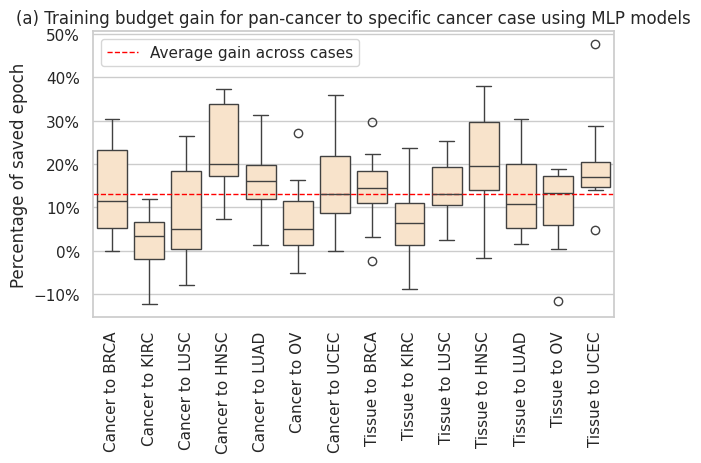

In [124]:
plt.figure()
sns.boxplot(data=diff_means, color="bisque")
all_values = [v for sublist in diff_means for v in sublist]
mean_val = np.mean(all_values)
plt.axhline(mean_val, linestyle='--', linewidth=1, color='red', label='Average gain across cases')
plt.legend()

plt.xticks(ticks=range(len(labels)), labels=labels, rotation=90)
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(100))
plt.ylabel("Percentage of saved epoch")


plt.title('(a) Training budget gain for pan-cancer to specific cancer case using MLP models')
plt.tight_layout()
plt.savefig('pancancer_epoch_gain_mlp.png')
plt.show()

### GNN

In [134]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col(column).max().alias(f"max_{column}"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)

    return all_data
    
def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", metric])
    #print(df)
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df

df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df_prop_dict = {}
tasks = ['cancer_model', 'tissue_model']
cancers = ['BRCA','KIRC','LUSC','HNSC','LUAD','OV','UCEC']
#tasks = ['tissue_model']

for source_task in tasks:
    for cancer in cancers:
        print(f'{source_task}-{cancer}-----')
        df_baseline = pl.DataFrame()
        df_finetuned = pl.DataFrame()
        for version in N_VERSIONS:
            #print(version)
            baseline_str = 'pancancer/gnn/train_GNN_' + 'cancer_model' + '_linspace' + cancer + '_training'
            finetuned_str = 'pancancer/gnn/GNN_' + source_task + '_to_cancer_model_without' + cancer
            df_temp_baseline = get_df(baseline_str, version=version)
            df_temp_finetuned = get_df(finetuned_str, version=version)
            df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
            df_baseline = df_baseline.sort('train_samples')
            df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
            df_finetuned = df_finetuned.sort('train_samples')
            print(df_finetuned.shape)
        # merge the two df
        print('-----')
        df = df_baseline.with_columns(df_finetuned['max_test_accuracy'].alias('max_test_accuracy_finetuned'))
        result_prop = (
            df
            .group_by("train_samples")
            .agg(
                pl.col("max_test_accuracy").alias("accuracy_list")
            )
            .sort("train_samples")  # optional
        )
        result_prop_finetuned = (
            df
            .group_by("train_samples")
            .agg(
                pl.col("max_test_accuracy_finetuned").alias("accuracy_list_finetuned")
            )
            .sort("train_samples")  # optional
        )
        result_prop = result_prop.with_columns(result_prop_finetuned["accuracy_list_finetuned"])
        df_prop_dict[(source_task, cancer)] = result_prop

cancer_model-BRCA-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-KIRC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-LUSC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-HNSC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-LUAD-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-OV-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-UCEC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-BRCA-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-KIRC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-LUSC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-HNSC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-LUAD-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-OV-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-UCEC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----


In [135]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col("epoch").max().alias(f"epoch"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)
    return all_data

def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='epoch')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", "epoch"])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df

df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df_prop_dict_epoch = {}
tasks = ['cancer_model', 'tissue_model']
cancers = ['BRCA','KIRC','LUSC','HNSC','LUAD','OV','UCEC']
#tasks = ['tissue_model']

for source_task in tasks:
    for cancer in cancers:
        print(f'{source_task}-{cancer}-----')
        df_baseline = pl.DataFrame()
        df_finetuned = pl.DataFrame()
        for version in N_VERSIONS:
            #print(version)
            baseline_str = 'pancancer/gnn/train_GNN_' + 'cancer_model' + '_linspace' + cancer + '_training'
            finetuned_str = 'pancancer/gnn/GNN_' + source_task + '_to_cancer_model_without' + cancer
            df_temp_baseline = get_df(baseline_str, version=version)
            df_temp_finetuned = get_df(finetuned_str, version=version)
            df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
            df_baseline = df_baseline.sort('train_samples')
            df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
            df_finetuned = df_finetuned.sort('train_samples')
            print(df_finetuned.shape)
        # merge the two df
        print('-----')
        df = df_baseline.with_columns(df_finetuned['epoch'].alias('epoch_finetuned'))
        df_prop_dict_epoch[(source_task, cancer)] = df

cancer_model-BRCA-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-KIRC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-LUSC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-HNSC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-LUAD-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-OV-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
cancer_model-UCEC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-BRCA-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-KIRC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-LUSC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-HNSC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-LUAD-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-OV-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----
tissue_model-UCEC-----
(10, 2)
(20, 2)
(30, 2)
(40, 2)
(50, 2)
-----


In [136]:
df_mauc = pd.DataFrame(columns=['source', 'target', 'mauc_mean', 'mauc_std', 'mauc_mean_finetuned', 'mauc_std_finetuned', 'p-value'])
df_mauc_save = pd.DataFrame(columns=['source', 'target', 'mauc', 'mauc_finetuned', 'p-value'])
source_tasks = ['cancer_model', 'tissue_model']
cancers = ['BRCA','KIRC','LUSC','HNSC','LUAD','OV','UCEC']
source_list, target_list, mean_list, std_list = [], [], [], []
mean_finetuned_list, std_finetuned_list = [], []
p_value_list = []
mean_epoch_list = []
mean_epoch_finetuned_list = []

mean_list_prop, mean_list_prop_finetuned = [], []
std_list_prop, std_list_prop_finetuned = [], []
p_value_prop = []
for source_task in source_tasks:
    for target_task in cancers:
        if source_task != target_task:
            source_list.append(source_task)
            target_list.append(target_task)
            perf_matrix = np.array([row for row in df_prop_dict[(source_task,target_task)]['accuracy_list']])
            prop_matrix = np.array([row for row in df_prop_dict[(source_task,target_task)]['train_samples']])
            mauc = [auc(prop_matrix, perf_matrix[:,i]) for i in range(perf_matrix.shape[1])]
            mean_list.append(np.mean(mauc))
            std_list.append(np.std(mauc))
            perf_matrix_finetuned = np.array([row for row in df_prop_dict[(source_task,target_task)]['accuracy_list_finetuned']])
            prop_matrix_finetuned = np.array([row for row in df_prop_dict[(source_task,target_task)]['train_samples']])
            mauc_finetuned = [auc(prop_matrix_finetuned, perf_matrix_finetuned[:,i]) for i in range(perf_matrix_finetuned.shape[1])]
            mean_finetuned_list.append(np.mean(mauc_finetuned))
            std_finetuned_list.append(np.std(mauc_finetuned))
            t_stat, p_value = stats.ttest_rel(mauc, mauc_finetuned)
            p_value_list.append(p_value)

            epoch_matrix = np.array([row for row in df_prop_dict_epoch[(source_task,target_task)].group_by('train_samples').mean()['epoch']])
            #print(df_prop_dict_epoch[(source_task,target_task)].group_by('train_samples').mean())
            epoch_finetuned_matrix = np.array([row for row in df_prop_dict_epoch[(source_task,target_task)].group_by('train_samples').mean()['epoch_finetuned']])
            mean_epoch_list.append(epoch_matrix)
            mean_epoch_finetuned_list.append(epoch_finetuned_matrix)
            
            mean_list_prop.append(np.mean(perf_matrix, axis=1))
            mean_list_prop_finetuned.append(np.mean(perf_matrix_finetuned, axis=1))
            std_list_prop.append(np.std(perf_matrix, axis=1))
            std_list_prop_finetuned.append(np.std(perf_matrix_finetuned, axis=1))
            p_value_prop.append([stats.ttest_rel(perf_matrix[i], perf_matrix_finetuned[i])[1] for i in range(perf_matrix.shape[0])])

df_mauc['source'] = source_list
df_mauc['target'] = target_list
df_mauc['mauc_mean'] = mean_list
df_mauc['mauc_std'] = std_list
df_mauc['mauc_mean_finetuned'] = mean_finetuned_list
df_mauc['mauc_std_finetuned'] = std_finetuned_list
df_mauc['p-value'] = p_value_list
df_mauc['mean_by_prop'] = mean_list_prop
df_mauc['std_by_prop'] = std_list_prop
df_mauc['mean_by_prop_finetuned'] = mean_list_prop_finetuned
df_mauc['std_by_prop_finetuned'] = std_list_prop_finetuned
df_mauc['p-value_by_prop'] = p_value_prop
df_mauc['mean_epoch'] = mean_epoch_list
df_mauc['mean_epoch_finetuned'] = mean_epoch_finetuned_list

df_mauc_save['source'] = source_list
df_mauc_save['target'] = target_list
df_mauc_save['mauc'] = [f'{np.round(mean, 4)} ± {np.round(std, 4)}' for mean, std in zip(mean_list, std_list)]
df_mauc_save['mauc_finetuned'] = [f'{np.round(mean, 4)} ± {np.round(std, 4)}' for mean, std in zip(mean_finetuned_list, std_finetuned_list)]
df_mauc_save['p-value'] = p_value_list

#### Boxplot

In [138]:
diff_means_gnn = []
epoch_means, epoch_means_finetuned = [], []
labels = []

for i in range(len(df_mauc.index)):
    row = df_mauc.iloc[i]
    source, target = row['source'], row['target']
    p_value = row['p-value']
    mauc_baseline, mauc_finetuned = row['mauc_mean'], row['mauc_mean_finetuned']
    if p_value < 1.00:
    #if mauc_baseline < mauc_finetuned and p_value < 0.06:
        print(f'{source} to {target} beneficial: {mauc_baseline} vs {mauc_finetuned}')
        epoch_baseline_prop, epoch_finetuned_prop = row['mean_epoch'], row['mean_epoch_finetuned']
        diff_prop = epoch_baseline_prop - epoch_finetuned_prop 
        print(diff_prop)
        print(diff_prop.mean())
        diff_means_gnn.append(diff_prop*2)
        labels.append(f'{source.split("_")[0].capitalize()} to {target.split("_")[0]}')
#diff_means = np.concatenate(diff_means)
#print(np.mean(diff_means))

cancer_model to BRCA beneficial: 0.9706116626362903 vs 0.9674414534809722
[-2.6 -9.2 -7.2  5.8  3.   5.6  2.6  3.6  0.8  6.2]
0.8599999999999997
cancer_model to KIRC beneficial: 0.9553440394562733 vs 0.9233429568146277
[  0.  -16.6 -15.4 -23.2 -25.6 -28.8 -27.2 -17.  -14.6 -17.8]
-18.619999999999997
cancer_model to LUSC beneficial: 0.9301488833746898 vs 0.92979735318445
[-16.8  -5.2  -9.4  -6.8  -2.8  -4.2  -2.4  -2.4  -3.4  -2.8]
-5.62
cancer_model to HNSC beneficial: 0.9084888059701492 vs 0.9270444651741293
[ 0.  -5.  -2.2  4.6 -1.4 -3.  -6.6  7.2 -3.  -1.6]
-1.1
cancer_model to LUAD beneficial: 0.9170144628099173 vs 0.9325206611570248
[-12.8  -6.8  -5.6  -3.2  -2.   -5.6  -5.   -6.8   0.4  -1.6]
-4.9
cancer_model to OV beneficial: 0.9238128491620111 vs 0.9237330407023144
[ -4.8  -1.8  -4.   -5.8 -13.  -10.6 -16.2 -11.6 -13.4 -15.8]
-9.7
cancer_model to UCEC beneficial: 0.961158206260032 vs 0.9426163723916534
[-44.  -40.6 -38.6 -40.  -23.4 -27.  -36.6 -33.2 -33.  -35.6]
-35.2
tissue_

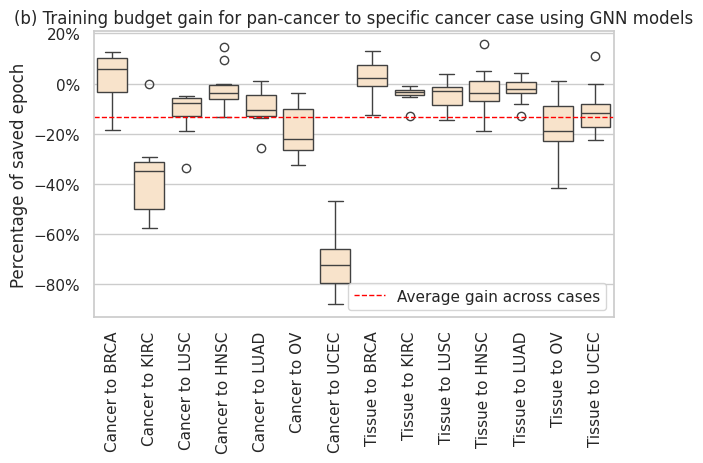

In [139]:
plt.figure()
sns.boxplot(data=diff_means_gnn, color="bisque")
all_values = [v for sublist in diff_means_gnn for v in sublist]
mean_val = np.mean(all_values)
plt.axhline(mean_val, linestyle='--', linewidth=1, color='red', label='Average gain across cases')
plt.legend()

plt.xticks(ticks=range(len(labels)), labels=labels, rotation=90)
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(100))
plt.ylabel("Percentage of saved epoch")

plt.title('(b) Training budget gain for pan-cancer to specific cancer case using GNN models')
plt.tight_layout()
#plt.savefig('pancancer_epoch_gain_gnn.png')
plt.show()

## Merge figures

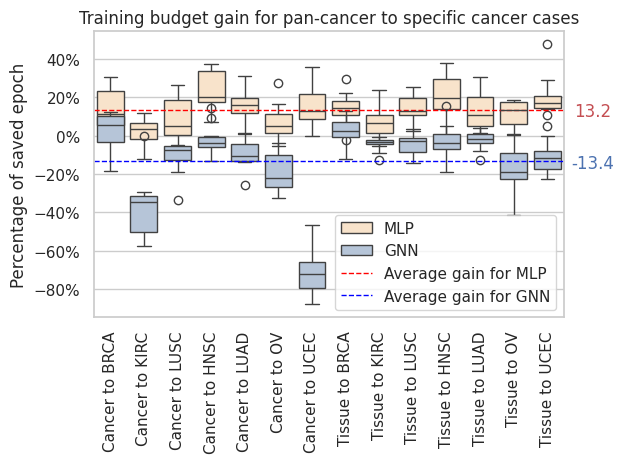

In [141]:
plt.figure()
sns.boxplot(data=diff_means, color="bisque", label='MLP')
sns.boxplot(data=diff_means_gnn, color="lightsteelblue", label='GNN')

all_values = [v for sublist in diff_means for v in sublist]
mean_val = np.mean(all_values)
plt.axhline(mean_val, linestyle='--', linewidth=1, color='red', label='Average gain for MLP')
plt.text(13.8, 10, np.round(mean_val, 1), c='r')

all_values = [v for sublist in diff_means_gnn for v in sublist]
mean_val = np.mean(all_values)
plt.axhline(mean_val, linestyle='--', linewidth=1, color='blue', label='Average gain for GNN')
plt.text(13.7, -17, np.round(mean_val, 1), c='b')

plt.legend(loc='lower right')

plt.xticks(ticks=range(len(labels)), labels=labels, rotation=90)
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(100))
plt.ylabel("Percentage of saved epoch")

plt.title('Training budget gain for pan-cancer to specific cancer cases')
plt.tight_layout()
plt.savefig('pancancer_epoch_gain_merged.png')
plt.show()

In [117]:
labels

['cancer to BRCA',
 'cancer to KIRC',
 'cancer to LUSC',
 'cancer to HNSC',
 'cancer to LUAD',
 'cancer to UCEC',
 'tissue to BRCA',
 'tissue to KIRC',
 'tissue to LUSC',
 'tissue to LUAD',
 'tissue to OV',
 'tissue to UCEC']

## Intertask

### MLP

In [56]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col("epoch").max().alias(f"epoch"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)
    return all_data

def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='epoch')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", "epoch"])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df

#tasks = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model', 'radiation_model', 'pharma_model']
source_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
target_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df = pl.DataFrame()
df_dict = {}
df_prop_dict_epoch = {}

for source_task in source_tasks: 
    for target_task in target_tasks:
        if source_task != target_task:
            print(f'{source_task}-{target_task}-----')
            df_baseline = pl.DataFrame()
            df_finetuned = pl.DataFrame()
            for version in range(5):
                #print(version)
                baseline_str = 'intertask/mlp/train_' + target_task + '_linspace_training'
                finetuned_str = 'intertask/mlp/' + source_task + '_to_' + target_task + '_'
                df_temp_baseline = get_df(baseline_str, version=version)
                df_temp_finetuned = get_df(finetuned_str, version=version)
                df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
                df_baseline = df_baseline.sort('train_samples')
                df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
                #print(df_finetuned)
                df_finetuned = df_finetuned.sort('train_samples')
            
            #print(df_baseline['train_samples'])
            #print(list(df_finetuned['train_samples']))
            #print(df_baseline)
            print('-----')
            df = df_baseline.with_columns(df_finetuned['epoch'].alias('epoch_finetuned'))
            df_prop_dict_epoch[(source_task, target_task)] = df

tissue_model-cancer_model-----
-----
tissue_model-stage_model-----
-----
tissue_model-aa5_model-----
-----
tissue_model-radiation_model-----
-----
tissue_model-pharma_model-----
-----
cancer_model-tissue_model-----
-----
cancer_model-stage_model-----
-----
cancer_model-aa5_model-----
-----
cancer_model-radiation_model-----
-----
cancer_model-pharma_model-----
-----
stage_model-tissue_model-----
-----
stage_model-cancer_model-----
-----
stage_model-aa5_model-----
-----
stage_model-radiation_model-----
-----
stage_model-pharma_model-----
-----
aa5_model-tissue_model-----
-----
aa5_model-cancer_model-----
-----
aa5_model-stage_model-----
-----
aa5_model-radiation_model-----
-----
aa5_model-pharma_model-----
-----
radiation_model-tissue_model-----
-----
radiation_model-cancer_model-----
-----
radiation_model-stage_model-----
-----
radiation_model-aa5_model-----
-----
radiation_model-pharma_model-----
-----
pharma_model-tissue_model-----
-----
pharma_model-cancer_model-----
-----
pharma_mod

In [57]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    #print(df.columns)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col(column).max().alias(f"max_{column}"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)

    return all_data

def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", metric])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df

def get_mauc(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", metric])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    mauc = auc(df['train_samples'], df['max_test_accuracy'])
    return mauc

def compute_macc(source_task, target_task, v=0, metric="max_test_accuracy"):
    baseline_str = 'train_' + target_task + '_linspace_training'
    finetuned_str = source_task + '_to_' + target_task + '_'
    auc_baseline = compute_aupc(baseline_str, version = v, metric=metric)
    auc_finetuned = compute_aupc_multitask(finetuned_str, version = v, metric=metric)
    return auc_finetuned - auc_baseline, auc_finetuned, auc_baseline

#tasks = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model', 'radiation_model', 'pharma_model']
source_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
target_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df = pl.DataFrame()
df_dict = {}
df_prop_dict = {}

for source_task in source_tasks: 
    for target_task in target_tasks:
        if source_task != target_task:
            print(f'{source_task}-{target_task}-----')
            df_baseline = pl.DataFrame()
            df_finetuned = pl.DataFrame()
            for version in range(5):
                #print(version)
                baseline_str = 'intertask/mlp/train_' + target_task + '_linspace_training'
                finetuned_str = 'intertask/mlp/' + source_task + '_to_' + target_task + '_'
                df_temp_baseline = get_df(baseline_str, version=version)
                df_temp_finetuned = get_df(finetuned_str, version=version)
                df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
                df_baseline = df_baseline.sort('train_samples')
                df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
                #print(df_finetuned)
                df_finetuned = df_finetuned.sort('train_samples')
            
            #print(df_baseline['train_samples'])
            #print(list(df_finetuned['train_samples']))
            print('-----')
            df = df_baseline.with_columns(df_finetuned['max_test_accuracy'].alias('max_test_accuracy_finetuned'))
            result_prop = (
                df
                .group_by("train_samples")
                .agg(
                    pl.col("max_test_accuracy").alias("accuracy_list")
                )
                .sort("train_samples")  # optional
            )
            result_prop_finetuned = (
                df
                .group_by("train_samples")
                .agg(
                    pl.col("max_test_accuracy_finetuned").alias("accuracy_list_finetuned")
                )
                .sort("train_samples")  # optional
            )
            result_prop = result_prop.with_columns(result_prop_finetuned["accuracy_list_finetuned"])
            #s = pl.Series("train_samples", [f"p_{i}" for i in range(len(result_prop['train_samples']))])
            #result_prop.replace_column(0, s)
            #print(result_prop)
            df_prop_dict[(source_task, target_task)] = result_prop

tissue_model-cancer_model-----
-----
tissue_model-stage_model-----
-----
tissue_model-aa5_model-----
-----
tissue_model-radiation_model-----
-----
tissue_model-pharma_model-----
-----
cancer_model-tissue_model-----
-----
cancer_model-stage_model-----
-----
cancer_model-aa5_model-----
-----
cancer_model-radiation_model-----
-----
cancer_model-pharma_model-----
-----
stage_model-tissue_model-----
-----
stage_model-cancer_model-----
-----
stage_model-aa5_model-----
-----
stage_model-radiation_model-----
-----
stage_model-pharma_model-----
-----
aa5_model-tissue_model-----
-----
aa5_model-cancer_model-----
-----
aa5_model-stage_model-----
-----
aa5_model-radiation_model-----
-----
aa5_model-pharma_model-----
-----
radiation_model-tissue_model-----
-----
radiation_model-cancer_model-----
-----
radiation_model-stage_model-----
-----
radiation_model-aa5_model-----
-----
radiation_model-pharma_model-----
-----
pharma_model-tissue_model-----
-----
pharma_model-cancer_model-----
-----
pharma_mod

In [58]:
df_mauc = pd.DataFrame(columns=['source', 'target', 'mauc_mean', 'mauc_std', 'mauc_mean_finetuned', 'mauc_std_finetuned', 'p-value'])
df_mauc_save = pd.DataFrame(columns=['source', 'target', 'mauc', 'mauc_finetuned', 'p-value'])
source_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
target_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
source_list, target_list, mean_list, std_list = [], [], [], []
mean_finetuned_list, std_finetuned_list = [], []
p_value_list = []
mean_epoch_list = []
mean_epoch_finetuned_list = []

mean_list_prop, mean_list_prop_finetuned = [], []
std_list_prop, std_list_prop_finetuned = [], []
p_value_prop = []
for source_task in source_tasks:
    for target_task in target_tasks:
        if source_task != target_task:
            source_list.append(source_task)
            target_list.append(target_task)
            perf_matrix = np.array([row for row in df_prop_dict[(source_task,target_task)]['accuracy_list']])
            prop_matrix = np.array([row for row in df_prop_dict[(source_task,target_task)]['train_samples']])
            mauc = [auc(prop_matrix, perf_matrix[:,i]) for i in range(perf_matrix.shape[1])]
            mean_list.append(np.mean(mauc))
            std_list.append(np.std(mauc))
            perf_matrix_finetuned = np.array([row for row in df_prop_dict[(source_task,target_task)]['accuracy_list_finetuned']])
            prop_matrix_finetuned = np.array([row for row in df_prop_dict[(source_task,target_task)]['train_samples']])
            mauc_finetuned = [auc(prop_matrix_finetuned, perf_matrix_finetuned[:,i]) for i in range(perf_matrix_finetuned.shape[1])]
            mean_finetuned_list.append(np.mean(mauc_finetuned))
            std_finetuned_list.append(np.std(mauc_finetuned))
            t_stat, p_value = stats.ttest_rel(mauc, mauc_finetuned)
            p_value_list.append(p_value)

            epoch_matrix = np.array([row for row in df_prop_dict_epoch[(source_task,target_task)].group_by('train_samples').mean()['epoch']])
            #print(df_prop_dict_epoch[(source_task,target_task)].group_by('train_samples').mean())
            epoch_finetuned_matrix = np.array([row for row in df_prop_dict_epoch[(source_task,target_task)].group_by('train_samples').mean()['epoch_finetuned']])
            mean_epoch_list.append(epoch_matrix)
            mean_epoch_finetuned_list.append(epoch_finetuned_matrix)
            
            mean_list_prop.append(np.mean(perf_matrix, axis=1))
            mean_list_prop_finetuned.append(np.mean(perf_matrix_finetuned, axis=1))
            std_list_prop.append(np.std(perf_matrix, axis=1))
            std_list_prop_finetuned.append(np.std(perf_matrix_finetuned, axis=1))
            p_value_prop.append([stats.ttest_rel(perf_matrix[i], perf_matrix_finetuned[i])[1] for i in range(perf_matrix.shape[0])])

df_mauc['source'] = source_list
df_mauc['target'] = target_list
df_mauc['mauc_mean'] = mean_list
df_mauc['mauc_std'] = std_list
df_mauc['mauc_mean_finetuned'] = mean_finetuned_list
df_mauc['mauc_std_finetuned'] = std_finetuned_list
df_mauc['p-value'] = p_value_list
df_mauc['mean_by_prop'] = mean_list_prop
df_mauc['std_by_prop'] = std_list_prop
df_mauc['mean_by_prop_finetuned'] = mean_list_prop_finetuned
df_mauc['std_by_prop_finetuned'] = std_list_prop_finetuned
df_mauc['p-value_by_prop'] = p_value_prop
df_mauc['mean_epoch'] = mean_epoch_list
df_mauc['mean_epoch_finetuned'] = mean_epoch_finetuned_list

df_mauc_save['source'] = source_list
df_mauc_save['target'] = target_list
df_mauc_save['mauc'] = [f'{np.round(mean, 4)} ± {np.round(std, 4)}' for mean, std in zip(mean_list, std_list)]
df_mauc_save['mauc_finetuned'] = [f'{np.round(mean, 4)} ± {np.round(std, 4)}' for mean, std in zip(mean_finetuned_list, std_finetuned_list)]
df_mauc_save['p-value'] = p_value_list

In [59]:
df_mauc

,source,target,mauc_mean,mauc_std,mauc_mean_finetuned,mauc_std_finetuned,p-value,mean_by_prop,std_by_prop,mean_by_prop_finetuned,std_by_prop_finetuned,p-value_by_prop,mean_epoch,mean_epoch_finetuned
0,tissue_model,cancer_model,0.892086,0.002985,0.912005,0.020764,0.113226,"[0.934331550802139, 0.9309090909090909, 0.9381...","[0.006500351400651426, 0.005133689839572186, 0...","[0.9388215701641158, 0.942348561681726, 0.9740...","[0.009062527725637199, 0.01926819896385627, 0....","[0.4769033048322851, 0.2777483206794329, 0.081...","[47.4, 28.4, 34.2, 27.8, 35.4, 32.6, 24.6, 29....","[37.2, 23.6, 33.6, 33.0, 31.4, 33.4, 27.2, 26...."
1,tissue_model,stage_model,0.618408,0.016452,0.643284,0.007019,0.055126,"[0.5848208011243851, 0.6220660576247364, 0.645...","[0.04202459826849227, 0.012175071161044385, 0....","[0.593289026065291, 0.6482587203730914, 0.6815...","[0.03821215591509089, 0.01972029361147665, 0.0...","[0.8016904961811738, 0.15377848169299896, 0.01...","[18.2, 14.8, 13.8, 13.2, 10.8, 10.0, 9.0, 9.2,...","[21.4, 16.2, 17.4, 15.0, 14.0, 12.2, 12.2, 12...."
2,tissue_model,aa5_model,0.674594,0.008734,0.687931,0.003668,0.071170,"[0.6370030581039756, 0.6706422018348623, 0.694...","[0.031671683125076185, 0.040554194688624486, 0...","[0.6565749235474007, 0.6834862385321101, 0.724...","[0.0277530307144671, 0.02598488781192413, 0.00...","[0.4922760504199709, 0.6428265086939635, 0.005...","[27.0, 22.2, 17.6, 18.0, 14.4, 16.8, 13.0, 12....","[18.2, 12.2, 15.0, 14.2, 13.0, 13.2, 11.2, 10...."
3,tissue_model,radiation_model,0.629579,0.007803,0.644587,0.012021,0.082298,"[0.6071866783523225, 0.6536371603856266, 0.668...","[0.03692815167681317, 0.02366280389929705, 0.0...","[0.6690622261174408, 0.6885188431200702, 0.692...","[0.040245337698103414, 0.025259268890074273, 0...","[0.1353009101195007, 0.06461843410077639, 0.17...","[21.0, 16.0, 12.6, 14.8, 11.8, 9.4, 9.2, 8.8, ...","[27.2, 17.6, 15.2, 12.4, 11.8, 10.0, 10.0, 9.0..."
4,tissue_model,pharma_model,0.670929,0.012790,0.675382,0.009599,0.672987,"[0.6553900087642419, 0.7007887817703768, 0.705...","[0.013039589772758821, 0.01798357514977123, 0....","[0.6906222611744084, 0.7006134969325154, 0.722...","[0.03627591607213748, 0.014170995920356005, 0....","[0.05064415639443779, 0.9898767970288792, 0.34...","[29.6, 17.6, 15.0, 11.6, 11.0, 9.4, 8.8, 9.8, ...","[31.6, 18.6, 16.6, 13.6, 12.2, 11.4, 10.8, 10...."
5,cancer_model,tissue_model,0.813222,0.006487,0.813176,0.001200,0.987434,"[0.5210695187165776, 0.7649197860962567, 0.852...","[0.035087060763935904, 0.039843842860501084, 0...","[0.3836206896551725, 0.7939655172413793, 0.800...","[0.030304896949700816, 0.010605331694238872, 0...","[0.00016445363399571623, 0.25517392190913696, ...","[50.0, 47.2, 50.0, 50.0, 50.0, 50.0, 50.0, 50....","[50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50...."
6,cancer_model,stage_model,0.618408,0.016452,0.613017,0.012147,0.695351,"[0.5848208011243851, 0.6220660576247364, 0.645...","[0.04202459826849227, 0.012175071161044385, 0....","[0.5783555867884751, 0.6283907238229094, 0.642...","[0.031178253088370737, 0.01985363711244806, 0....","[0.6210803150985831, 0.6354689950904495, 0.873...","[18.2, 14.8, 13.8, 13.2, 10.8, 10.0, 9.0, 9.2,...","[16.6, 12.8, 14.6, 11.6, 11.2, 10.4, 10.2, 9.4..."
7,cancer_model,aa5_model,0.674594,0.008734,0.676406,0.003300,0.765984,"[0.6370030581039756, 0.6706422018348623, 0.694...","[0.031671683125076185, 0.040554194688624486, 0...","[0.6688073394495413, 0.6467889908256881, 0.691...","[0.01439584378708234, 0.0, 0.02503913087517886...","[0.1389588869157047, 0.30467816512034085, 0.83...","[27.0, 22.2, 17.6, 18.0, 14.4, 16.8, 13.0, 12....","[28.4, 9.0, 14.0, 13.0, 12.8, 12.8, 10.6, 12.4..."
8,cancer_model,radiation_model,0.629579,0.007803,0.619177,0.009555,0.154620,"[0.6071866783523225, 0.6536371603856266, 0.668...","[0.03692815167681317, 0.02366280389929705, 0.0...","[0.6259421560035057, 0.624715162138475, 0.6499...","[0.03269144463277761, 0.019772254025877047, 0....","[0.5062126541707248, 0.10

In [60]:
df_mauc['mean_epoch']

0     [47.4, 28.4, 34.2, 27.8, 35.4, 32.6, 24.6, 29....
1     [18.2, 14.8, 13.8, 13.2, 10.8, 10.0, 9.0, 9.2,...
2     [27.0, 22.2, 17.6, 18.0, 14.4, 16.8, 13.0, 12....
3     [21.0, 16.0, 12.6, 14.8, 11.8, 9.4, 9.2, 8.8, ...
4     [29.6, 17.6, 15.0, 11.6, 11.0, 9.4, 8.8, 9.8, ...
5     [50.0, 47.2, 50.0, 50.0, 50.0, 50.0, 50.0, 50....
6     [18.2, 14.8, 13.8, 13.2, 10.8, 10.0, 9.0, 9.2,...
7     [27.0, 22.2, 17.6, 18.0, 14.4, 16.8, 13.0, 12....
8     [21.0, 16.0, 12.6, 14.8, 11.8, 9.4, 9.2, 8.8, ...
9     [29.6, 17.6, 15.0, 11.6, 11.0, 9.4, 8.8, 9.8, ...
10    [50.0, 47.2, 50.0, 50.0, 50.0, 50.0, 50.0, 50....
11    [47.4, 28.4, 34.2, 27.8, 35.4, 32.6, 24.6, 29....
12    [27.0, 22.2, 17.6, 18.0, 14.4, 16.8, 13.0, 12....
13    [21.0, 16.0, 12.6, 14.8, 11.8, 9.4, 9.2, 8.8, ...
14    [29.6, 17.6, 15.0, 11.6, 11.0, 9.4, 8.8, 9.8, ...
15    [50.0, 47.2, 50.0, 50.0, 50.0, 50.0, 50.0, 50....
16    [47.4, 28.4, 34.2, 27.8, 35.4, 32.6, 24.6, 29....
17    [18.2, 14.8, 13.8, 13.2, 10.8, 10.0, 9.0, 

In [61]:
diff_means = []
epoch_means, epoch_means_finetuned = [], []
labels = []

for i in range(len(df_mauc.index)):
    row = df_mauc.iloc[i]
    source, target = row['source'], row['target']
    p_value = row['p-value']
    mauc_baseline, mauc_finetuned = row['mauc_mean'], row['mauc_mean_finetuned']
    #if p_value < 0.5:
    if mauc_baseline < mauc_finetuned and p_value < 0.06:
        print(f'{source} to {target} beneficial: {mauc_baseline} vs {mauc_finetuned}')
        epoch_baseline_prop, epoch_finetuned_prop = row['mean_epoch'], row['mean_epoch_finetuned']
        diff_prop = epoch_baseline_prop - epoch_finetuned_prop 
        print(diff_prop)
        print(diff_prop.mean())
        diff_means.append(diff_prop)
        labels.append(f'{source.split("_")[0]} to {target.split("_")[0]}')
#diff_means = np.concatenate(diff_means)
#print(np.mean(diff_means))

tissue_model to stage_model beneficial: 0.6184081166549544 vs 0.6432840360698628
[-3.2 -1.4 -3.6 -1.8 -3.2 -2.2 -3.2 -3.  -3.2 -2.4]
-2.7199999999999998
stage_model to aa5_model beneficial: 0.6745943877468292 vs 0.6944524437266709
[-2.6  4.8 -0.8  3.8  0.2  3.4  1.6  0.6  1.2  1.   0.2]
1.2181818181818185
stage_model to radiation_model beneficial: 0.6295788781770376 vs 0.6429958369851008
[ 5.  -0.4 -0.2  2.4  1.  -1.4  0.2 -1.  -0.2 -0.4]
0.5
pharma_model to radiation_model beneficial: 0.6295788781770376 vs 0.6427944785276074
[-5.2 -4.2 -3.4 -0.2 -0.4 -0.4 -1.  -1.2 -1.  -1. ]
-1.7999999999999996


In [63]:
diff_means_best_mtl = []
epoch_means, epoch_means_finetuned = [], []
labels_best_mtl = []
list_best_mtl = [('cancer_model', 'tissue_model'), ('tissue_model', 'cancer_model'), ('stage_model', 'aa5_model'), ('tissue_model', 'stage_model')]

for i in range(len(df_mauc.index)):
    row = df_mauc.iloc[i]
    source, target = row['source'], row['target']
    p_value = row['p-value']
    mauc_baseline, mauc_finetuned = row['mauc_mean'], row['mauc_mean_finetuned']
    #if p_value < 0.5:
    if (source, target) in list_best_mtl:
        print(f'{source} to {target} beneficial: {mauc_baseline} vs {mauc_finetuned}')
        epoch_baseline_prop, epoch_finetuned_prop = row['mean_epoch'], row['mean_epoch_finetuned']
        diff_prop = epoch_baseline_prop - epoch_finetuned_prop 
        print(diff_prop)
        print(diff_prop.mean())
        diff_means_best_mtl.append(diff_prop)
        labels_best_mtl.append(f'{source.split("_")[0]} to {target.split("_")[0]}')
#diff_means = np.concatenate(diff_means)
#print(np.mean(diff_means))

tissue_model to cancer_model beneficial: 0.8920862299465242 vs 0.9120046440652084
[10.2  4.8  0.6 -5.2  4.  -0.8 -2.6  3.6 -2.6 -6.2]
0.5800000000000001
tissue_model to stage_model beneficial: 0.6184081166549544 vs 0.6432840360698628
[-3.2 -1.4 -3.6 -1.8 -3.2 -2.2 -3.2 -3.  -3.2 -2.4]
-2.7199999999999998
cancer_model to tissue_model beneficial: 0.8132223930481283 vs 0.8131755792025862
[ 0.  -2.8  0.   0.   0.   0.   0.   0.   0.   0. ]
-0.2799999999999997
stage_model to aa5_model beneficial: 0.6745943877468292 vs 0.6944524437266709
[-2.6  4.8 -0.8  3.8  0.2  3.4  1.6  0.6  1.2  1.   0.2]
1.2181818181818185


#### Boxplot

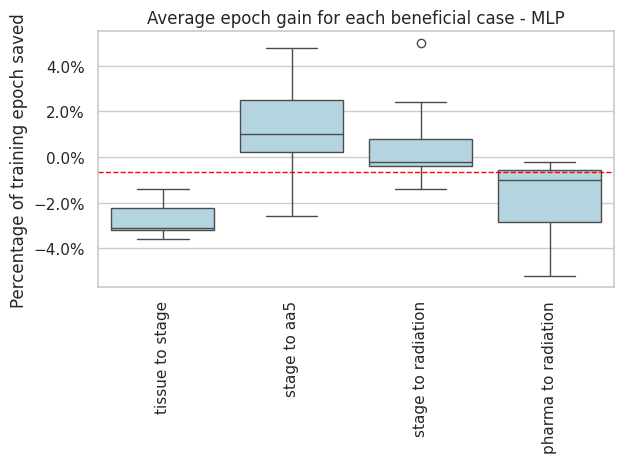

In [195]:
plt.figure()
sns.boxplot(data=diff_means, label='Number of epoch saved', color="lightblue")
all_values = [v for sublist in diff_means for v in sublist]
mean_val = np.mean(all_values)
plt.axhline(mean_val, linestyle='--', linewidth=1, color='red', label='Global Mean')

plt.xticks(ticks=range(len(labels)), labels=labels, rotation=90)
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(100))
plt.ylabel("Percentage of training epoch saved")

plt.title('Average epoch gain for each beneficial case - MLP')
plt.tight_layout()
plt.savefig('intertask_epoch_gain_mlp.png')
plt.show()

### GNN

In [147]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col("epoch").max().alias(f"epoch"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)
    return all_data

def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='epoch')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", "epoch"])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df

#tasks = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model', 'radiation_model', 'pharma_model']
source_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
target_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df = pl.DataFrame()
df_dict = {}
df_prop_dict_epoch = {}

for source_task in source_tasks: 
    for target_task in target_tasks:
        if source_task != target_task:
            print(f'{source_task}-{target_task}-----')
            df_baseline = pl.DataFrame()
            df_finetuned = pl.DataFrame()
            for version in range(5):
                #print(version)
                baseline_str = 'intertask/gnn/train_GNN_' + target_task + '_linspace_training'
                finetuned_str = 'intertask/gnn/GNN_' + source_task + '_to_' + target_task + '_'
                df_temp_baseline = get_df(baseline_str, version=version)
                df_temp_finetuned = get_df(finetuned_str, version=version)
                df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
                df_baseline = df_baseline.sort('train_samples')
                df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
                #print(df_finetuned)
                df_finetuned = df_finetuned.sort('train_samples')
            
            #print(df_baseline['train_samples'])
            #print(list(df_finetuned['train_samples']))
            #print(df_baseline)
            print('-----')
            df = df_baseline.with_columns(df_finetuned['epoch'].alias('epoch_finetuned'))
            df_prop_dict_epoch[(source_task, target_task)] = df

tissue_model-cancer_model-----
-----
tissue_model-stage_model-----
-----
tissue_model-aa5_model-----
-----
tissue_model-radiation_model-----
-----
tissue_model-pharma_model-----
-----
cancer_model-tissue_model-----
-----
cancer_model-stage_model-----
-----
cancer_model-aa5_model-----
-----
cancer_model-radiation_model-----
-----
cancer_model-pharma_model-----
-----
stage_model-tissue_model-----
-----
stage_model-cancer_model-----
-----
stage_model-aa5_model-----
-----
stage_model-radiation_model-----
-----
stage_model-pharma_model-----
-----
aa5_model-tissue_model-----
-----
aa5_model-cancer_model-----
-----
aa5_model-stage_model-----
-----
aa5_model-radiation_model-----
-----
aa5_model-pharma_model-----
-----
radiation_model-tissue_model-----
-----
radiation_model-cancer_model-----
-----
radiation_model-stage_model-----
-----
radiation_model-aa5_model-----
-----
radiation_model-pharma_model-----
-----
pharma_model-tissue_model-----
-----
pharma_model-cancer_model-----
-----
pharma_mod

In [148]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    #print(df.columns)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col(column).max().alias(f"max_{column}"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)

    return all_data

def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", metric])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df

def get_mauc(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", metric])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    mauc = auc(df['train_samples'], df['max_test_accuracy'])
    return mauc

def compute_macc(source_task, target_task, v=0, metric="max_test_accuracy"):
    baseline_str = 'train_' + target_task + '_linspace_training'
    finetuned_str = source_task + '_to_' + target_task + '_'
    auc_baseline = compute_aupc(baseline_str, version = v, metric=metric)
    auc_finetuned = compute_aupc_multitask(finetuned_str, version = v, metric=metric)
    return auc_finetuned - auc_baseline, auc_finetuned, auc_baseline

#tasks = ['tissue_model', 'cancer_model', 'aa5_model', 'stage_model', 'radiation_model', 'pharma_model']
source_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
target_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df = pl.DataFrame()
df_dict = {}
df_prop_dict = {}

for source_task in source_tasks: 
    for target_task in target_tasks:
        if source_task != target_task:
            print(f'{source_task}-{target_task}-----')
            df_baseline = pl.DataFrame()
            df_finetuned = pl.DataFrame()
            for version in range(5):
                #print(version)
                baseline_str = 'intertask/gnn/train_GNN_' + target_task + '_linspace_training'
                finetuned_str = 'intertask/gnn/GNN_' + source_task + '_to_' + target_task + '_'
                df_temp_baseline = get_df(baseline_str, version=version)
                df_temp_finetuned = get_df(finetuned_str, version=version)
                df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
                df_baseline = df_baseline.sort('train_samples')
                df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
                #print(df_finetuned)
                df_finetuned = df_finetuned.sort('train_samples')
            
            #print(df_baseline['train_samples'])
            #print(list(df_finetuned['train_samples']))
            print('-----')
            df = df_baseline.with_columns(df_finetuned['max_test_accuracy'].alias('max_test_accuracy_finetuned'))
            result_prop = (
                df
                .group_by("train_samples")
                .agg(
                    pl.col("max_test_accuracy").alias("accuracy_list")
                )
                .sort("train_samples")  # optional
            )
            result_prop_finetuned = (
                df
                .group_by("train_samples")
                .agg(
                    pl.col("max_test_accuracy_finetuned").alias("accuracy_list_finetuned")
                )
                .sort("train_samples")  # optional
            )
            result_prop = result_prop.with_columns(result_prop_finetuned["accuracy_list_finetuned"])
            #s = pl.Series("train_samples", [f"p_{i}" for i in range(len(result_prop['train_samples']))])
            #result_prop.replace_column(0, s)
            #print(result_prop)
            df_prop_dict[(source_task, target_task)] = result_prop

tissue_model-cancer_model-----
-----
tissue_model-stage_model-----
-----
tissue_model-aa5_model-----
-----
tissue_model-radiation_model-----
-----
tissue_model-pharma_model-----
-----
cancer_model-tissue_model-----
-----
cancer_model-stage_model-----
-----
cancer_model-aa5_model-----
-----
cancer_model-radiation_model-----
-----
cancer_model-pharma_model-----
-----
stage_model-tissue_model-----
-----
stage_model-cancer_model-----
-----
stage_model-aa5_model-----
-----
stage_model-radiation_model-----
-----
stage_model-pharma_model-----
-----
aa5_model-tissue_model-----
-----
aa5_model-cancer_model-----
-----
aa5_model-stage_model-----
-----
aa5_model-radiation_model-----
-----
aa5_model-pharma_model-----
-----
radiation_model-tissue_model-----
-----
radiation_model-cancer_model-----
-----
radiation_model-stage_model-----
-----
radiation_model-aa5_model-----
-----
radiation_model-pharma_model-----
-----
pharma_model-tissue_model-----
-----
pharma_model-cancer_model-----
-----
pharma_mod

In [149]:
df_mauc = pd.DataFrame(columns=['source', 'target', 'mauc_mean', 'mauc_std', 'mauc_mean_finetuned', 'mauc_std_finetuned', 'p-value'])
df_mauc_save = pd.DataFrame(columns=['source', 'target', 'mauc', 'mauc_finetuned', 'p-value'])
source_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
target_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model', 'radiation_model', 'pharma_model']
source_list, target_list, mean_list, std_list = [], [], [], []
mean_finetuned_list, std_finetuned_list = [], []
p_value_list = []
mean_epoch_list = []
mean_epoch_finetuned_list = []

mean_list_prop, mean_list_prop_finetuned = [], []
std_list_prop, std_list_prop_finetuned = [], []
p_value_prop = []
for source_task in source_tasks:
    for target_task in target_tasks:
        if source_task != target_task:
            source_list.append(source_task)
            target_list.append(target_task)
            perf_matrix = np.array([row for row in df_prop_dict[(source_task,target_task)]['accuracy_list']])
            prop_matrix = np.array([row for row in df_prop_dict[(source_task,target_task)]['train_samples']])
            mauc = [auc(prop_matrix, perf_matrix[:,i]) for i in range(perf_matrix.shape[1])]
            mean_list.append(np.mean(mauc))
            std_list.append(np.std(mauc))
            perf_matrix_finetuned = np.array([row for row in df_prop_dict[(source_task,target_task)]['accuracy_list_finetuned']])
            prop_matrix_finetuned = np.array([row for row in df_prop_dict[(source_task,target_task)]['train_samples']])
            mauc_finetuned = [auc(prop_matrix_finetuned, perf_matrix_finetuned[:,i]) for i in range(perf_matrix_finetuned.shape[1])]
            mean_finetuned_list.append(np.mean(mauc_finetuned))
            std_finetuned_list.append(np.std(mauc_finetuned))
            t_stat, p_value = stats.ttest_rel(mauc, mauc_finetuned)
            p_value_list.append(p_value)

            epoch_matrix = np.array([row for row in df_prop_dict_epoch[(source_task,target_task)].group_by('train_samples').mean()['epoch']])
            #print(df_prop_dict_epoch[(source_task,target_task)].group_by('train_samples').mean())
            epoch_finetuned_matrix = np.array([row for row in df_prop_dict_epoch[(source_task,target_task)].group_by('train_samples').mean()['epoch_finetuned']])
            mean_epoch_list.append(epoch_matrix)
            mean_epoch_finetuned_list.append(epoch_finetuned_matrix)
            
            mean_list_prop.append(np.mean(perf_matrix, axis=1))
            mean_list_prop_finetuned.append(np.mean(perf_matrix_finetuned, axis=1))
            std_list_prop.append(np.std(perf_matrix, axis=1))
            std_list_prop_finetuned.append(np.std(perf_matrix_finetuned, axis=1))
            p_value_prop.append([stats.ttest_rel(perf_matrix[i], perf_matrix_finetuned[i])[1] for i in range(perf_matrix.shape[0])])

df_mauc['source'] = source_list
df_mauc['target'] = target_list
df_mauc['mauc_mean'] = mean_list
df_mauc['mauc_std'] = std_list
df_mauc['mauc_mean_finetuned'] = mean_finetuned_list
df_mauc['mauc_std_finetuned'] = std_finetuned_list
df_mauc['p-value'] = p_value_list
df_mauc['mean_by_prop'] = mean_list_prop
df_mauc['std_by_prop'] = std_list_prop
df_mauc['mean_by_prop_finetuned'] = mean_list_prop_finetuned
df_mauc['std_by_prop_finetuned'] = std_list_prop_finetuned
df_mauc['p-value_by_prop'] = p_value_prop
df_mauc['mean_epoch'] = mean_epoch_list
df_mauc['mean_epoch_finetuned'] = mean_epoch_finetuned_list

df_mauc_save['source'] = source_list
df_mauc_save['target'] = target_list
df_mauc_save['mauc'] = [f'{np.round(mean, 4)} ± {np.round(std, 4)}' for mean, std in zip(mean_list, std_list)]
df_mauc_save['mauc_finetuned'] = [f'{np.round(mean, 4)} ± {np.round(std, 4)}' for mean, std in zip(mean_finetuned_list, std_finetuned_list)]
df_mauc_save['p-value'] = p_value_list

In [150]:
diff_means = []
epoch_means, epoch_means_finetuned = [], []
labels = []

for i in range(len(df_mauc.index)):
    row = df_mauc.iloc[i]
    source, target = row['source'], row['target']
    p_value = row['p-value']
    mauc_baseline, mauc_finetuned = row['mauc_mean'], row['mauc_mean_finetuned']
    #if p_value < 0.5:
    if mauc_baseline < mauc_finetuned and p_value < 0.05:
        print(f'{source} to {target} beneficial: {mauc_baseline} vs {mauc_finetuned}')
        epoch_baseline_prop, epoch_finetuned_prop = row['mean_epoch'], row['mean_epoch_finetuned']
        diff_prop = epoch_baseline_prop - epoch_finetuned_prop 
        print(diff_prop)
        print(diff_prop.mean())
        diff_means.append(diff_prop)
        labels.append(f'{source.split("_")[0]} to {target.split("_")[0]}')
#diff_means = np.concatenate(diff_means)
#print(np.mean(diff_means))

cancer_model to tissue_model beneficial: 0.7730097593582889 vs 0.8179593582887701
[-3.2 -6.6 -4.  -1.   2.4  0.6  1.8  0.   4.6 -0.6]
-0.6000000000000002
stage_model to tissue_model beneficial: 0.7730097593582889 vs 0.8059142379679145
[-2.6 -7.8 -9.2 -5.8 -8.2 -3.2 -1.8 -4.2  1.8 -5. ]
-4.6
stage_model to cancer_model beneficial: 0.8995237299465242 vs 0.9032220588235294
[-6.  -3.  -1.  -3.4  0.4 -1.4  0.6 -1.   0.  -1.6]
-1.64
stage_model to aa5_model beneficial: 0.6547361696193749 vs 0.6869688449576957
[-0.6 -0.4  0.6  2.4  2.8  3.4  1.6  0.6  0.6  0.   0.6]
1.0545454545454545
aa5_model to tissue_model beneficial: 0.7730097593582889 vs 0.8089601604278075
[-0.8 -4.8 -7.6 -2.  -0.4  0.8  1.6  0.2  5.4  0.2]
-0.7399999999999999
radiation_model to tissue_model beneficial: 0.7730097593582889 vs 0.8028505347593582
[-22.   -6.8  -7.4   1.6   2.    0.    2.6   0.6   6.6   0.6]
-2.22
pharma_model to tissue_model beneficial: 0.7730097593582889 vs 0.8016592914438503
[-3.6 -7.8 -6.8 -1.4 -1.4  0.

#### Boxplot

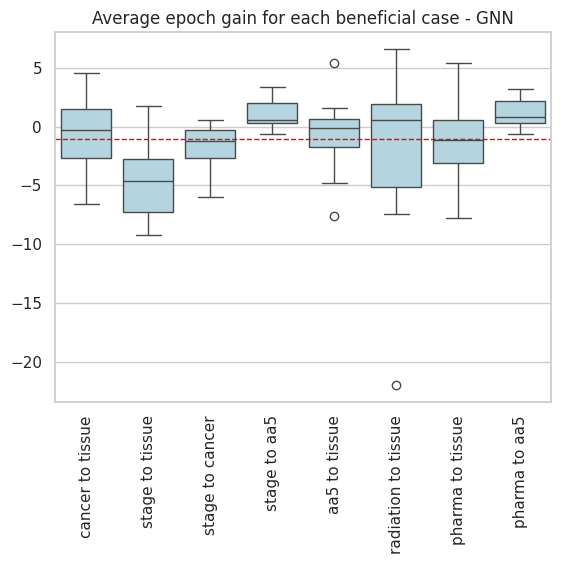

In [151]:
plt.figure()
sns.boxplot(data=diff_means, label='Number of epoch saved', color="lightblue")
all_values = [v for sublist in diff_means for v in sublist]
mean_val = np.mean(all_values)
plt.axhline(mean_val, linestyle='--', linewidth=1, color='red', label='Global Mean')

plt.xticks(ticks=range(len(labels)), labels=labels, rotation=90)
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(100))
plt.ylabel("Percentage")

plt.title('Average epoch gain for each beneficial case - GNN')
plt.savefig('intertask_epoch_gain_gnn.png')
plt.show()

## Multitask 

### MLP

In [65]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col("epoch").max().alias(f"epoch"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)
    return all_data

def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='epoch')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", "epoch"])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df

tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model']
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df = pl.DataFrame()
df_dict = {}
df_prop_dict_epoch = {}

for model in permutations(tasks, 3):
    group_task_str = '_'.join(model)
    #print(group_task_str)
    for target in tasks:
        if os.path.isdir(f'../../logs/{group_task_str}_to_{target}_'):
            print('combination exists')
            print(f'{group_task_str} to {target}-----')
            df_baseline = pl.DataFrame()
            df_finetuned = pl.DataFrame()
            for version in range(4):
                #print(version)
                baseline_str = 'intertask/mlp/' + 'train_' + target + '_linspace_training'
                group_task_finetuned_str = group_task_str + '_to_' + target + '_'
                df_temp_baseline = get_df(baseline_str, version=version)
                df_temp_finetuned = get_df(group_task_finetuned_str, version=version)
                df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
                df_baseline = df_baseline.sort('train_samples')
                df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
                #print(df_finetuned)
                df_finetuned = df_finetuned.sort('train_samples')
            
            #print(df_baseline['train_samples'])
            #print(list(df_finetuned['train_samples']))
            #print(df_baseline)
            print('-----')
            df = df_baseline.with_columns(df_finetuned['epoch'].alias('epoch_finetuned'))
            df_prop_dict_epoch[(group_task_str, target)] = df

combination exists
cancer_model_stage_model_tissue_model to aa5_model-----
-----
combination exists
aa5_model_cancer_model_tissue_model to stage_model-----
-----
combination exists
aa5_model_cancer_model_stage_model to tissue_model-----
-----
combination exists
aa5_model_stage_model_tissue_model to cancer_model-----
-----


In [66]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col(column).max().alias(f"max_{column}"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)

    return all_data

def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", metric])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df


log_df = pd.DataFrame(columns=['source', 'target', 'baseline aupc', 'pretrained aupc', 'p-value'])
i = 0
models = ['aa5_model', 'cancer_model', 'stage_model', 'tissue_model']
version = 0
df_prop_dict = {}

for model in permutations(models, 3):
    #print(model)
    for target in models:
        group_task_str = '_'.join(model)
        #print(f'../../logs/{group_task_str}_to_{target}')
        if os.path.isdir(f'../../logs/{group_task_str}_to_{target}_'):
            print('combination exists')
            df_baseline = pl.DataFrame()
            df_finetuned = pl.DataFrame()
            for version in range(4):
                baseline_str = 'intertask/mlp/train_' + target + '_linspace_training'
                group_task_finetuned_str = group_task_str + '_to_' + target + '_'
                df_temp_baseline = get_df(baseline_str, version=version)
                df_temp_finetuned = get_df(group_task_finetuned_str, version=version)
                df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
                df_baseline = df_baseline.sort('train_samples')
                df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
                print(df_baseline.shape)
                print(df_finetuned.shape)
                df_finetuned = df_finetuned.sort('train_samples')
            df = df_baseline.with_columns(df_finetuned['max_test_accuracy'].alias('max_test_accuracy_finetuned'))
            result_prop = (
                df
                .group_by("train_samples")
                .agg(
                    pl.col("max_test_accuracy").alias("accuracy_list")
                )
                .sort("train_samples")  # optional
            )
            result_prop_finetuned = (
                df
                .group_by("train_samples")
                .agg(
                    pl.col("max_test_accuracy_finetuned").alias("accuracy_list_finetuned")
                )
                .sort("train_samples")  # optional
            )
            result_prop = result_prop.with_columns(result_prop_finetuned["accuracy_list_finetuned"])
            df_prop_dict[(group_task_str, target)] = result_prop
        else: 
            #print("combination does not exist")
            continue

combination exists
(10, 2)
(10, 2)
(20, 2)
(20, 2)
(30, 2)
(30, 2)
(40, 2)
(40, 2)
combination exists
(10, 2)
(10, 2)
(20, 2)
(20, 2)
(30, 2)
(30, 2)
(40, 2)
(40, 2)
combination exists
(10, 2)
(10, 2)
(20, 2)
(20, 2)
(30, 2)
(30, 2)
(40, 2)
(40, 2)
combination exists
(11, 2)
(11, 2)
(22, 2)
(22, 2)
(33, 2)
(33, 2)
(44, 2)
(44, 2)


In [76]:
df_mauc = pd.DataFrame(columns=['source', 'target', 'mauc_mean', 'mauc_std', 'mauc_mean_finetuned', 'mauc_std_finetuned', 'p-value'])
df_mauc_save = pd.DataFrame(columns=['source', 'target', 'mauc', 'mauc_finetuned', 'p-value'])
source_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model']
target_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model']
source_list, target_list, mean_list, std_list = [], [], [], []
mean_finetuned_list, std_finetuned_list = [], []
p_value_list = []
mean_epoch_list = []
mean_epoch_finetuned_list = []

mean_list_prop, mean_list_prop_finetuned = [], []
std_list_prop, std_list_prop_finetuned = [], []
p_value_prop = []

for model in permutations(tasks, 3):
    group_task_str = '_'.join(model)
    #print(group_task_str)
    for target_task in tasks:
        if os.path.isdir(f'../../logs/{group_task_str}_to_{target_task}_'):
            print(group_task_str)
            source_list.append(group_task_str)
            target_list.append(target_task)
            perf_matrix = np.array([row for row in df_prop_dict[(group_task_str,target_task)]['accuracy_list']])
            prop_matrix = np.array([row for row in df_prop_dict[(group_task_str,target_task)]['train_samples']])
            mauc = [auc(prop_matrix, perf_matrix[:,i]) for i in range(perf_matrix.shape[1])]
            mean_list.append(np.mean(mauc))
            std_list.append(np.std(mauc))
            perf_matrix_finetuned = np.array([row for row in df_prop_dict[(group_task_str,target_task)]['accuracy_list_finetuned']])
            prop_matrix_finetuned = np.array([row for row in df_prop_dict[(group_task_str,target_task)]['train_samples']])
            mauc_finetuned = [auc(prop_matrix_finetuned, perf_matrix_finetuned[:,i]) for i in range(perf_matrix_finetuned.shape[1])]
            mean_finetuned_list.append(np.mean(mauc_finetuned))
            std_finetuned_list.append(np.std(mauc_finetuned))
            t_stat, p_value = stats.ttest_rel(mauc, mauc_finetuned)
            p_value_list.append(p_value)

            epoch_matrix = np.array([row for row in df_prop_dict_epoch[(group_task_str,target_task)].group_by('train_samples').mean()['epoch']])
            #print(df_prop_dict_epoch[(source_task,target_task)].group_by('train_samples').mean())
            epoch_finetuned_matrix = np.array([row for row in df_prop_dict_epoch[(group_task_str,target_task)].group_by('train_samples').mean()['epoch_finetuned']])
            mean_epoch_list.append(epoch_matrix)
            mean_epoch_finetuned_list.append(epoch_finetuned_matrix)
            
            mean_list_prop.append(np.mean(perf_matrix, axis=1))
            mean_list_prop_finetuned.append(np.mean(perf_matrix_finetuned, axis=1))
            std_list_prop.append(np.std(perf_matrix, axis=1))
            std_list_prop_finetuned.append(np.std(perf_matrix_finetuned, axis=1))
            p_value_prop.append([stats.ttest_rel(perf_matrix[i], perf_matrix_finetuned[i])[1] for i in range(perf_matrix.shape[0])])

df_mauc['source'] = source_list
df_mauc['target'] = target_list
df_mauc['mauc_mean'] = mean_list
df_mauc['mauc_std'] = std_list
df_mauc['mauc_mean_finetuned'] = mean_finetuned_list
df_mauc['mauc_std_finetuned'] = std_finetuned_list
df_mauc['p-value'] = p_value_list
df_mauc['mean_by_prop'] = mean_list_prop
df_mauc['std_by_prop'] = std_list_prop
df_mauc['mean_by_prop_finetuned'] = mean_list_prop_finetuned
df_mauc['std_by_prop_finetuned'] = std_list_prop_finetuned
df_mauc['p-value_by_prop'] = p_value_prop
df_mauc['mean_epoch'] = mean_epoch_list
df_mauc['mean_epoch_finetuned'] = mean_epoch_finetuned_list

df_mauc_save['source'] = source_list
df_mauc_save['target'] = target_list
df_mauc_save['mauc'] = [f'{np.round(mean, 4)} ± {np.round(std, 4)}' for mean, std in zip(mean_list, std_list)]
df_mauc_save['mauc_finetuned'] = [f'{np.round(mean, 4)} ± {np.round(std, 4)}' for mean, std in zip(mean_finetuned_list, std_finetuned_list)]
df_mauc_save['p-value'] = p_value_list

cancer_model_stage_model_tissue_model
aa5_model_cancer_model_tissue_model
aa5_model_cancer_model_stage_model
aa5_model_stage_model_tissue_model


In [77]:
df_mauc

,source,target,mauc_mean,mauc_std,mauc_mean_finetuned,mauc_std_finetuned,p-value,mean_by_prop,std_by_prop,mean_by_prop_finetuned,std_by_prop_finetuned,p-value_by_prop,mean_epoch,mean_epoch_finetuned
0,cancer_model_stage_model_tissue_model,aa5_model,0.676616,0.008655,0.702375,0.014210,0.045656,"[0.6521406727828747, 0.6834862385321101, 0.689...","[0.010398677758972057, 0.035084996653161345, 0...","[0.6716360856269112, 0.7247706422018348, 0.744...","[0.014720848252270411, 0.010084790487976248, 0...","[0.1683225680718467, 0.12261287219979483, 0.04...","[28.75, 21.25, 18.25, 17.75, 14.75, 15.75, 11....","[24.0, 21.75, 18.0, 15.5, 15.5, 12.75, 11.5, 1..."
1,aa5_model_cancer_model_tissue_model,stage_model,0.614890,0.016627,0.630377,0.013316,0.025261,"[0.5771257905832747, 0.620695713281799, 0.6386...","[0.043720906193675906, 0.013262776071754927, 0...","[0.629304286718201, 0.6681307097680956, 0.6716...","[0.0379951426251673, 0.011678770101630554, 0.0...","[0.0054390159372219166, 0.005934004097054228, ...","[15.25, 15.75, 13.25, 13.5, 11.0, 9.75, 9.0, 9...","[21.75, 23.75, 17.5, 16.75, 13.75, 11.5, 11.75..."
2,aa5_model_cancer_model_stage_model,tissue_model,0.814633,0.006531,0.791639,0.004130,0.023343,"[0.5335561497326203, 0.7823529411764706, 0.849...","[0.027555353756777572, 0.02156015508087641, 0....","[0.40040106951871657, 0.7356951871657755, 0.82...","[0.02183487028216722, 0.04951128800495532, 0.0...","[0.003742287011230332, 0.33113871631624037, 0....","[50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50....","[50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 47.5, 50...."
3,aa5_model_stage_model_tissue_model,cancer_model,0.892660,0.003080,0.904863,0.002751,0.017019,"[0.9330213903743315, 0.9315508021390374, 0.937...","[0.00665098554215653, 0.0055573822702744665, 0...","[0.9409090909090909, 0.9557486631016042, 0.961...","[0.004623426862510845, 0.006629452549848903, 0...","[0.30601894012142195, 0.010049547377989184, 0....","[46.75, 29.5, 35.25, 30.25, 37.75, 34.75, 26.0...","[6.0, 10.0, 18.25, 13.25, 12.25, 10.5, 10.75, ..."


#### Boxplot

In [82]:
diff_means = []
epoch_means, epoch_means_finetuned = [], []
labels = []

for i in range(len(df_mauc.index)):
    row = df_mauc.iloc[i]
    source, target = row['source'], row['target']
    p_value = row['p-value']
    mauc_baseline, mauc_finetuned = row['mauc_mean'], row['mauc_mean_finetuned']
    #if p_value < 0.5:
    if p_value < 1.5:
        print(f'{source} to {target} beneficial: {mauc_baseline} vs {mauc_finetuned}')
        epoch_baseline_prop, epoch_finetuned_prop = row['mean_epoch'], row['mean_epoch_finetuned']
        diff_prop = epoch_baseline_prop - epoch_finetuned_prop 
        print(diff_prop)
        print(diff_prop.mean())
        diff_means.append(diff_prop)
        if target == 'aa5_model': 
            labels.append(f'AA5 as target')
        else: labels.append(f'{target.split("_")[0].capitalize()} as target')
#diff_means = np.concatenate(diff_means)
#print(np.mean(diff_means))

cancer_model_stage_model_tissue_model to aa5_model beneficial: 0.6766162468664975 vs 0.7023750166201302
[ 4.75 -0.5   0.25  2.25 -0.75  3.    0.25  0.75  1.    0.5   0.25]
1.0681818181818181
aa5_model_cancer_model_tissue_model to stage_model beneficial: 0.6148903065706255 vs 0.6303771741040056
[-6.5  -8.   -4.25 -3.25 -2.75 -1.75 -2.75 -1.75 -2.5  -1.  ]
-3.45
aa5_model_cancer_model_stage_model to tissue_model beneficial: 0.814632520053476 vs 0.7916394552139037
[0.  0.  0.  0.  0.  0.  2.5 0.  7.  0. ]
0.95
aa5_model_stage_model_tissue_model to cancer_model beneficial: 0.8926603442513369 vs 0.9048628843582888
[40.75 19.5  17.   17.   25.5  24.25 15.25 20.   13.75 15.  ]
20.8


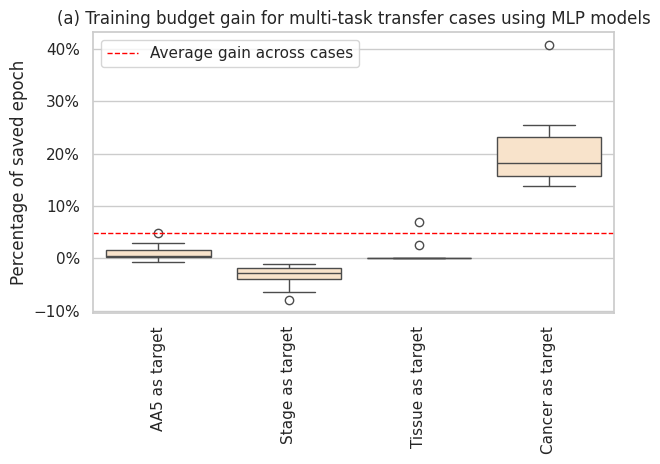

In [83]:
plt.figure()
sns.boxplot(data=diff_means, color="bisque")
all_values = [v for sublist in diff_means for v in sublist]
mean_val = np.mean(all_values)
plt.axhline(mean_val, linestyle='--', linewidth=1, color='red', label='Average gain across cases')
plt.legend()

plt.xticks(ticks=range(len(labels)), labels=labels, rotation=90)
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(100))
plt.ylabel("Percentage of saved epoch")


plt.title('(a) Training budget gain for multi-task transfer cases using MLP models')
plt.tight_layout()
plt.savefig('multitask_epoch_gain_mlp.png')
plt.show()

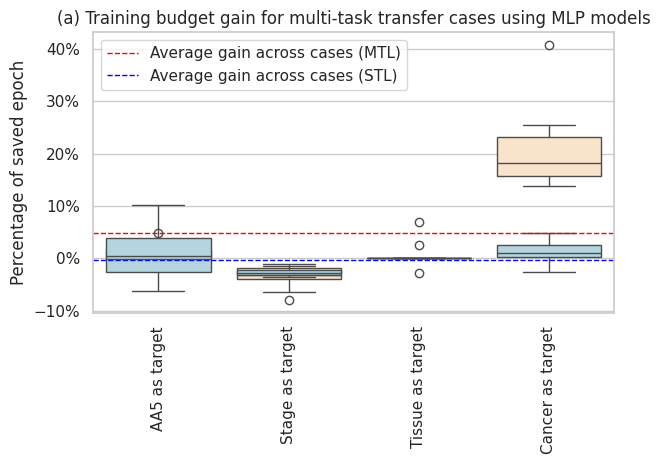

In [84]:
plt.figure()
sns.boxplot(data=diff_means, color="bisque")
sns.boxplot(data=diff_means_best_mtl, color="lightblue")
all_values = [v for sublist in diff_means for v in sublist]
mean_val = np.mean(all_values)
plt.axhline(mean_val, linestyle='--', linewidth=1, color='red', label='Average gain across cases (MTL)')

all_values = [v for sublist in diff_means_best_mtl for v in sublist]
mean_val = np.mean(all_values)
plt.axhline(mean_val, linestyle='--', linewidth=1, color='blue', label='Average gain across cases (STL)')
plt.legend()

plt.xticks(ticks=range(len(labels)), labels=labels, rotation=90)
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(100))
plt.ylabel("Percentage of saved epoch")


plt.title('(a) Training budget gain for multi-task transfer cases using MLP models')
plt.tight_layout()
#plt.savefig('multitask_epoch_gain_mlp.png')
plt.show()

### GNN

In [50]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col("epoch").max().alias(f"epoch"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)
    return all_data

def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='epoch')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", "epoch"])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df

tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model']
df_baseline = pl.DataFrame()
df_finetuned = pl.DataFrame()
df = pl.DataFrame()
df_dict = {}
df_prop_dict_epoch = {}

for model in permutations(tasks, 3):
    group_task_str = '_'.join(model)
    #print(group_task_str)
    for target in tasks:
        if os.path.isdir(f'../../logs/GNN_{group_task_str}_to_{target}_'):
            print('combination exists')
            print(f'{group_task_str} to {target}-----')
            df_baseline = pl.DataFrame()
            df_finetuned = pl.DataFrame()
            for version in range(4):
                #print(version)
                baseline_str = 'intertask/gnn/' + 'train_GNN_' + target + '_linspace_training'
                group_task_finetuned_str = 'GNN_' + group_task_str + '_to_' + target + '_'
                df_temp_baseline = get_df(baseline_str, version=version)
                df_temp_finetuned = get_df(group_task_finetuned_str, version=version)
                df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
                df_baseline = df_baseline.sort('train_samples')
                df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
                #print(df_finetuned)
                df_finetuned = df_finetuned.sort('train_samples')
            
            #print(df_baseline['train_samples'])
            #print(list(df_finetuned['train_samples']))
            #print(df_baseline)
            print('-----')
            df = df_baseline.with_columns(df_finetuned['epoch'].alias('epoch_finetuned'))
            df_prop_dict_epoch[(group_task_str, target)] = df

combination exists
cancer_model_stage_model_tissue_model to aa5_model-----
-----
combination exists
aa5_model_cancer_model_tissue_model to stage_model-----
-----
combination exists
aa5_model_cancer_model_stage_model to tissue_model-----
-----
combination exists
aa5_model_stage_model_tissue_model to cancer_model-----
-----


In [52]:
def load_and_process_data(experiment_name, version, column="test_accuracy"):
    all_data = []

    csv_path = Path(f"{BASE_PATH}/{experiment_name}/version_{version}/metrics.csv")
    #print(csv_path)
    if not csv_path.exists():
        print(f"Fichier manquant : {csv_path}")
    #print(csv_path)
    df = pl.read_csv(csv_path)
    grouped = (
        df.group_by(["train_samples"])
        .agg(pl.col(column).max().alias(f"max_{column}"))
        .sort("train_samples")
    ).filter(pl.col("train_samples").is_not_null())

    all_data.append(grouped)

    return all_data

def get_df(source_file, version, metric="max_test_accuracy"):
    baseline_data_acc = load_and_process_data(source_file, version, column='test_accuracy')
    #baseline_data_acc = load_and_process_data(source_file, version, column='Roc_auc')
    df = pl.DataFrame(baseline_data_acc[0]).select(["train_samples", metric])
    df = df.filter(pl.col("train_samples") < 1000)
    #print(df)
    df = (df.filter(pl.col("train_samples") < 1000).with_columns((pl.col("train_samples") / df['train_samples'].max()).alias("train_samples")))
    return df


log_df = pd.DataFrame(columns=['source', 'target', 'baseline aupc', 'pretrained aupc', 'p-value'])
i = 0
models = ['aa5_model', 'cancer_model', 'stage_model', 'tissue_model']
version = 0
df_prop_dict = {}

for model in permutations(models, 3):
    #print(model)
    for target in models:
        group_task_str = '_'.join(model)
        #print(f'../../logs/{group_task_str}_to_{target}')
        if os.path.isdir(f'../../logs/GNN_{group_task_str}_to_{target}_'):
            print('combination exists')
            df_baseline = pl.DataFrame()
            df_finetuned = pl.DataFrame()
            for version in range(4):
                baseline_str = 'intertask/gnn/train_GNN_' + target + '_linspace_training'
                group_task_finetuned_str = 'GNN_' + group_task_str + '_to_' + target + '_'
                df_temp_baseline = get_df(baseline_str, version=version)
                df_temp_finetuned = get_df(group_task_finetuned_str, version=version)
                df_baseline = pl.concat([df_baseline, df_temp_baseline], how='vertical')
                df_baseline = df_baseline.sort('train_samples')
                df_finetuned = pl.concat([df_finetuned, df_temp_finetuned], how='vertical')
                print(df_baseline.shape)
                print(df_finetuned.shape)
                df_finetuned = df_finetuned.sort('train_samples')
            df = df_baseline.with_columns(df_finetuned['max_test_accuracy'].alias('max_test_accuracy_finetuned'))
            result_prop = (
                df
                .group_by("train_samples")
                .agg(
                    pl.col("max_test_accuracy").alias("accuracy_list")
                )
                .sort("train_samples")  # optional
            )
            result_prop_finetuned = (
                df
                .group_by("train_samples")
                .agg(
                    pl.col("max_test_accuracy_finetuned").alias("accuracy_list_finetuned")
                )
                .sort("train_samples")  # optional
            )
            result_prop = result_prop.with_columns(result_prop_finetuned["accuracy_list_finetuned"])
            df_prop_dict[(group_task_str, target)] = result_prop
        else: 
            #print("combination does not exist")
            continue

combination exists
(10, 2)
(10, 2)
(20, 2)
(20, 2)
(30, 2)
(30, 2)
(40, 2)
(40, 2)
combination exists
(10, 2)
(10, 2)
(20, 2)
(20, 2)
(30, 2)
(30, 2)
(40, 2)
(40, 2)
combination exists
(10, 2)
(10, 2)
(20, 2)
(20, 2)
(30, 2)
(30, 2)
(40, 2)
(40, 2)
combination exists
(11, 2)
(11, 2)
(22, 2)
(22, 2)
(33, 2)
(33, 2)
(44, 2)
(44, 2)


In [53]:
df_mauc = pd.DataFrame(columns=['source', 'target', 'mauc_mean', 'mauc_std', 'mauc_mean_finetuned', 'mauc_std_finetuned', 'p-value'])
df_mauc_save = pd.DataFrame(columns=['source', 'target', 'mauc', 'mauc_finetuned', 'p-value'])
source_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model']
target_tasks = ['tissue_model', 'cancer_model','stage_model', 'aa5_model']
source_list, target_list, mean_list, std_list = [], [], [], []
mean_finetuned_list, std_finetuned_list = [], []
p_value_list = []
mean_epoch_list = []
mean_epoch_finetuned_list = []

mean_list_prop, mean_list_prop_finetuned = [], []
std_list_prop, std_list_prop_finetuned = [], []
p_value_prop = []

for model in permutations(tasks, 3):
    group_task_str = '_'.join(model)
    #print(group_task_str)
    for target_task in tasks:
        if os.path.isdir(f'../../logs/{group_task_str}_to_{target_task}_'):
            print(group_task_str)
            source_list.append(source_task)
            target_list.append(target_task)
            perf_matrix = np.array([row for row in df_prop_dict[(group_task_str,target_task)]['accuracy_list']])
            prop_matrix = np.array([row for row in df_prop_dict[(group_task_str,target_task)]['train_samples']])
            mauc = [auc(prop_matrix, perf_matrix[:,i]) for i in range(perf_matrix.shape[1])]
            mean_list.append(np.mean(mauc))
            std_list.append(np.std(mauc))
            perf_matrix_finetuned = np.array([row for row in df_prop_dict[(group_task_str,target_task)]['accuracy_list_finetuned']])
            prop_matrix_finetuned = np.array([row for row in df_prop_dict[(group_task_str,target_task)]['train_samples']])
            mauc_finetuned = [auc(prop_matrix_finetuned, perf_matrix_finetuned[:,i]) for i in range(perf_matrix_finetuned.shape[1])]
            mean_finetuned_list.append(np.mean(mauc_finetuned))
            std_finetuned_list.append(np.std(mauc_finetuned))
            t_stat, p_value = stats.ttest_rel(mauc, mauc_finetuned)
            p_value_list.append(p_value)

            epoch_matrix = np.array([row for row in df_prop_dict_epoch[(group_task_str,target_task)].group_by('train_samples').mean()['epoch']])
            #print(df_prop_dict_epoch[(source_task,target_task)].group_by('train_samples').mean())
            epoch_finetuned_matrix = np.array([row for row in df_prop_dict_epoch[(group_task_str,target_task)].group_by('train_samples').mean()['epoch_finetuned']])
            mean_epoch_list.append(epoch_matrix)
            mean_epoch_finetuned_list.append(epoch_finetuned_matrix)
            
            mean_list_prop.append(np.mean(perf_matrix, axis=1))
            mean_list_prop_finetuned.append(np.mean(perf_matrix_finetuned, axis=1))
            std_list_prop.append(np.std(perf_matrix, axis=1))
            std_list_prop_finetuned.append(np.std(perf_matrix_finetuned, axis=1))
            p_value_prop.append([stats.ttest_rel(perf_matrix[i], perf_matrix_finetuned[i])[1] for i in range(perf_matrix.shape[0])])

df_mauc['source'] = source_list
df_mauc['target'] = target_list
df_mauc['mauc_mean'] = mean_list
df_mauc['mauc_std'] = std_list
df_mauc['mauc_mean_finetuned'] = mean_finetuned_list
df_mauc['mauc_std_finetuned'] = std_finetuned_list
df_mauc['p-value'] = p_value_list
df_mauc['mean_by_prop'] = mean_list_prop
df_mauc['std_by_prop'] = std_list_prop
df_mauc['mean_by_prop_finetuned'] = mean_list_prop_finetuned
df_mauc['std_by_prop_finetuned'] = std_list_prop_finetuned
df_mauc['p-value_by_prop'] = p_value_prop
df_mauc['mean_epoch'] = mean_epoch_list
df_mauc['mean_epoch_finetuned'] = mean_epoch_finetuned_list

df_mauc_save['source'] = source_list
df_mauc_save['target'] = target_list
df_mauc_save['mauc'] = [f'{np.round(mean, 4)} ± {np.round(std, 4)}' for mean, std in zip(mean_list, std_list)]
df_mauc_save['mauc_finetuned'] = [f'{np.round(mean, 4)} ± {np.round(std, 4)}' for mean, std in zip(mean_finetuned_list, std_finetuned_list)]
df_mauc_save['p-value'] = p_value_list

cancer_model_stage_model_tissue_model
aa5_model_cancer_model_tissue_model
aa5_model_cancer_model_stage_model
aa5_model_stage_model_tissue_model


#### Boxplot

In [54]:
diff_means = []
epoch_means, epoch_means_finetuned = [], []
labels = []

for i in range(len(df_mauc.index)):
    row = df_mauc.iloc[i]
    source, target = row['source'], row['target']
    p_value = row['p-value']
    mauc_baseline, mauc_finetuned = row['mauc_mean'], row['mauc_mean_finetuned']
    #if p_value < 0.5:
    if p_value < 1.5:
        print(f'{source} to {target} beneficial: {mauc_baseline} vs {mauc_finetuned}')
        epoch_baseline_prop, epoch_finetuned_prop = row['mean_epoch'], row['mean_epoch_finetuned']
        diff_prop = epoch_baseline_prop - epoch_finetuned_prop 
        print(diff_prop)
        print(diff_prop.mean())
        diff_means.append(diff_prop)
        labels.append(f'{source.split("_")[0]} to {target.split("_")[0]}')
#diff_means = np.concatenate(diff_means)
#print(np.mean(diff_means))

tissue_model to aa5_model beneficial: 0.6517334795904801 vs 0.6793871468830365
[0.   0.5  0.5  2.   2.5  3.5  1.75 1.   1.   1.25 1.25]
1.3863636363636365
tissue_model to stage_model beneficial: 0.594029778636683 vs 0.6131512429725932
[ 0.   -0.5  -0.25  8.    3.5   1.25  0.25  1.    0.75  1.  ]
1.5
tissue_model to tissue_model beneficial: 0.7726804812834225 vs 0.8040393549465239
[-1.25 -1.5  -4.5   0.75  0.25 -1.75  1.25 -1.25  3.5  -0.75]
-0.525
tissue_model to cancer_model beneficial: 0.8994263034759359 vs 0.9048628843582888
[ 3.   -1.25 -7.25 -3.75 -1.25  1.5   0.75  0.25  1.75  0.25]
-0.6


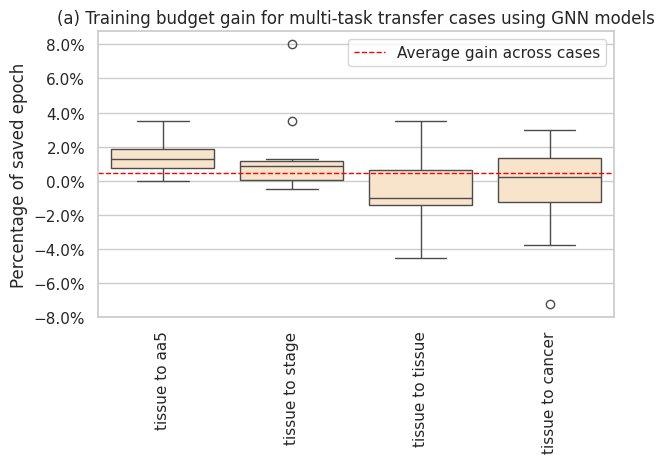

In [55]:
plt.figure()
sns.boxplot(data=diff_means, color="bisque")
all_values = [v for sublist in diff_means for v in sublist]
mean_val = np.mean(all_values)
plt.axhline(mean_val, linestyle='--', linewidth=1, color='red', label='Average gain across cases')
plt.legend()

plt.xticks(ticks=range(len(labels)), labels=labels, rotation=90)
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(100))
plt.ylabel("Percentage of saved epoch")


plt.title('(a) Training budget gain for multi-task transfer cases using GNN models')
plt.tight_layout()
plt.savefig('multitask_epoch_gain_gnn.png')
plt.show()